# Visión por Computador - Práctica 1 - Filtrado de Imágenes

#### 13 puntos   |   Fecha de entrega: 02 de Noviembre de 2025, 23:59   |   Forma de entrega: a través de la tarea creada en https://pradogrado2526.ugr.es/

### Estudiante: Jose María Martín Martín



---

## Normas de desarrollo y entrega de la práctica

1. Para este trabajo, al igual que para los demás, se debe presentar código, resultados, discusión de los mismos, y presentación y análisis del trabajo realizado, todo integrado en el propio Google Colab Notebook (es decir, no se entrega ninguna memoria separada en `.pdf` ni ningún código `.py`). Se recuerda que código y resultados sin informe explicativo no puntúa. Resulta también fundamental recordar que solo se acepta la entrega de ficheros `.ipynb` (no resulta válido entregar un fichero `.py`).

2. En relación con el punto anterior, se recuerda que se proporciona un Notebook, denominado `Ejemplo_Otsu.ipynb`, que muestra un ejemplo de respuesta y solución a un potencial ejercicio. El propósito de este Notebook es servir de referencia al alumnado acerca de cómo responder los ejercicios planteados. Véase que, por ejemplo, en aras de diferenciar con facilidad enunciados y respuestas, estas últimas se presentan en otro color (azul, en ese caso).

3. El diseño de celdas del documento debe ser respetado. Es decir, no se puede modificar el orden de los ejercicios o alterar la estructura del Notebook, de forma que dificulte localizar los contenidos. Aunque sí se puede, por ejemplo, crear nuevas subsecciones dentro de las secciones ya existentes para estructurar y organizar con más claridad las respuestas, así como para incluir los experimentos extra que se deseen.

4. Tal y como se muestra en `Ejemplo_Otsu.ipynb`, no hay ningún problema en emplear técnicas de IA generativa (como ChatGPT o Gemini) para crear el código de los distintos ejercicios o para enriquecer el análisis y descripción del trabajo realizado (aunque, obvia decirlo, su uso no es obligatorio). Pero, en caso de usarse, sí se debe aclarar de qué modo se ha usado la IA, con qué objetivo, y se debe demostrar que se entiende perfectamente lo que se ha hecho.

5. Solo se entregará el fichero `.ipynb` (incorporando código, resultados, y explicación del trabajo realizado y los resultados obtenidos) y no se enviarán las imágenes empleadas. El path para la lectura de imágenes, o cualquier otro fichero de entrada, debe ser siempre “/content/drive/My Drive/images/nombre_fichero”.

6. El código deberá  presentarse adecuadamente comentado y con los resultados obtenidos en cada apartado, junto con la presentación del trabajo realizado y la discusión y análisis de los resultados obtenidos. Es importante reiterar que la entrega de código sin informe explicativo o valoraciones no puntúa. Por otro lado, el código debe ir comentado en comentarios en celdas de código, mientras que el análisis y discusión, tanto del trabajo realizado como de los resultados obtenidos, debe ir en celdas de texto.

Este trabajo de implementación tiene como objetivo principal **familiarizarse con la implementación y uso de filtros de convolución, así como del cálculo de las derivadas de una imagen y sus posibles aplicaciones**.




### Materiales de Apoyo

En caso de que el alumnado tenga dudas sobre Python, OpenCV o el uso de Google Colab, se recuerda que en PRADO hay materiales de apoyo (https://pradogrado2526.ugr.es/mod/folder/view.php?id=95307):
-  Introducción a Python: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/1.%20Introduccion%20a%20Python.pdf
- Introducción a NumPy, Matplotlib y Scikit-learn: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/2.%20Introducción%20a%20Numpy%20Matplotlib%20y%20sklearn.pdf
- Notebook con toda la información anterior (y más cosas): https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/Guia_Python.ipynb
- Ejercicios y ejemplos de repaso: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/3.%20Ejercicios%20y%20ejemplos%20de%20repaso.pdf
- Fundamentos de Python para lectura, visualización y manipulación de imágenes: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/4.%20Fundamentos%20de%20Python%20para%20manipulacion%20de%20imagenes.pdf (y Notebook asociado: https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/Guia_fundamentos_imagenes.ipynb)
- Ideas sobre cómo redactar un documento académico-científico (útil para saber cómo documentar las respuestas a los ejercicios, el Notebook en su conjunto, y la memoria del proyecto final o de un TFG/TFM): https://pradogrado2526.ugr.es/pluginfile.php/243163/mod_folder/content/0/Algunas%20ideas%20sobre%20cómo%20elaborar%20un%20informe%20académico-científico.pdf
- Ejemplo de respuesta a un hipotético ejercicio sobre el algoritmo de umbralización de Otsu: https://pradogrado2526.ugr.es/pluginfile.php/243164/mod_folder/content/0/Ejemplo_Otsu.ipynb



---



## Funciones de apoyo y conexión con Google Drive

In [ ]:
# We start by getting access to the drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
# We import the main potential modules to use
import os,sys
import cv2, numpy as np, math
from matplotlib import pyplot as plt
# change directory
%cd '/content/drive/My Drive'
#  the current directory
%pwd

# This allows to display images  and to save  them in cells
%matplotlib inline
# this definition allows to read files in a specific path
get_image = lambda route: os.path.join('/content/drive/My Drive/images', route)

/content/drive/My Drive


Las funciones que se incluyen a continuación, se proporcionan como ayuda/apoyo para el estudiante. **En caso de que el alumnado prefiera utilizar otras funciones para lectura, normalización y visualización de imágenes, tiene total libertad para hacerlo, pero sí debe justificar y explicar razonadamente el motivo de dicho cambio y describir las modificaciones realizadas.**

Recuérdese que todas las imágenes a emplear durante las prácticas de todo el curso se pueden encontrar en el enlace de Google Drive indicado en PRADO: https://pradogrado2526.ugr.es/mod/url/view.php?id=95306 En concreto, https://drive.google.com/drive/folders/1UtvY8q6w1Cz9a9T9zxIqSweoRLgNwoW-

In [ ]:
'''
This function receives a string with the filename of the image to read,
and a flag indicating if we want to read it in color/RGB (flagColor=1) or gray level (flagColor=0)

Example of use:
im1=readIm(get_image('apple.jpg'),0)

'''
def readIm(filename, flagColor=1):
  # cv2 reads BGR format
  im=cv2.imread(filename)
  # change to  RGB and return the image
  if(flagColor):
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
  # change from BGR to grayscale instead if flag is 0
  return cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)

In [ ]:
'''
This function receives an array of arbitrary real numbers (that could include even negative values),
and returns an 'image' in the range [0,1].
flag_GLOBAL allows the user to normalize the whole image (including all channels) or to normalize
each channel/band independently.
'''
def rangeDisplay01(im, flag_GLOBAL= True):
  im = im.astype(float)
  if flag_GLOBAL:
    im = (im - im.min())/(im.max() - im.min())
  else:
    # bands normalization
    for band in range(im.shape[2]):
      im[:, :, band] = (im[:, :, band] - im[:, :, band].min())/(im[:, :, band].max() - im[:, :, band].min())
      # Note: remember that, for plt.imshow with RGB data, the valid range is [0..1] for floats and [0..255] for integers.
  return im

In [ ]:
'''
This function displays a single image, including a title, using a magnification factor.

Example of use:
im1=readIm(get_image('apple.jpg'),0)
displayIm(im1,'Manzana',0.5)

'''
def displayIm(im, title='Result',factor= 2):
  # First normalize range
  max=np.max(im)
  min=np.min(im)
  if min<0 or max>255:
    im=rangeDisplay01(im,flag_GLOBAL=True)
  if len(im.shape) == 3:
    # im es tribanda
    plt.imshow(im, cmap='jet')
  else:
    # im es monobanda
    plt.imshow(im, cmap='gray')
  figure_size = plt.gcf().get_size_inches()
  plt.gcf().set_size_inches(factor * figure_size)
  plt.title(title)
  plt.xticks([]), plt.yticks([]) # eliminamos numeración
  plt.show()

In [ ]:
'''
This function displays multiple images (including a title and using a magnification factor)
of equal size. The input to the function is a list of images.

Example of use:
im1=readIm(get_image('apple.jpg'),1)
images = [im1,im1,im1]

displayMI_ES(images, title='Manzanas',factor=1)

IMPORTANT NOTE: it is important to notice that this function stacks all images
and later call displayIm(). This implies that the normalization (rangeDisplay01()) is done
at the very end of the process. As a consequence, if the stacked images have different
range values they can be displayed in a "weird" way (with black regions (pixel value = 0)
looking grey). In case the visualization seems to be a problem, a possible solution
would be to create vim using vim.append(rangeDisplay01(...)). In this way, all images
would be on the same range of values (negative values around 0 (black),
0 values around 0.5 (grey), and positive values closer to 1 (white))

'''
def displayMI_ES(vim, title='Result',factor=2):
  # We set the maximun number of images to concatenate by columns
  maxcolumns=3
  # number of images to display
  numberim=len(vim)
  # The simplest case, one row: the maximum number of columns is larger than the images to stack
  # This is, by default, we put together the images column-wise
  if len(vim) < maxcolumns:
    out=vim[0]
    for item in range(1,len(vim)):
      #displayIm(out,str(item),1)
      out=np.hstack((out,vim[item]))

  # Else, if maxcolumns is smaller or equal than the number of images to stack
  else:
    # We check if all rows and columns are going to be 'busy', or if otherwise we need an extra-row
    if np.mod(len(vim),maxcolumns)== 0:
      maxrows=numberim//maxcolumns
    else:
      maxrows=numberim//maxcolumns+1

    # we build up the first block-row
    out=vim[0]
    for item in range(1,maxcolumns):
      out=np.hstack((out,vim[item]))
    # We build up the rest of block-rows
    for block in range(1,maxrows):
      #print(block)
      row=vim[block*maxcolumns]
      for item in range(1,maxcolumns):
        # We still have images to stack
        if block*maxcolumns+item < numberim:
          row=np.hstack((row,vim[block*maxcolumns+item]))
        # We do not have more images, and we have to fill with black
        else:
          row=np.hstack((row,np.zeros(vim[0].shape,dtype=vim[0].dtype)))
          #print(row.dtype)
          # if we don't include ',dtype=vim[0].dtype', np.zeros will include float
          # numbers in the matrix. This will make that the whole matrix will be
          # considered as floats, and values larger than 1 will be clipped to 1,
          # displaying an almost totally white image
      # add the new block-row
      out=np.vstack((out,row))
  return displayIm(out,title,factor)

# **Ejercicio 1: discretización de máscaras y filtrado Gaussiano** (5.5 puntos)

En este ejercicio aprenderemos a discretizar máscaras de convolución y a aplicarlas sobre imágenes empleando funciones de OpenCV. También buscamos hacerlo de un modo eficiente, y es por ello que, en toda la práctica, se exige el uso de convoluciones 1D (separables).





## A) (1.5 puntos)

En este apartado se deben realizar las siguientes tareas:

1. Calcular las máscaras discretas 1D de la Gaussiana, así como su primera y segunda derivadas (normalizadas), considerando que la entrada a dicha función de creación de máscaras 1D puede ser tanto un posible sigma como un posible tamaño de máscara.
2. Emplear los siguientes valores de sigma ($\{0.75, 1.5, 3, 6, 12\}$) y los siguientes valores de tamaño de máscara ($\{5,9,11,15\}$), y mostrar el perfil (es decir, la silueta de las máscaras como funciones 1D) para verificar que las máscaras creadas son correctas.
3. Describir/explicar/analizar si las formas de dichos kernels tienen sentido y se corresponden con lo que esperaríamos ver.

**<h1>RESPUESTA</h1>**
Vamos a proceder de la siguiente forma:
  - Definimos la función Gaussiana con media 0 e ignorando el valor constante que acompaña a la parte exponencial ( en realidad es constante respecto a **x** pero depende de **$\sigma$** ). La Gaussiana de estas caracteríticas tiene la siguiente forma:
  $$
  Gauss_σ(x) = e^{\frac{-x^2}{2σ^2}}
  $$

  - Calculamos la primera derivada de la Gaussiana:
    $$
  \frac{d}{dx}(e^{\frac{-x^2}{2σ^2}}) = \frac{-x}{σ^2}e^{\frac{-x^2}{2σ^2}}
  $$
  

  - Calculamos la segunda derivada de la Gaussiana:
    $$
  \frac{d}{dx}(\frac{-x}{σ^2}e^{\frac{-x^2}{2σ^2}}) = \frac{-1}{σ^2}e^{\frac{-x^2}{2σ^2}} + \frac{-x}{σ^2}\frac{-x}{σ^2}e^{\frac{-x^2}{2σ^2}} =
  \frac{x^2-σ^2}{σ^4}e^{\frac{-x^2}{2σ^2}}
  $$
  
  
  - Para calcular la máscara 1D de la Gaussiana, vamos a tener que calcular o bien $\sigma$ a partir del tamaño de máscara o bien el tamaño de máscara a partir de $σ$.  Si $σ$ > 0, se calcula el tamaño de máscara de la siguiente forma:
      - Obtenemos el valor **k** descrito previamente.
      - El tamaño de máscara será **2k +1**.

    Si por el contrario se proporciona un valor no válido de $σ$, es decir menor o igual que 0, si el tamaño de máscara es mayor que 0:
      - m_size = 2k+ 1 => m_size = 2(3$σ$) + 1 => $σ$ = $\frac{ msize - 1 }{6}$

      En caso de que se proporcionen valores no válidos, se devuelve por defecto la Gaussiana de $σ$ = 1 y m_size = 7.

  Para calular los valores a evaluar, tenemos que calcular ( como dicen las diapositivas ) el primer valor **k** tal que **k $\geq$ 3σ**. El vector de índices a evaluar es el vector **(-k, -k+1, ... k-1, k)**.

  Una vez calculados los parámetros de la Gaussiana y máscara, se devuelve el vector **(-k, -k+1, ... k-1, k)** evaluado en la Gaussiana de orden **order**. En el caso de que **order** sea 0, se normaliza el vector **(-Gauss(k), -Gauss(k+1), ...  Gauss(k))** dividiendo cada componente por la suma de las componentes del vector. En caso de que **order** sea >= 1, se multiplica cada componente por $σ^{order}$.
   


In [ ]:
# Funcion que calcula el valor de K a partir de sigma. Hay que calcular el
# primer valor entero k tal que k >= 3sigma
def GetK(sigma):
  return np.ceil(3*sigma)

def GaussFunc(x,sigma):

    # Se devuelve la función gaussiana e ^ ( -(x^2) / (2 sigma^2))
    return ( np.exp(-(x*x)/(2*sigma*sigma)) )


def GaussDeriv1Func(x,sigma):
    # Se devuelve la primera derivada
    return (-(x)/(sigma*sigma)) * GaussFunc(x,sigma)

def GaussDeriv2Func(x,sigma):
    # Se devuelve la segunda derivada
    return (x*x - sigma*sigma)/(sigma**4) * GaussFunc(x,sigma)

def gaussianMask1D(sigma=0, sizeMask=0, order=0):
    # order = 0 -> función Gaussiana
    # order = 1 -> derivada de la Gaussiana
    # order = 2 -> derivada segunda de la Gaussiana

    # Se calcula o bien sigma a partir de sizeMask o bien sizeMask a partir de
    # sigma. Para ello, dado un valor de sigma, tenemos que buscar el valor k
    # tal que k >= 3sigma y el tamaño de máscara será 2*k + 1.

    # En cambio si tenemos el tamaño de máscara, para calcular sigma tenemos
    # que sizeMask = 2k + 1 => T = 2 * 3sigma + 1 = > sigma = ( T - 1 ) / 6

    # En caso de que ambos valores sean negativos o 0, se toma por defecto
    # sigma = 1 y sizeMask = 7
    if sigma > 0:
      k = GetK(sigma)
      m_size = 2*k + 1
      sig = sigma
    elif sizeMask > 0:
      m_size = sizeMask
      sig = (m_size - 1) / 6
      k = GetK(sig)
    else:
      sig = 1
      k = GetK(sig)
      m_size = 2*k + 1

    # Calculamos el vector de los valores de máscara a evaluar.
    v_mask = np.arange(- k , k +1)

    # Por ultimo aplicamos la función pertinente dependiendo del parámetro order
    if order == 0:

      # En caso de Gaussiana clásica, se normaliza el vector dividiendo por la
      # suma de sus componentes
      mask = GaussFunc(v_mask,sig)
      mask = mask / np.sum(mask)
    elif order == 1:

      # Se normaliza multiplicando por sigma
      mask = sig * GaussDeriv1Func(v_mask,sig)
    elif order == 2:

      # Se normaliza multiplicando por sigma^2
      mask = sig * sig * GaussDeriv2Func(v_mask,sig)

    return mask

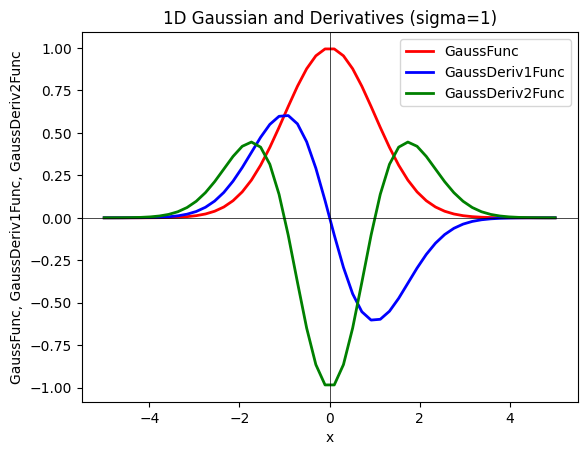

In [ ]:
# Con la siguiente figura verificamos que las funciones Gaussianas implementadas son correctas
plt.figure()
xvalues = np.linspace(-5, 5)
yvalues1 = GaussFunc(xvalues,1)
yvalues2 = GaussDeriv1Func(xvalues,1)
yvalues3 = GaussDeriv2Func(xvalues,1)
plt.plot(xvalues, yvalues1, lw=2, color='red',
label='GaussFunc')
plt.plot(xvalues, yvalues2, lw=2, color='blue',
label='GaussDeriv1Func')
plt.plot(xvalues, yvalues3, lw=2, color='green',
label='GaussDeriv2Func')
plt.title('1D Gaussian and Derivatives (sigma=1)')
plt.xlabel('x')
plt.ylabel('GaussFunc, GaussDeriv1Func, GaussDeriv2Func')
plt.axhline(0, lw=0.5, color='black')
plt.axvline(0, lw=0.5, color='black')
plt.legend();

Como vemos, las 3 funciones coinciden con la representación de la función gaussiana y derivadas, donde destaca que la derivada se hace 0 cuando empieza a decrecer la gaussiana y la segunda derivada se hace 0 en los puntos de inflexión.

FIJAMOS PRIMERO EL TAMAÑO DE LA MÁSCARA


/tmp/ipython-input-3554233243.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[i].legend();


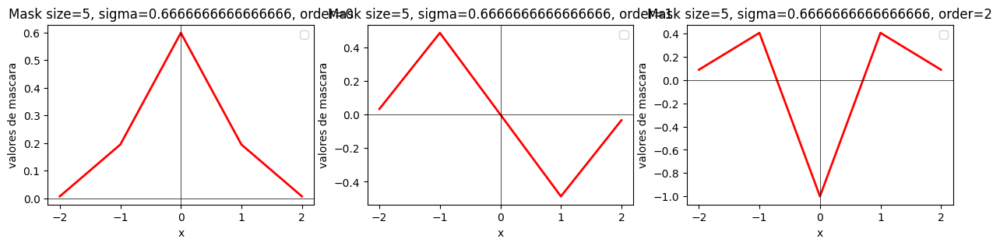

<Figure size 1500x300 with 0 Axes>

<Figure size 1500x300 with 0 Axes>

<Figure size 1500x300 with 0 Axes>

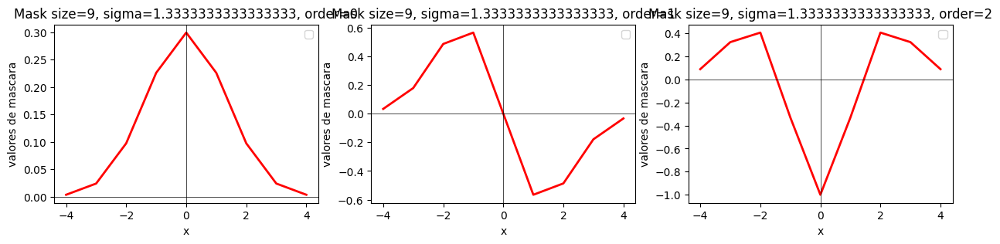

<Figure size 1500x300 with 0 Axes>

<Figure size 1500x300 with 0 Axes>

<Figure size 1500x300 with 0 Axes>

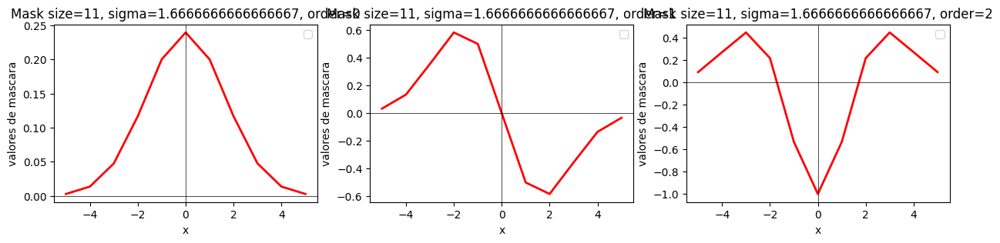

<Figure size 1500x300 with 0 Axes>

<Figure size 1500x300 with 0 Axes>

<Figure size 1500x300 with 0 Axes>

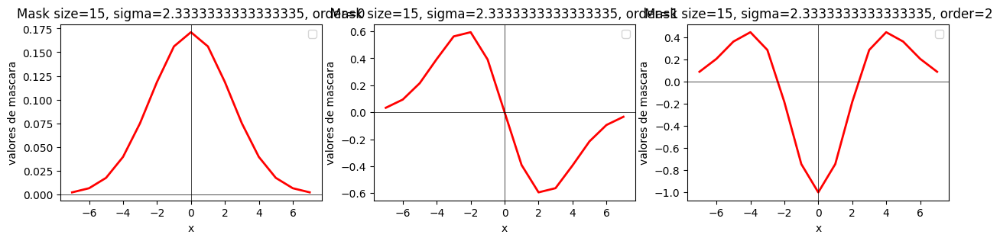

<Figure size 1500x300 with 0 Axes>

<Figure size 1500x300 with 0 Axes>

<Figure size 1500x300 with 0 Axes>

FIJAMOS AHORA EL SIGMA


/tmp/ipython-input-3554233243.py:36: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[i].legend();


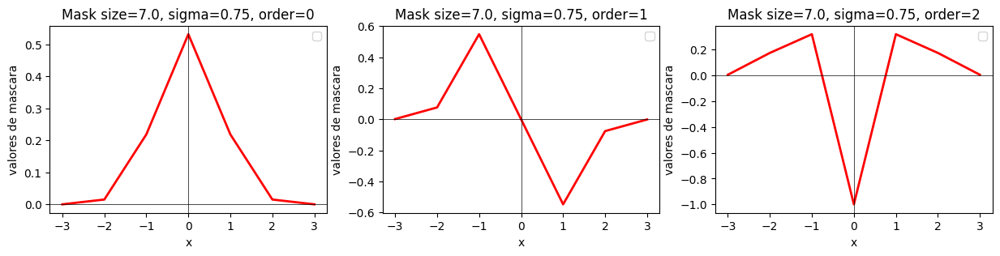

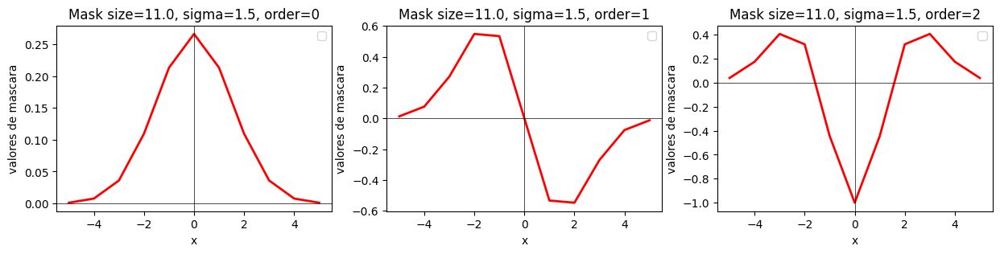

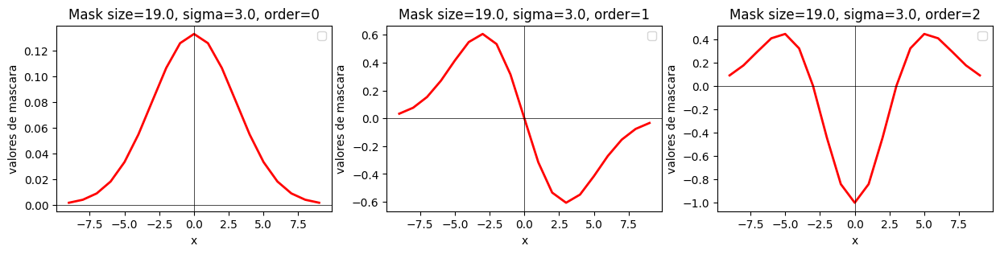

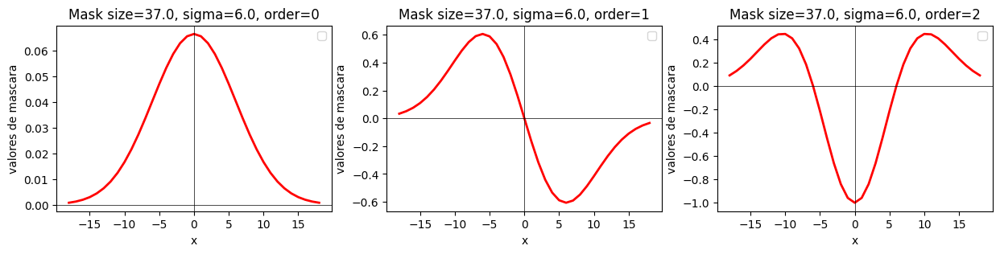

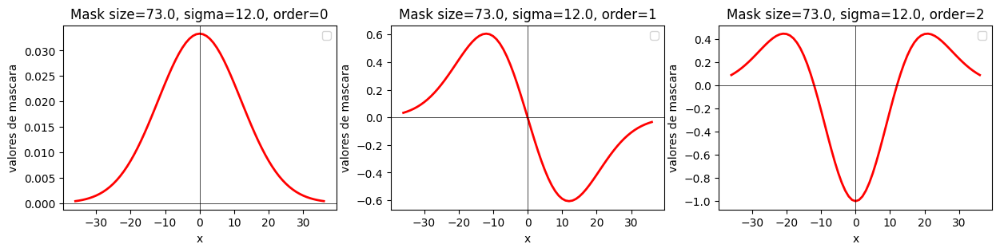

In [ ]:
sigma_values = np.array([0.75, 1.5, 3, 6, 12])
size_masks = np.array([5, 9, 11, 15])

plt.rcParams["figure.figsize"] = (15,3) # para ajustar tamaño del ancho y alto (ejes)
print('FIJAMOS PRIMERO EL TAMAÑO DE LA MÁSCARA')
for sizeMask in size_masks:
  fig, axs = plt.subplots(1, 3, figsize=(15, 3))
  for i in range(0,3):
    mask = gaussianMask1D(sigma = 0, sizeMask= sizeMask, order=i)
    plt.figure()
    xvalues = np.arange(-((sizeMask - 1 ) / 2), ( sizeMask - 1 ) / 2 + 1)
    axs[i].plot(xvalues, mask, lw=2, color='red')
    axs[i].set_title(f"Mask size={sizeMask}, sigma={(sizeMask-1)/6}, order={i}")
    axs[i].set_xlabel('x')
    axs[i].set_ylabel('valores de mascara')
    axs[i].axhline(0, lw=0.5, color='black')
    axs[i].axvline(0, lw=0.5, color='black')
    axs[i].legend();

  plt.show()

print('FIJAMOS AHORA EL SIGMA')
for sigma in sigma_values:
  fig, axs = plt.subplots(1, 3, figsize=(15, 3))
  for i in range(0,3):

    mask = gaussianMask1D(sigma = sigma, sizeMask= 0, order=i)
    k = np.ceil(3*sigma)
    xvalues = np.arange(-k, k + 1)
    axs[i].plot(xvalues, mask, lw=2, color='red')
    axs[i].set_title(f"Mask size={2*k + 1}, sigma={sigma}, order={i}")
    axs[i].set_xlabel('x')
    axs[i].set_ylabel('valores de mascara')
    axs[i].axhline(0, lw=0.5, color='black')
    axs[i].axvline(0, lw=0.5, color='black')
    axs[i].legend();

  plt.show()

Como se observa, estas máscaras se corresponden con funciones gaussianas y sus derivadas y podemos comprobar como en los casos de las gaussianas, se aplana la curva a medida que aumentamos $σ$. Además, como es lógico, al aumentar el tamaño de máscara, aumentan el número de puntos que representamos en el plot y se ven las curvas más "suaves".

## B) (1.5 puntos)

En este apartado se debe leer una imagen en escala de grises (`'motorcycle.bmp'`) y esta debe ser filtrada mostrando el resultado de la convolución con: a) una Gaussiana, b) la primera derivada de la Gaussiana en $X$, c) la primera derivada de la Gaussian en $Y$, d) la segunda derivada de la Gaussiana en $X$, y e) la segunda derivada de la Gaussiana en $Y$. Para ello, hay que:
1. emplear los siguientes sigmas ($\{0.75,1.5,3,6, 12\}$),
2. usar la función de OpenCV `sepFilter2D()` con las máscaras calculadas a partir de las funciones desarrolladas en el apartado anterior,
3. mostrar todas las imágenes dentro del mismo canvas, tal y como se muestra más abajo,
4. analizar los resultados obtenidos y discutir si se corresponden con lo se esperaría obtener en base a nuestro conocimiento de la teoría.




**<h1>RESPUESTA</h1>**
La función **myconv2D** hará lo siguiente: Recibe como parámetros una imagen **im**, **$σ$** y el orden de la derivada de la gaussiana en sentido X e Y como una tupla y utilizando la funcion **sepFilter2D** de **OpenCV** aplica las convoluciones en cada sentido.

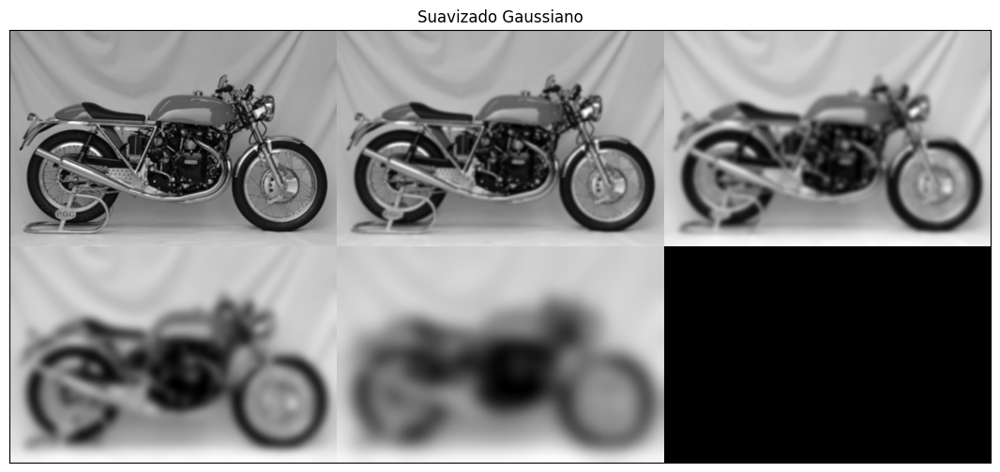

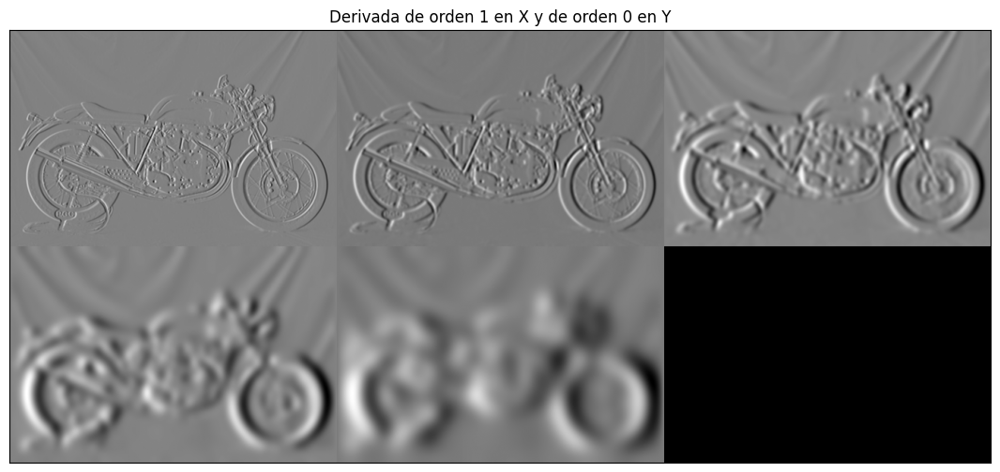

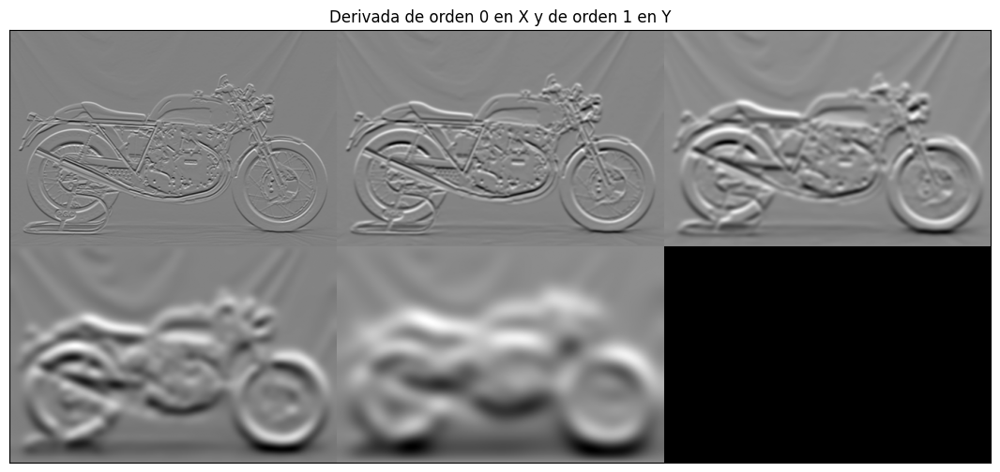

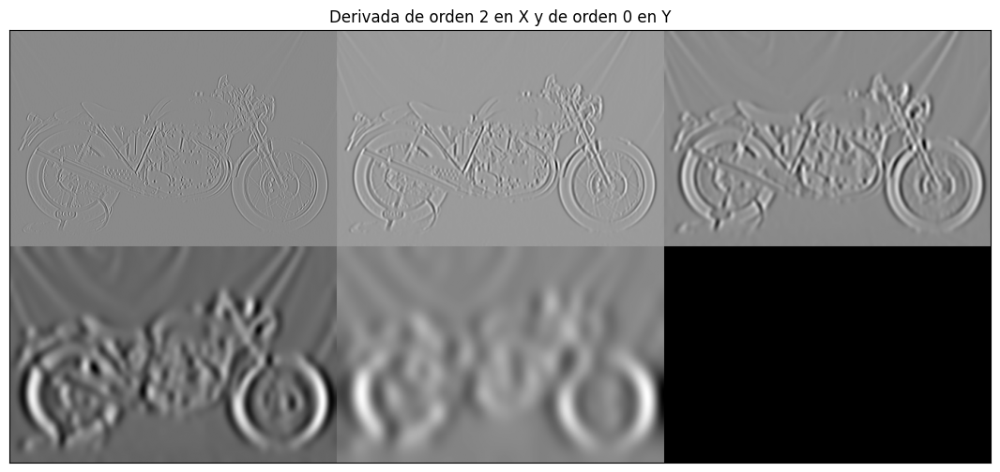

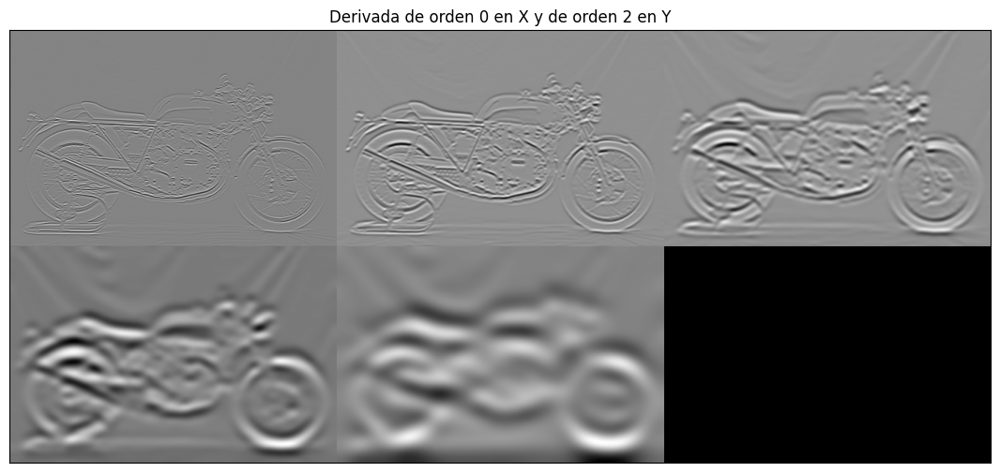

In [ ]:
def my2DConv(im, sigma, orders):
  #A CUBRIR POR EL ALUMNADO

  # La estructura de este if ha sido proporcionada por ChatGPT para no repetir
  # código. Comprueba que orders es una lista de longitud 2 y que sus elementos
  # son enteros de 0 a 2.
  if (
    isinstance(orders, (list, tuple)) and
    len(orders) == 2 and
    all(isinstance(o, int) and 0 <= o <= 2 for o in orders)
  ):
    maskX = gaussianMask1D(sigma=sigma, sizeMask=0, order=orders[0])
    maskY = gaussianMask1D(sigma=sigma, sizeMask=0, order=orders[1])
    return cv2.sepFilter2D(im, cv2.CV_64F, maskX, maskY )
  else:
    print('Error en el orden de la derivada')

sigmas = np.array([0.75, 1.5, 3, 6, 12])


im=cv2.imread(get_image('motorcycle.bmp'),0)
im = im / 255



orders=[[0,0], [1,0], [0,1], [2,0], [0,2]]

for order in orders:
  vim = []
  for sigma in sigmas:
    vim.append(rangeDisplay01(my2DConv(im,sigma,order),True))

  if order == [0,0]:
    displayMI_ES(vim,'Suavizado Gaussiano',2)
  else:
    displayMI_ES(vim,'Derivada de orden {} en X y de orden {} en Y'
    .format(order[0],order[1]),2)





De estas imágenes podemos sacar varias conclusiones:
  - Cuanto más grande sea **σ** vemos como la imagen es más borrosa. Esto tiene sentido pues al aumentar este parámetro, aumenta el tamaño de máscara y por tanto aumenta el número de píxeles vecinos a los que se aplica la máscara y por tanto el resultado es más borroso.
  - Tanto en las primeras como segundas derivadas, se ve como las derivadas en X ( resp. Y )se ensalzan más los bordes " perpendiculares " al eje X ( resp. Y ). Esto se puede ver como en la parte derecha e izquierda de la rueda delantera ( por ejemplo ) se notan más los bordes cuando se aplica kernel en dirección X y lo mismo con los bordes de arriba y abajo en dirección Y.

## C) (1 punto)

En este apartado hay que emplear la función `my2DConv()`, creada en el apartado anterior (y que, a su vez, emplea la función de OpenCV `sepFilter2D()`) con $\sigma=1.0$ para calcular y mostrar el gradiente (2 imágenes: magnitud y orientación) y la Laplaciana de la Gaussiana. Se debe explicar el trabajo realizado, incluyendo las expresiones matemáticas subyacentes y el análisis, al igual que en todos los ejercicios, relativo a si los resultados obtenidos se corresponden con lo esperado. Se emplea la misma imagen del apartado anterior: `motorcycle.bmp`

**<h1>RESPUESTA</h1>**

En este apartado vamos a calcular el kernel **gradiente** y **laplaciano**. Para ello recordamos que el gradiente es:

$$
  \nabla G(x,y) = ( \frac{∂G}{∂x}, \frac{∂G}{∂y})
$$

Con el gradiente construimos el filtro **magnitud** y **orientación** que son:

$$
  magnitud(\nabla G(x,y)) = |\nabla G(x,y)| = \sqrt{ \frac{∂G}{∂x}^2 + \frac{∂G}{∂y}^2}
$$

$$
  orientacion(\nabla G(x,y)) = atan2(  \frac{∂G}{∂y}, \frac{∂G}{∂x})
$$

Para el **Laplaciano** tenemos encuenta lo siguiente:

$$
  Gauss_σ(x,y) = e^{\frac{-(x^2 + y^2)}{2σ^2}} =  e^{\frac{-x^2}{2σ^2}} * e^{\frac{-y^2}{2σ^2}} = Gauss_σ(x) * Gauss_σ(y)
$$

Luego podemos derivar la expresión con respecto a la variable que queramos  derivando únicamente la gaussiana parcial a esa variable ya que la otra parte es constante. Tenemos entonces que:

$$
  Laplaciano(G(x,y)) = ΔG = \frac{∂^2G}{∂x^2} + \frac{∂^2G}{∂y^2} =
  \frac{∂^2(G(x)*G(y))}{∂x^2} + \frac{∂^2(G(x)*G(y))}{∂y^2} =
  G''(x)*G(y) + G(x)*G''(y)
$$

**NOTA: Habría que escalar estos operadores  multiplicando por $σ$^(orden de la derivada) pero esto viene hecho ya de serie en las máscaras de la sección 1.A.**

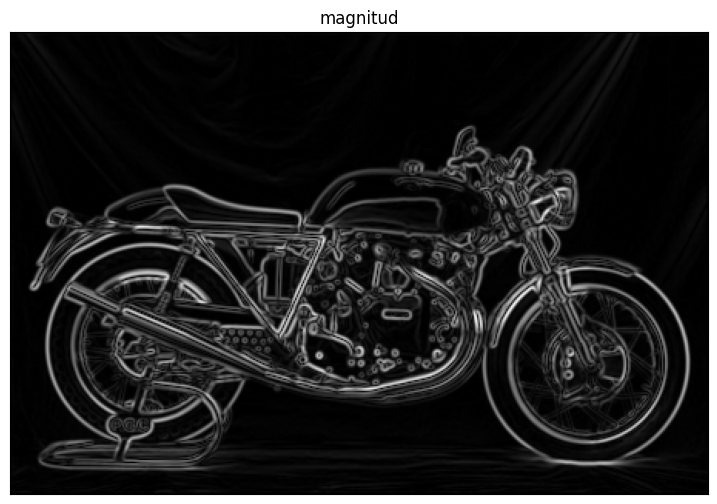

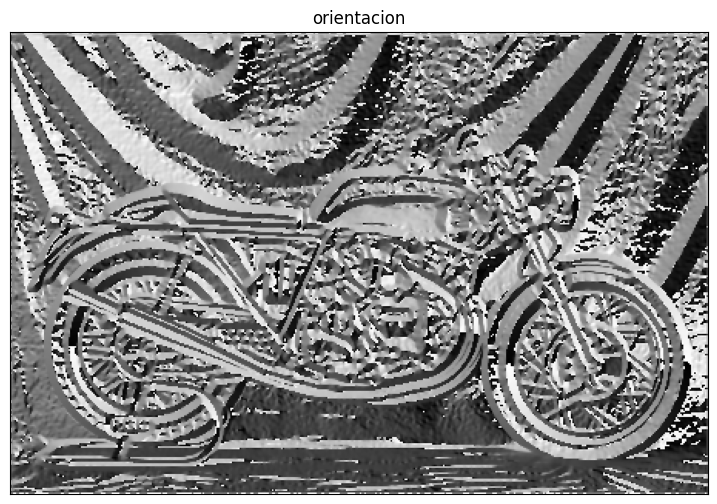

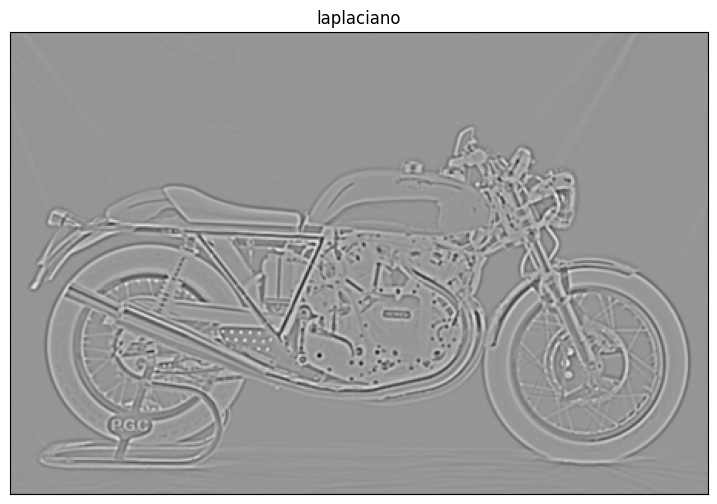

In [ ]:
# Calculamos las primeras derivadas con respecto a cada variable
# y se devuelven en una tupla
def gradientIM(im,sigma):
  #A CUBRIR POR EL ALUMNADO
  dx = my2DConv(im, sigma,[1,0])
  dy = my2DConv(im, sigma,[0,1])
  return dx,dy

# Calculamos las segundas derivadas con respecto a cada variable
# y se devuelven como suma
def laplacianG(im,sigma):
  #A CUBRIR POR EL ALUMNADO
  d2x = my2DConv(im, sigma,[2,0])
  d2y = my2DConv(im, sigma,[0,2])
  return  (d2x + d2y)

# La magnitud calcula el gradiente y devuelve el modulo del vector
def magnitud(im, sigma):
  grad = gradientIM(im, sigma)
  return np.sqrt(grad[0]**2 + grad[1]**2)

# La orientacion calcula el gradiente y devuelve atan2(dy,dx)
def orientacion(im, sigma):
  grad = gradientIM(im, sigma)
  return np.arctan2(grad[1],grad[0])

#A CUBRIR POR EL ALUMNADO
sig = 1.0
im_or = orientacion(im, sig)
im_magni = magnitud(im, sig)
im_lap = laplacianG(im, sig)
displayIm(im_magni, title='magnitud',factor= 2)
displayIm(im_or, title='orientacion',factor= 2)
displayIm(im_lap, title='laplaciano',factor= 2)


Observaciones:

  -  Los tres filtros presentan características similares a lo visto en clase con la imagen de la cebra en escala de grises. Esto no hace un análisis correcto pues simplemente lo comparamos con otro ejemplo pero sí que sirve para apreciar que vamos por buen camino.
  - La imagen con el kernel **laplaciano** realza los bordes tanto en dirección X como Y. La imagen se parece bastante a lo visto al aplicar segundas derivadas en cualquiera de los dos sentidos. Estas dos últimas observaciones son coherentes ya que se está aplicando primero  segunda derivada en sentido X y luego en sentido Y.
  - La imagen con el kernel **magnitud** también parece realzar los bordes en ambos sentidos. ¿ Por qué entonces se ve mayoritariamente negra la imagen en lugar de gris como en el laplaciano ? Pues porque en este caso lo que hacemos es utilizar un kernel que es la raíz cuadrada de algo luego son valores positivos. En el caso del laplaciano, existen valores negativos luego a la hora del visualizado, se reescalan los valores a [0,255] por lo que el valor 0 del intervalo [-255,255] se lleva al 128 del intervalo [0,255] y por eso se ve mayoritariamente gris el laplaciano.
  - La imagen **orientacion** también concuerda con lo visto en clase. Se aprecian menos los bordes que con los anteriores kernel.

## D) (1.5 puntos)  

Implemente una función para realizar "a mano" la convolución separable (es decir, empleando kernels 1D). Dicha función debe recibir como entrada una imagen (con el _padding_ adecuado, en caso de que lo necesite, ya incorporado) y un kernel 1D, y debe proporcionar como salida la imagen convolucionada con el kernel en ambas direcciones. Es decir, el hecho de introducir, o no, padding es un elemento externo a la función de convolución que lo único que hace es realizar la convolución separable encajando el kernel hasta el límite de la imagen de entrada.

Una vez haya implementado la función, aplique un kernel de derivadas en $X$ a la imagen `zebra.jpg` (usando los kernels de tamaño $5$, generados por nuestras funciones del Ejercicio $1$, y dejando que sea la propia función de creación del kernel la que determine el $\sigma$ adecuado), y compare el resultado con el de `cv2.Sobel` (en donde se debe optar por la misma estrategia: fijando $ksize=5$ y dejando que sea la propia función de OpenCV la que escoja el sigma). ¿Hay diferencias (sea a nivel de resultado final o de tiempo de ejecución)? En caso afirmativo, ¿a qué se pueden deber?

**Nota**: el código del alumnado no puede ser más de $50$ veces más lento que el de OpenCV. Ese es el límite superior aceptable. Se debe optimizar la ejecución para, al menos, estar en ese orden de magnitud comparativamente con el rendimiento ofrecido por OpenCV. Estos tiempos de ejecución se deben medir usando:

```python
starttime = time.perf_counter()
# CÓDIGOS DE CONVOLUCIÓN
duration = timedelta(seconds=time.perf_counter() - starttime)
```


**<h1>RESPUESTA</h1>**

Para la función de convolución un kernel 1D, vamos a implementar el siguiente algoritmo. En lugar de convolucionar filtros 1D píxel por píxel ( Lo cual resultaría en 4 bucles, que es muy ineficiente ) vamos a usar un método más eficiente.

La operación de convolución 1D de un **píxel (i,j)** es el resultado de multiplicar componente a componente el vector kernel por el vector de mismas dimensiones centrado en el **píxel (i,j)** y realizar la suma. Se puede ver como superponer el vector kernel encima de la matriz de forma que el valor central del kernel quede encima del **píxel (i,j)** y realizar la operación de multiplicación y suma descrita previamente. Por ejemplo en el caso:

   $$
   \begin{bmatrix}
   1 \\
   2 \\
   1
   \end{bmatrix}
   \begin{bmatrix}
   10 & 20 & 30 \\
   40 & 50 & 60 \\
   70 & 80 & 90
   \end{bmatrix}
   $$

   Al querer calcular el pixel de posición **(2,1)** de la imagen convolucionada por el kernel, es el resultado de superponer el kernel sobre el píxel de posición **(2,1)** de la imagen original y realizar la operación. El resultado sería:
  $$
  \begin{bmatrix}
  1 \\
  2 \\
  1
  \end{bmatrix}
  ̇
  \begin{bmatrix}
  10 \\
  40\\
  70
  \end{bmatrix}
  = 1*10 + 2*40 + 1*70 = 160
  $$

  Si en lugar de central el kernel en el píxel **40** lo hacemos en el **10**
  nos damos cuenta de que el primer valor de kernel se desborda de la matriz. En este caso se multiplica ese valor por 0 ( igualmente si se desborda por abajo) y se multiplica **2 x 10 + 1 x 40**.

  Esta operación es ineficiente ya que requiere 4 bucles ( Recorrer la imagen en cada píxel y aplicar el kernel primero en X y luego en Y ). Por ello, vamos a hacer lo siguiente:

  1. Extendemos el kernel 1D a una matriz de <b>ancho de imagen</b> columnas.
       
$$
\mathbf{}
\begin{bmatrix}
1 \\
2 \\
1
\end{bmatrix}
\quad \longrightarrow \quad
\mathbf{}
\begin{bmatrix}
1 & 1 & 1 & 1 & \dots & 1 \\
2 & 2 & 2 & 2 & \dots & 2 \\
1 & 1 & 1 & 1 & \dots & 1
\end{bmatrix}
$$
  
  2. Aplicamos el kernel matriz de la siguiente forma. Vamos a deslizar la matriz de <b>Kernel en Y</b> verticalmente donde se empieza "superponiendo" la matriz kernel de manera que la fila central del Kernel queda superpuesta a la fila 0 de la matriz. Este concepto es muy parecido al de "superponer" un kernel 1D sobre un píxel pero en este caso superpones la fila central de la matriz kernel sobre la fila 0 de  la matriz. En cada iteración i, se centra el kernel sobre la <b> fila i</b> de la imagen de la manera descrita y construimos la subimagen de mismas dimensiones que la matriz kernel, que sería algo como la región vecina de la fila.

  3. Por último, multiplicamos el kernel por la subimagen componente a componente y la fila de la nueva matriz será la fila resultante de sumar las columnas de cada matriz. Si nos damos cuenta, esto es lo mismo que aplicar el kernel pixel a pixel, pero más eficiente al utilizar matrices y en una iteración calcular todos los pixeles de una fila.


  
Esta función se corresponde con **convolve1D()**. Para realizar la **convolución 2D** aplicamos la primera función con el kernel en el eje Y, se calcula la traspuesta del resultado, después se aplica otra vez la función con el kernel en el eje X y por último se devuelve la traspuesta de el resultado.

In [ ]:

def convolve1D(image,kernel):
    #A CUBRIR POR EL ALUMNADO
    output = np.zeros_like(image)
    ancho_img = image.shape[1]
    alto_img = image.shape[0]
    ini_img = 0
    fin_img = alto_img - 1
    kernel_size = kernel.shape[0]
    ini_kernel = 0
    mitad_kernel = (kernel_size ) // 2
    fin_kernel = kernel_size - 1
    kernel_mtx = np.zeros((kernel.shape[0],ancho_img))
    submatriz_img = np.zeros_like(kernel_mtx)
    output = np.zeros_like(image)

    # kernel_mtx es el resultado de propagar el kerned 1D a lo largo de
    # tantas columnas como ancho tenga la imagen. Por ejemplo si el
    # kernel es [1,2,1], la kernel_mtx tiene 3 filas de ancho_imagen columnas
    # donde la fila 1 es todo 1, la fila 2 es todo 2 y la fila 3 es todo 1.
    for i in range(0, kernel.shape[0]):
      kernel_mtx[i,:] = kernel[i]*np.ones(ancho_img)

    # Para implementar el algoritmo vamos a hacer lo siguiente:

    #     - Se itera sobre las filas de la imagen.

    #     - Se calcula la subimagen de mismas dimensiones que kernel_mtx
    #       centrada en cada fila. Esta subimagen está formada por las
    #       mitad_kernel filas anteriores a la fila i, la propia fila i y las
    #       mitad_kernel filas siguientes.

    #     - Para cada fila, tenemos 3 situaciones al "superponer" la fila
    #       central de kernel_mtx sobre la fila i, o bien hay filas de
    #       kernel_mtx que se desbordan de la matriz por arriba o bien por
    #       abajo o bien no nos desbordamos.

    #     - Si nos desbordamos por arriba, rellenamos con tantas filas de 0
    #       como filas nos desbordemos. Por ejemplo para el kernel [1 2 1] y
    #       y una imagen suficientemente grande, al aplicar la convolución por
    #       la primera fila, tendríamos que el valor de la nueva fila sería
    #       2*fila0 + 1*fila1 pero el primer 1 del kernel se multiplicaría por
    #       una " fila -1 ". Para anular esto rellenariamos submatriz_img con
    #       una fila de 0 al principio. Esto lo controlamos con la variable
    #       "ceros_arriba" que resta la mitad del kernel a la fila actual. Si
    #       el valor es positivo hay que rellenar con tantas filas de 0 como
    #       diga la variable.
    #
    #     - Si nos desbordamos por debajo, se procede de la misma forma con
    #       "ceros_abajo". Esta variable se calcula como fila_act +
    #       mitad_kernel - fin_img. Si es positivo se rellenan con tantos 0
    #       como la variable indique, si no, se ignora.
    #
    #     - Si ambas variables son <=0, no nos desbordamos y se toman las
    #       mitad_kernel filas anteriores a la fila i, la propia fila i y las
    #       siguientes mitad_kernel filas.
    #
    #     - Por último, para calcular la nueva fila, utilizamos np_multiply
    #       para multiplicar kernel_mtx y submatriz_img elemento a elemento
    #       y calculamos la suma por columnas dando lugar a la fila resultante.

    for i in range(0, image.shape[0]):


      ceros_arriba = mitad_kernel - i
      ceros_abajo = i + fin_kernel - mitad_kernel - fin_img

      if(ceros_arriba > 0):
        submatriz_img[ceros_arriba:,:] = image[0:kernel_size-ceros_arriba,:]
      elif(ceros_abajo > 0):
        submatriz_img[0:kernel_size - ceros_abajo,:] = image[i-mitad_kernel:,:]
      else:
        submatriz_img = image[i-mitad_kernel:i-mitad_kernel+kernel_size,:]

      output[i] = np.sum(np.multiply(kernel_mtx, submatriz_img), axis=0)

      submatriz_img = np.zeros_like(kernel_mtx)

    return output

def convolve2D(image, kx, ky):
    #A CUBRIR POR EL ALUMNADO
    output = np.zeros_like(image)
    output = convolve1D(image,ky)
    output = np.transpose(output)
    output = convolve1D(output,kx)
    output = np.transpose(output)
    return output



A continuación, generamos los kernels de **orden 1 en X y 0 en Y**. Se normaliza la imagen y aplicamos nuestra función de convolución separable. Además, se realiza una comparativa de resultado y de tiempo de ejecución con la función **Sobel()** de OpenCV.

In [ ]:
import time
from datetime import timedelta

# Generamos los kernels
kernel_x = gaussianMask1D(sigma= 0, sizeMask=5, order=1)
kernel_y = gaussianMask1D(sigma= 0, sizeMask=5, order=0)

# Se lee y normaliza la imagen
im_zebra=cv2.imread(get_image('zebra.jpg'),0)
im_zebra = im_zebra / 255

# Aplicamos los kernels y realizamos las mediciones
starttime = time.perf_counter()
im_zebra_conv = convolve2D(im_zebra,kernel_x, kernel_y)
duration_myconv = timedelta(seconds=time.perf_counter() - starttime)


starttime = time.perf_counter()
im_zebra_sobel = cv2.Sobel(im_zebra,cv2.CV_64F,1,0,ksize=5)
duration_sobel = timedelta(seconds=time.perf_counter() - starttime)

print('duracion funcion Convolve2D {}'.format(duration_myconv))
print('duracion funcion Sobel {}'.format(duration_sobel))

duracion funcion Convolve2D 0:00:00.255102
duracion funcion Sobel 0:00:00.011794


In [ ]:
print(duration_myconv/duration_sobel)

21.629811768695948


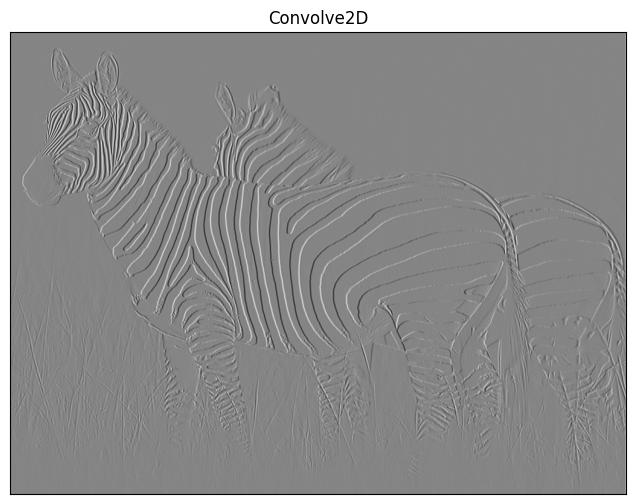

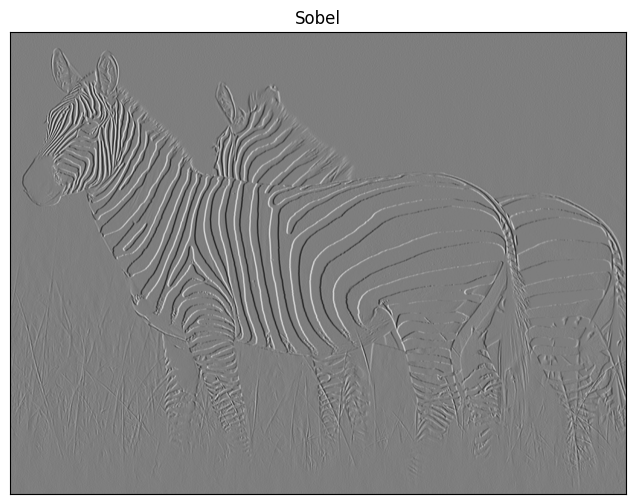

In [ ]:
displayIm(im_zebra_conv, title='Convolve2D',factor= 2)
displayIm(im_zebra_sobel, title='Sobel',factor= 2)

Observaciones:
  - En tiempo de ejecución, Sobel es mucho más eficiente que nuestro algoritmo ( aunque entra dentro de la condición de que no sea más de 50 veces más lento). Tras investigar un poco, Sobel se implementa en C++ que al ser un lenguaje compilado, hace mucho menos costosos los bucles en cuanto a tiempo de ejecución. Mi implementación está hecha en python que al ser un lenguaje interpretado, los bucles tardan más tiempo. Además, Sobel utiliza otras formas de optimización.
  - En cuanto a resultado, aunque se vea parecido ( podemos ver resaltados los bordes en el eje X), se pueden ver las diferencias en los bordes. Si nos fijamos, una imagen resalta los bordes de manera que parece que pertenecen a las rallas negras de la cebra y la otra a las rallas blancas ( al ser las imágenes grises no se puede decir cuál es cuál ) pero se ve como el "mismo" borde pertenece a elementos "diferentes".

In [ ]:
kx, ky = cv2.getDerivKernels(dx=1, dy=0, ksize= 5, normalize=False, ktype=cv2.CV_64F)
print('kernel en X generado por mi funcion: {}'.format(kernel_x))
print('kernel en y generado por mi funcion: {}'.format(kernel_y))
print('kernel en X generado por Sobel: {}'.format(kx))
print('kernel en Y  generado por Sobel: {}'.format(ky))

kernel en X generado por mi funcion: [ 0.03332699  0.4869787  -0.         -0.4869787  -0.03332699]
kernel en y generado por mi funcion: [0.00664603 0.19422555 0.59825683 0.19422555 0.00664603]
kernel en X generado por Sobel: [[-1.]
 [-2.]
 [ 0.]
 [ 2.]
 [ 1.]]
kernel en Y  generado por Sobel: [[1.]
 [4.]
 [6.]
 [4.]
 [1.]]


Al generar los kernel de nuestro algoritmo y de Sobel, vemos que existe cierta diferencia por lo que puede ser la razón por la que vemos esta diferencia entre nuestra imagen y la generada por Sobel. Vamos a ver ahora cuan diferente es nuestra imagen.

Error per pixel sobel vs convolve2D 5.3402979364969125


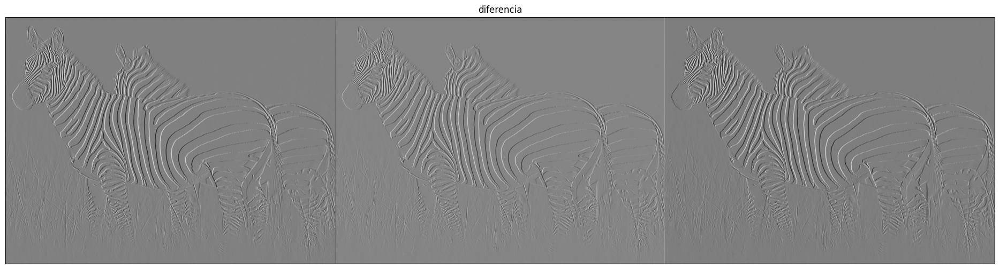

In [ ]:
print('Error per pixel sobel vs convolve2D',np.sqrt(np.mean((im_zebra_conv - im_zebra_sobel) ** 2)))
displayMI_ES([rangeDisplay01(im_zebra_conv - im_zebra_sobel),rangeDisplay01(im_zebra_conv), rangeDisplay01(im_zebra_sobel)],'diferencia')

Este valor que no es muy elevado muestra la diferencia que se apreciaba en las rallas de la cebra.

# **Ejercicio 2**:  Pirámides Gaussianas y Laplacianas (4.5 puntos)







## A) (1 punto)

Construya una pirámide Gaussiana de $5$ niveles empleando máscaras Gaussianas de tamaño $5\times5$. No se permite emplear las funciones `pyrUp()` y `pyrDown()` de OpenCV. `cv2.resize()` no se puede emplear a la hora de crear la pirámide Gaussiana (apartado A), pero sí a la hora de crear la pirámide Laplaciana (apartado B) y cuando se reconstruye la imagen original a partir de esta última pirámide (apartado C). En todos los apartados de este ejercicio se debe emplear la imagen `einstein.bmp`.

In [ ]:
'''
This function displays a pyramid of images, providing as input the list of images to display.

Example of use:
im1=readIm(get_image('apple.jpg'),1)
images = [im1, cv2.resize(im1,(im1.shape[0]//2,im1.shape[1]//2),cv2.INTER_LINEAR), cv2.resize(im1,(im1.shape[0]//4,im1.shape[1]//4),cv2.INTER_LINEAR), cv2.resize(im1,(im1.shape[0]//8,im1.shape[1]//8),cv2.INTER_LINEAR), cv2.resize(im1,(im1.shape[0]//16,im1.shape[1]//16),cv2.INTER_LINEAR)]

displayPyramid(images, title='Piramide de Manzanas')

'''
def displayPyramid(vim, title='result'):
  temp = np.zeros_like(vim[0])
  if np.mod(temp.shape[1],2)==0:
    h = temp[:, :temp.shape[1]//2]
  else:
    h = temp[:, :(temp.shape[1]//2)+1]
  out = np.hstack((temp, h))
  top = 0
  out[0:vim[0].shape[0], 0:vim[0].shape[1]] = vim[0]
  left = vim[0].shape[1]
  for i in range(1, len(vim)):
    out[top:top+vim[i].shape[0], left:left + vim[i].shape[1]] = vim[i]
    top += vim[i].shape[0]
  displayIm(out, title)

**<h1>RESPUESTA</h1>**

Para la pirámide Gaussiana procedemos de la siguiente forma:
  - Calculamos la máscara gaussiana de **order** 0 y de **sizeMask** el tamaño de máscara pasado como parámetro.
  - La primera imagen de la pirámide es la imagen primitiva.
  - Se itera sobre el valor **nlevel** y la imagen del siguiente nivel se consigue aplicando suavizado gaussiano y tomando las filas y columnas pares o impares.

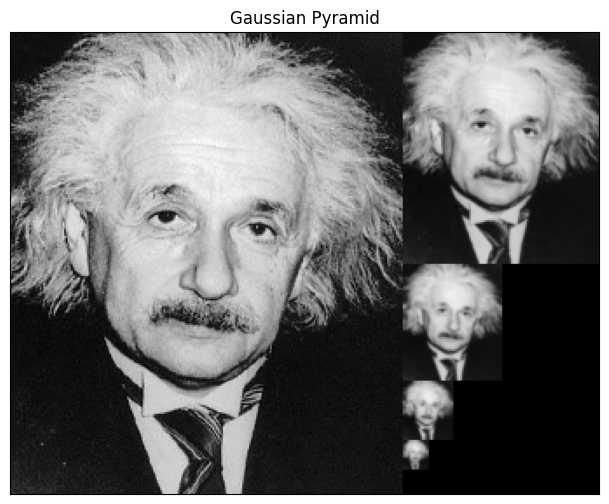

In [ ]:
def pyramidGauss(im,sizeMask=7, nlevel=4):
  #A CUBRIR POR EL ALUMNADO

  # Cálculo del kernel de suavizado, luego orden 0.
  kernel = gaussianMask1D(sigma=0, sizeMask= sizeMask, order = 0)

  # La primera imagen es la imagen de partida
  pir = [im]

  # Para cada nivel, aplicamos el kernel a la imagen anterior y nos quedamos
  # con las filas y columnas pares.
  for i in range(nlevel):
    im_blurr = cv2.sepFilter2D(pir[i], cv2.CV_64F , kernel, kernel)
    im_sub = im_blurr[::2, ::2]
    pir.append(im_sub)

  return pir

im=cv2.imread(get_image('einstein.bmp'),0)
im = im / 255
pyrG = pyramidGauss(im,sizeMask=7, nlevel=4)
displayPyramid(pyrG,'Gaussian Pyramid')


Como podemos comprobar, pese a que se ven más borrosas ( completamente normal por el blurr) se mantiene la imagen a lo largo de la pirámide.

## B) (1 punto)

Use su código del apartado anterior para implementar una función que permita construir una pirámide Laplaciana de $5$ niveles.

**<h1>RESPUESTA</h1>**

Para la pirámide Laplaciana:
  1. Calculamos la pirámide Gaussiana.
  2. Iteramos sobre **nlevel**.
  3. Expandimos el nivel **i+1** de la pirámide Gaussiana al tamaño del nivel previo ( es decir, el doble de tamaño).
  4. Se resta al nivel **i** de la Gaussiana la imagen expandida.
  5. Por último se añade el último nivel de la Gaussiana ( Coincide con la Laplaciana ).

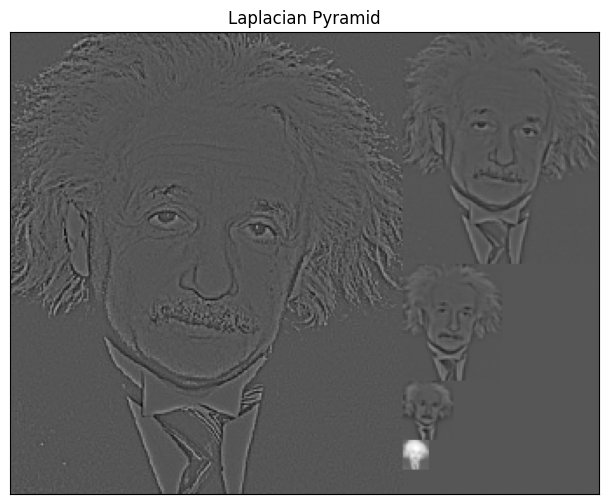

In [ ]:
def pyramidLap(im, sizeMask,nlevel=4,flagInterp=cv2.INTER_LINEAR  ):

  # Cálculo de pirámide Gaussiana
  pyrG = pyramidGauss(im,sizeMask,nlevel)
  pyrL = []

  # Para cada nivel, expandimos la imagen de nivel superior de la gaussiana
  # a tamaño del nivel actual de la gaussiana. Por último le restamos a
  # la Gaussiana de nivel "i" la gaussiana de nivel "i+1" expandida.
  for i in range(nlevel):

    im_exp = cv2.resize(pyrG[i+1], (pyrG[i].shape[1], pyrG[i].shape[0]), flagInterp)
    next = pyrG[i] - im_exp
    pyrL.append(next)

  # Se termina añadiendo el último nivel de la gaussiana ( coincide con el
  # último nivel de laplaciana )
  pyrL.append(pyrG[nlevel])

  return pyrL

pyrL = pyramidLap(im,sizeMask=7, nlevel=4)
displayPyramid(pyrL,'Laplacian Pyramid')

Como vemos, coincide con lo desarrollado sobre Laplaciano de imágenes, es decir, bordes resaltados en ambas direcciones.

In [ ]:
print((pyrL[4] - pyrG[4]).min(), (pyrL[4] - pyrG[4]).max())

0.0 0.0


Además, como cabría esperar, coincide la Gaussiana en el nivel más alto con la Laplaciana ( Es obvio puesto que en la implementación de la Laplaciana se hace así ). Se hace esta prueba porque al visualizar ambas imágenes, una aparece con el fondo en gris y la otra en negro ( no el fondo de la pirámide sino el propio fondo de la imagen ) y quería asegurarme de que fueran la misma.

## C) (1 punto)

Implemente ahora una función para reconstruir la imagen codificada en la pirámide Laplaciana del apartado 2.B. Verifique que es posible obtener una copia exacta de la imagen original. Para ello, calcule el error de reconstrucción como el _Root Mean Squared Error_ (RMSE) entre los niveles de intensidad de la imagen original y la imagen reconstruida.

**<h1>RESPUESTA</h1>**

Como hemos visto en clase, se puede reconstruir a la perfección la imagen de serie a partir de su pirámide laplaciana. Esto es porque desde la pirámide Laplaciana podemos acceder al nivel más alto de la pirámide Gaussiana y cada imagen de la pirámide Laplaciana es la diferencia entre dos niveles consecutivos de la Gaussiana ( El nivel mayor expandido a dimensiones del nivel menor ).

Partimos entonces del nivel más alto de la Laplaciana ( y Gaussiana ). Tenemos que **pyrG[i] - expand(pyrG[i+1]) = pyrL[i]** $∀ i = 0,1,...,nlevel-1$ y **pyrG[nlevel ]  = pyrL[nlevel ]**. Entonces **pyrG[0] - expand(pyrG[1]) = pyrL[0]** y por tanto  **img = pyrG[0]  = pyrL[0] + expand(pyrG[1])**.

Entonces esto nos dice que podemos reconstruir la imagen original a partir de la laplaciana. Como tenemos disponible **G[nlevel] y L[nlevel]**. se puede calcular
**G[nlevel - 1]** = L[nvelel -1] + expand(G[nlevel]).
Para calcular el nivel inferior G[nlevel - 2], nos hace falta L[nlevel - 2] ( Lo tenemos, se pasa la laplaciana entera como parámetro a la función ) y expand( G[nlevel - 1] ( lo acabamos de calcular ).

Entonces, se va calculando cada nivel de la pirámide Gaussiana de mayor a menor nivel hasta llegar al nivel 0, esto es, la imagen original.


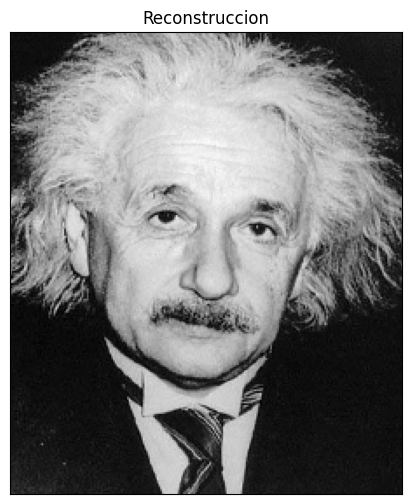

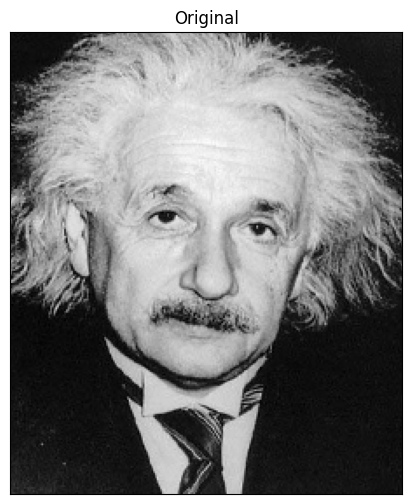

Error per pixel 0.0


In [ ]:
def reconstructLap(pyL,flagInterp):

  # Tomamos la Laplaciana invertida para recorrer de mayor a menor nivel
  pyr_inv = pyL[::-1]
  tam_pyr = len(pyr_inv)

  # Inicialmente fijamos la reconstrucción al nivel más alto de las pirámides
  rec = pyr_inv[0]

  # Se recorre la pirámide Laplaciana de mayor a menor nivel
  for i in range(1,tam_pyr):

    # Se expande la imagen reconstruida y se le suma el valor de la laplaciana
    exp_img = cv2.resize(rec, (pyr_inv[i].shape[1], pyr_inv[i].shape[0]), flagInterp)
    rec = exp_img + pyr_inv[i]
  return rec

im=cv2.imread(get_image('einstein.bmp'),0).astype(np.float32)

pyrL = pyramidLap(im,sizeMask=7, nlevel=4)
recons = reconstructLap(pyrL,cv2.INTER_LINEAR)
displayIm(recons,'Reconstruccion')
displayIm(im,'Original')
#A CUBRIR POR EL ALUMNADO
print('Error per pixel',np.sqrt(np.mean((im - np.round(recons)) ** 2)))

Como se puede observar, la reconstrucción parece exacta en el visualizado de las imagenes, lo que es reforzado por el error por píxel = 0.0.

## D) (1.5 puntos)

### APARTADO 1 (0.5 puntos)

Imaginemos que tenemos una implementación en donde, a la hora de construir la pirámide Laplaciana, cada nivel lo introducimos normalizado, es decir, empleamos `rangeDisplay01()` antes de introducir el nivel generado en el listado de imágenes que conforman la pirámide Laplaciana. ¿Qué influencia puede tener a la hora de reconstruir la imagen original? ¿Considera que sería una práctica adecuada?

**<h1>RESPUESTA</h1>**

La función **rangeDisplay01()** reescala la imagen al intervalo **[0,1].** La pirámide Laplaciana se construye restando dos niveles consecutivos de la pirámide gaussiana. Es por esto que podemos tener valores negativos en los niveles de la laplaciana. Al utilizar **rangeDisplay01()**, estos valores negativos se pierden en cada nivel. La reconstrucción de la imagen es básicamente sumar todos los niveles de la laplaciana ( no se suma expandiendo cada nivel al nivel más bajo y luego sumando, sino que se suma el nivel más alto expandido al tamaño del nivel anterior con el propio nivel anterior y esto se suma del mismo modo al nivel anterior hasta llegar al más bajo ). Entonces si cada nivel se reescala al intervalo **[0,1]** aparentemente estamos perdiendo información. Supongamos que utilizando **rangeDisplay01()** se  genera una reconstrucción exacta. Si encontramos un contraejemplo en el que no suceda esto, podemos demostrar que es falso el enunciado anterior.  Vamos a ver que pasa en nuestra imagen para comprobar si es un contraejemplo o por contrario se reconstruye exactamente. En este último caso tendríamos que examinar que ocurre en cada paso y si la reconstrucción con **rangeDisplay01()** es perfecta para cada imagen o si sucede concretamente en nuestra imagen. Para ello vamos a definir una función que calcule la pirámide laplaciana normalizada.

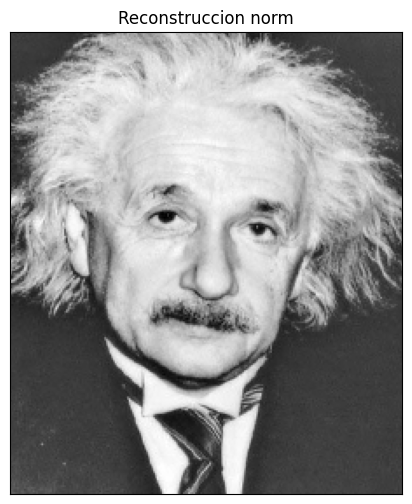

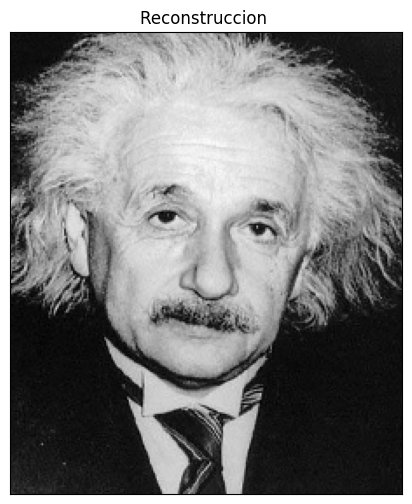

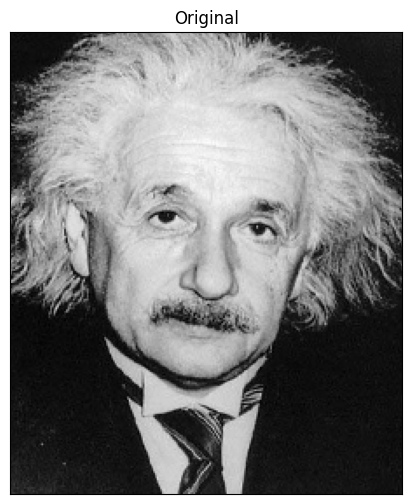

Error per pixel recons norm 133.11684512871787
Error per pixel recons  0.0


In [ ]:
def pyramidLapNorm(im, sizeMask,nlevel=4,flagInterp=cv2.INTER_LINEAR  ):

  # Cálculo de pirámide Gaussiana
  pyrG = pyramidGauss(im,sizeMask,nlevel)
  pyrL = []

  # Para cada nivel, expandimos la imagen de nivel superior de la gaussiana
  # a tamaño del nivel actual de la gaussiana. Por último le restamos a
  # la Gaussiana de nivel "i" la gaussiana de nivel "i+1" expandida.
  for i in range(nlevel):

    im_exp = cv2.resize(pyrG[i+1], (pyrG[i].shape[1], pyrG[i].shape[0]), flagInterp)
    next = pyrG[i] - im_exp
    pyrL.append(rangeDisplay01(next))

  # Se termina añadiendo el último nivel de la gaussiana ( coincide con el
  # último nivel de laplaciana )
  pyrL.append(rangeDisplay01(pyrG[nlevel]))

  return pyrL

im=cv2.imread(get_image('einstein.bmp'),0).astype(np.float64)
# im = im /255
pyrL = pyramidLapNorm(im,sizeMask=7, nlevel=4)
recons_norm = reconstructLap(pyrL,cv2.INTER_LINEAR)
pyrL = pyramidLap(im,sizeMask=7, nlevel=4)
recons = reconstructLap(pyrL,cv2.INTER_LINEAR)
displayIm(recons_norm,'Reconstruccion norm')
displayIm(recons,'Reconstruccion ')
displayIm(im,'Original')
#A CUBRIR POR EL ALUMNADO
print('Error per pixel recons norm',np.sqrt(np.mean((im - np.round(recons_norm)) ** 2)))
print('Error per pixel recons ',np.sqrt(np.mean((im -np.round(recons)) ** 2)))


In [ ]:
print(im.min(), im.max())
print(recons.min(), recons.max())
print(recons_norm.min(), recons_norm.max())

1.0 247.0
1.0 247.0
1.6249789525039444 3.0944580285761227


Observaciones:
  - Las reconstrucción original y la imagen original visualmente son iguales como habíamos visto antes. Sin embargo, la reconstrucción usando el reescalado **recons_norm**, se ve una imagen parecida pero mucho más gris.
  - Al comprobar los valores máximos y mínimos de cada imagen, se ve como la reconstrucción original mantiene píxeles mínimos y máximos coherentes con respecto a la imagen mientras que la reconstrucción con **rangeDisplay01()** presenta valores muy diferentes.

Entonces, respondiendo a las preguntas planteadas, la influencia que tiene usar **rangeDisplay01()** es básicamente que la reconstrucción no es exacta. Con respecto a si es recomendable esta práctica, a nivel de reconstrucción exacta no lo es, pero sí que es cierto que la imagen es muy parecida salvo por cambios de color ( La imagen con **rangeDisplay01()** parece más gris ), por lo que puede ser útil para tareas de reconstrucción para obtener una imagen más clara.

### APARTADO 2 (0.5 puntos)

Imaginemos ahora que no expandimos de la misma forma al crear la pirámide Laplaciana y al reconstruir la imagen original. En el primer caso, usamos `cv2.resize()`, con `cv2.INTER_LINEAR`, mientras que en el segundo usamos `cv2.pyrUp()`. ¿Esto afecta a la reconstrucción de alguna forma o no? ¿Por qué?

**<h1>RESPUESTA</h1>**

Sí que afecta por la forma de construir la imagen redimensionada. Con **resize()** al aumentar las dimensiones, los nuevos píxeles calculados se calculan por interpolación bilineal ( que es la flag que hemos fijado ) que lo que hace es interpolar un valor por 4 de sus vecinos. Si el píxel está en la posición **(x,y)**, se interpola con sus vecinos **(x+-1,y+-1)**. Con **pyrUp()** rellenamos los píxeles nuevos con 0 y la nueva imagen se construye multiplicando esta matriz con los valores originales y 0 en los nuevos píxeles convolucionada por un kernel Gaussiano. Vamos a ver que sucede en nuestra imagen. Hemos visto en el apartado C) como la reconstrucción es exacta, pues lo que habíamos restado para calcular la laplaciana, lo sumamos ahora para acceder a cada nivel de la Gaussiana y en el nivel más bajo, a la imagen original.

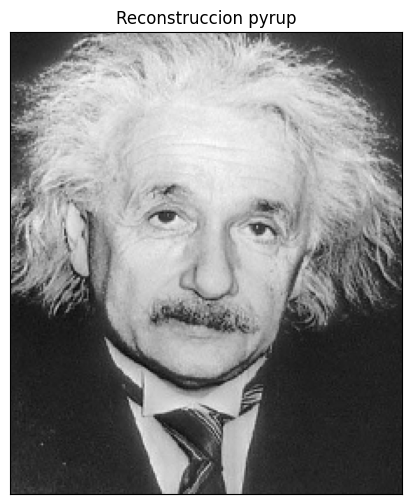

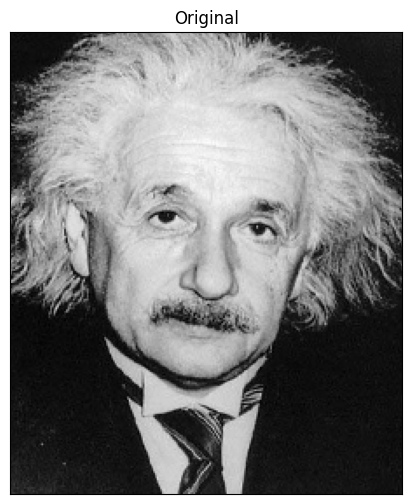

Error per pixel recons up 13.944794419589417


In [ ]:

# función para reconstruir la imagen cambiando resize por pyrUp
def reconstructLapPyrUp(pyL):

  # Tomamos la Laplaciana invertida para recorrer de mayor a menor nivel
  pyr_inv = pyL[::-1]
  tam_pyr = len(pyr_inv)

  # Inicialmente fijamos la reconstrucción al nivel más alto de las pirámides
  rec = pyr_inv[0]

  # Se recorre la pirámide Laplaciana de mayor a menor nivel
  for i in range(1,tam_pyr):

    # Se expande la imagen reconstruida y se le suma el valor de la laplaciana
    exp_img = cv2.pyrUp(rec, dstsize=(pyr_inv[i].shape[1], pyr_inv[i].shape[0]))
    rec = exp_img + pyr_inv[i]
  return rec

im=cv2.imread(get_image('einstein.bmp'),0).astype(np.float64)
pyrL = pyramidLap(im,sizeMask=7, nlevel=4)
recons_up = reconstructLapPyrUp(pyrL)
displayIm(recons_up,'Reconstruccion pyrup')
displayIm(im,'Original')
#A CUBRIR POR EL ALUMNADO
print('Error per pixel recons up',np.sqrt(np.mean((im - np.round(recons_up)) ** 2)))

Como comprobamos, la reconstrucción no es exacta. Vamos a ver por qué. Supongamos que tenemos una pirámide Laplaciana de 3 niveles **construída con resize como dice el enunciado**. Tenemos que:
$$
   \begin{bmatrix}
   nivel 2 Gauss
   \end{bmatrix} = \begin{bmatrix}
   nivel 2 Lap
   \end{bmatrix}
$$

$$
   \begin{bmatrix}
   nivel 1 Gauss
   \end{bmatrix} = \begin{bmatrix}
   nivel 1 Lap
   \end{bmatrix}
   +
   \begin{bmatrix}
   nivel 2 Gauss
   \end{bmatrix}_{expand}
$$

$$
   \begin{bmatrix}
   nivel 0 Gauss
   \end{bmatrix} = \begin{bmatrix}
   nivel 0 Lap
   \end{bmatrix}
   +
   \begin{bmatrix}
   nivel 1 Gauss
   \end{bmatrix}_{expand}
$$

Como hemos visto, expandir una imagen con pyrUp y resize aunque sea al mismo tamaño no es igual ( pyrUp aplica un kernel gaussiano y resize interpola los nuevos píxeles de forma bilineal ). entonces:

$$
   \begin{bmatrix}
   nivel 2 Lap
   \end{bmatrix}_{resize} \neq \begin{bmatrix}
   nivel 2 Lap
   \end{bmatrix}_{pyrUp}
$$

luego

$$
   \begin{bmatrix}
   nivel 1 Gauss
   \end{bmatrix}_{resize} = \begin{bmatrix}
   nivel 1 Lap
   \end{bmatrix}
   +
   \begin{bmatrix}
   nivel 2 Gauss
   \end{bmatrix}_{resize} \neq \begin{bmatrix}
   nivel 1 Lap
   \end{bmatrix}
   +
   \begin{bmatrix}
   nivel 2 Gauss
   \end{bmatrix}_{pyrUp} = \begin{bmatrix}
   nivel 1 Gauss
   \end{bmatrix}_{pyrUp}
$$

luego

$$
   \begin{bmatrix}
   img
   \end{bmatrix} =
   \begin{bmatrix}
   nivel 0 Gauss
   \end{bmatrix}_{resize} = \begin{bmatrix}
   nivel 0 Lap
   \end{bmatrix}
   +
   \begin{bmatrix}
   nivel 1 Gauss
   \end{bmatrix}_{resize} \neq \begin{bmatrix}
   nivel 0 Lap
   \end{bmatrix}
   +
   \begin{bmatrix}
   nivel 1 Gauss
   \end{bmatrix}_{pyrUp} = \begin{bmatrix}
   nivel 0 Gauss
   \end{bmatrix}_{pyrUp}
$$

luego

$$
\begin{bmatrix}
   nivel 0 Gauss
   \end{bmatrix}_{pyrUp} \neq \begin{bmatrix}
   nivel 0 Gauss
   \end{bmatrix}_{resize} = \begin{bmatrix}
   img
   \end{bmatrix}
$$

Por esto la reconstrucción usando pyrUp de una imagen usando una pirámide Laplaciana construída con resize no da el mismo resultado que reconstruyendo usando resize. En cambio, cabe esperar que si en la construcción de la Laplaciana se usa pyrUp, la reconstrucción sea exacta. Para dar por finalizado la pregunta vamos a comprobar dos cosas:


1.   Generaremos 100 imágenes aleatorias y aplicaremos resize y pyrup para expandirlas al doble de tamaño y compararemos los resultados para confirmar que en general expandir la misma imagen con estos dos métodos no garantiza el mismo resultado.
2.   Si utilizamos pyrUp para construir la Laplaciana y para reconstruir la imagen, la reconstrucción es perfecta.



In [ ]:

rows, cols = 256, 256

num_distintas = 0

for i in range(100):
    img = np.random.randint(0, 256, (rows, cols), dtype=np.uint8)

    img_resize = cv2.resize(img, (cols * 2, rows * 2), interpolation=cv2.INTER_LINEAR)

    img_pyrup = cv2.pyrUp(img, dstsize=(cols * 2, rows * 2))

    error = np.sqrt(np.mean((np.round(img_resize.astype(np.float64)) - np.round(img_pyrup.astype(np.float64))) ** 2))

    if error > 0:
      num_distintas = num_distintas + 1


print('Numero de imagenes distintas ', num_distintas)


Numero de imagenes distintas  100


Efectivamente expandir la misma imagen con estos dos métodos no da la misma imagen por lo general ( y en nuestro experimento en ninguna ).

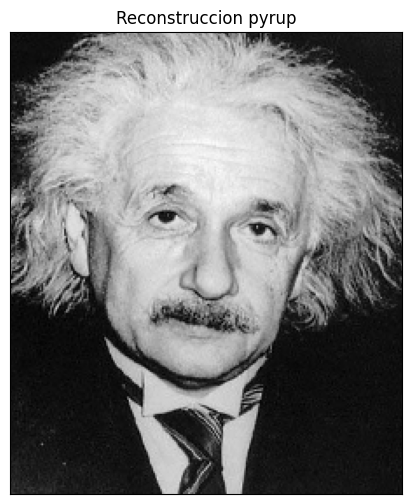

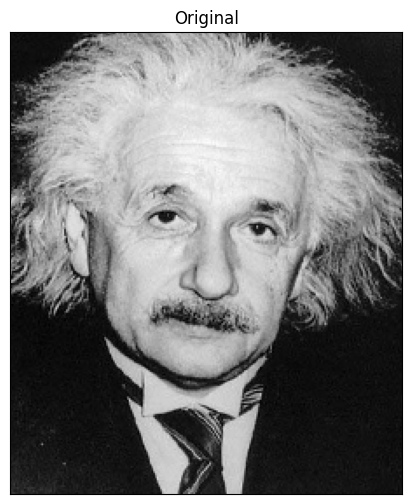

Error per pixel recons up 0.0


In [ ]:
def pyramidLapPyrUp(im, sizeMask,nlevel=4  ):

  # Cálculo de pirámide Gaussiana
  pyrG = pyramidGauss(im,sizeMask,nlevel)
  pyrL = []

  # Para cada nivel, expandimos la imagen de nivel superior de la gaussiana
  # a tamaño del nivel actual de la gaussiana. Por último le restamos a
  # la Gaussiana de nivel "i" la gaussiana de nivel "i+1" expandida.
  for i in range(nlevel):

    im_exp = cv2.pyrUp(pyrG[i+1], dstsize=(pyrG[i].shape[1], pyrG[i].shape[0]))
    next = pyrG[i] - im_exp
    pyrL.append(next)

  # Se termina añadiendo el último nivel de la gaussiana ( coincide con el
  # último nivel de laplaciana )
  pyrL.append(pyrG[nlevel])

  return pyrL

im=cv2.imread(get_image('einstein.bmp'),0).astype(np.float64)
pyrL = pyramidLapPyrUp(im,sizeMask=7, nlevel=4)
recons_up = reconstructLapPyrUp(pyrL)
displayIm(recons_up,'Reconstruccion pyrup')
displayIm(im,'Original')
#A CUBRIR POR EL ALUMNADO
print('Error per pixel recons up',np.sqrt(np.mean((im - np.round(recons_up)) ** 2)))

Efectivamente, al construir la Laplaciana y reconstruir con pyrUp, la reconstrucción es exacta.

### APARTADO 3 (0.5 puntos)

Las herramientas de IA generativa son de gran utilidad tanto para estudiantes como para docentes. No obstante, resulta fundamental tener una actitud crítica y asumir desde el principio que las respuestas proporcionadas por estas herramientas pueden ser factualmente incorrectas (véase,  por ejemplo, https://elpais.com/tecnologia/2024-09-25/los-nuevos-modelos-de-ia-como-chatgpt-persiguen-la-superinteligencia-pero-no-logran-ser-fiables-ni-en-preguntas-bobas.html o https://maldita.es/malditobulo/20250827/grok-identifica-mal-fotografia-franquismo/). En este sentido, vale la pena recordar lo que indica la guía de la UGR (https://ceprud.ugr.es/formacion-tic/inteligencia-artificial): _"Debes revisar siempre la salida que genera y las posibles referencias que utilice. [...] Mejora tus resultados con la IAGen aprendiendo a usarla y a comunicarte con ella de manera adecuada. Pero no dejes que piense por ti."_

En este apartado trabajaremos de forma crítica la utilidad de estas herramientas. Para ello, el alumnado debe emplear ChatGPT (https://chatgpt.com/) para analizar si es posible reconstruir a la perfección (`Error per pixel 0.0`) la imagen original por medio de una pirámide Laplaciana construida a partir de una pirámide Gaussiana sin suavizado (es decir, una pirámide no realmente Gaussiana, construida exclusivamente en base a hacer subsampling). Deben indicarse tanto los prompts empleados, como los razonamientos o experimentos llevados a cabo para concluir si lo que la herramienta de IA afirmaba era correcto o no. Muy importante: no se trata meramente de copiar lo que indique ChatGPT como salida, sino de analizar y matizar su respuesta, confrontándola con otras lecturas y lo que el estudiante sabe de la teoría, indicando en qué aspectos dicha respuesta puede considerarse correcta y en qué aspectos quizás no lo es.

**<h1>RESPUESTA</h1>**

<h1><b>PROMPT 1:</b></h1>
¿Es posible reconstruir a la perfección (Error per pixel 0.0) la imagen original por medio de una pirámide Laplaciana construida a partir de una pirámide Gaussiana sin suavizado (es decir, una pirámide no realmente Gaussiana, construida exclusivamente en base a hacer subsampling)?
<h1><b>Respuesta (Parcial):</b></h1>

Si construyes la pirámide “Gaussiana” sin suavizado, solo haciendo subsampling:

- Estás saltándote el filtro Gaussiano, así que estás simplemente tomando píxeles espaciados.

- Esto introduce aliasing: al reducir la resolución sin suavizar, la información de alta frecuencia se pliega sobre frecuencias bajas.

- Cuando intentas reconstruir la imagen mediante la pirámide Laplaciana, esa información “plegada” ya se perdió. No hay forma de recuperarla.



Este razonamiento aparentemente tiene sentido. Parece lógico que si simplemente eliminamos filas y columnas pares o impares, las altas frecuencias se pueden plegar y perder información. Además, viendo la diapositiva 23 del tema 2.3, se puede ver la diferencia entre aplicar blurr o no a la hora de construir la pirámide Gaussiana. Vamos a construir la pirámide no Gaussiana, es decir, simplemente haciendo subsampling de nuestra imagen para ver qué sucede.

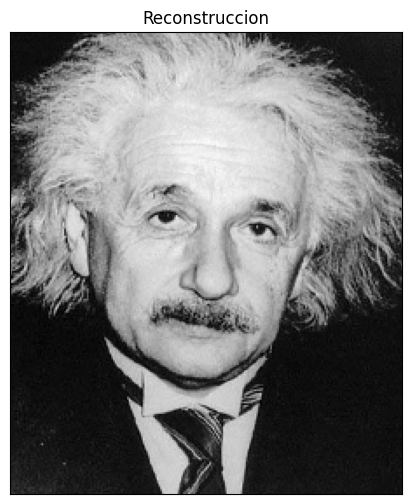

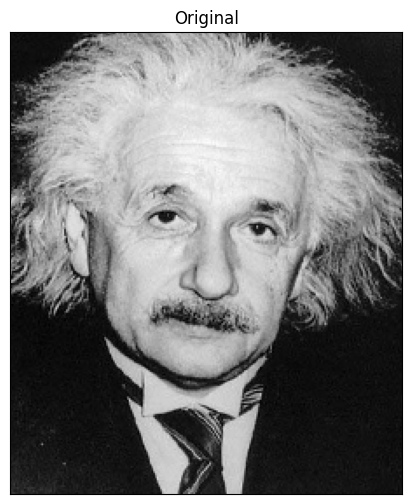

Error per pixel 0.0


In [ ]:
def pyrNoFilter(im, nlevel=4 ):
  #A CUBRIR POR EL ALUMNADO

  # La primera imagen es la imagen de partida
  pir = [im]

  # Para cada nivel nos quedamos con las filas y columnas pares.
  for i in range(nlevel):
    pir.append(pir[i][::2,::2])

  return pir

def pyramidLapNoFilter(im, nlevel=4,flagInterp=cv2.INTER_LINEAR  ):

  # Cálculo de pirámide NO Gaussiana
  pyrG = pyrNoFilter(im,nlevel)
  pyrL = []

  # Para cada nivel, expandimos la imagen de nivel superior de la piramide
  # a tamaño del nivel actual de la piramide. Por último le restamos a
  # la piramide de nivel "i" la piramide de nivel "i+1" expandida.
  for i in range(nlevel):

    im_exp = cv2.resize(pyrG[i+1], (pyrG[i].shape[1], pyrG[i].shape[0]), flagInterp)
    next = pyrG[i] - im_exp
    pyrL.append(next)

  # Se termina añadiendo el último nivel de la piramide ( coincide con el
  # último nivel de laplaciana )
  pyrL.append(pyrG[nlevel])

  return pyrL

im=cv2.imread(get_image('einstein.bmp'),0).astype(np.float32)

pyrL = pyramidLapNoFilter(im, nlevel=4)
recons = reconstructLap(pyrL,cv2.INTER_LINEAR)
displayIm(recons,'Reconstruccion')
displayIm(im,'Original')
#A CUBRIR POR EL ALUMNADO
print('Error per pixel',np.sqrt(np.mean((im - np.round(recons)) ** 2)))

Los resultados tanto visuales como numéricos indican que la reconstrucción es perfecta, lo que contradice la respuesta de la IA. Vamos a llevar a cabo el mismo experimento que en apartados anteriores. Se generan 100 imágenes aleatorias  y se reconstruye utilizando la pirámide no Gaussiana para comprobar en general como se comporta este método.

In [ ]:
rows, cols = 256, 256

num_distintas = 0

for i in range(100):
    img = np.random.randint(0, 256, (rows, cols), dtype=np.uint8)


    pyrL = pyramidLapNoFilter(img, nlevel=4)
    recons = reconstructLap(pyrL,cv2.INTER_LINEAR)

    error = np.sqrt(np.mean((np.round(img.astype(np.float64)) - np.round(recons.astype(np.float64))) ** 2))

    if error > 0:
      num_distintas = num_distintas + 1


print('Numero de reconstrucciones distintas ', num_distintas)

Numero de reconstrucciones distintas  0


Este breve experimento vuelve a contradecir la respuesta proporcionada por chatGPT, pero entonces ¿ Por qué puede pasar esto ?

Aunque construyamos la pirámide sin aplicar blurr en cada nivel, la imagen original sigue siendo el nivel 0 de la pirámide. Al construir la Laplaciana a partir de esta primera pirámide, se restan niveles consecutivos de esta pirámide. En la reconstrucción podemos acceder al nivel más alto de la pirámide y junto con el resto de la nueva laplaciana, podemos reconstruir cada nivel de la pirámide no Gaussiana sumando lo que habíamos restado previamente en la construcción de la Laplaciana. Es por esto que eventualmente se accede al nivel más bajo de la pirámide, es decir, la imagen original.

Además, no se puede probar algo porque sea frecuente, pero el hecho de que obtengamos una reconstrucción perfecta tanto en la imagen de Einstein como en 100 imágenes aleatorias, parece indicar que la reconstrucción es exacta en cualquier ejemplo.

Entonces, si la reconstrucción de la imagen es exacta si no aplicamos blurr ¿ Por qué desde el principio se nos pide construir esta pirámide con blurr si añade complejidad al código ? Pues porque las pirámides no se utilizan exclusivamente para reconstruir imágenes. Como vemos en la diapositiva 23 del tema 2.3, al ampliar las imágenes al mismo tamaño, es mucho más ruidosa las imágenes de las pirámides sin aplicar blurr, por lo que en el visualizado de la totalidad de la pirámide, en los niveles más altos se puede perder calidad.

# **Ejercicio 3: Imágenes Híbridas** (1.5 puntos)

Este ejercicio se basa en el siguiente trabajo: $\textit{Oliva, A., Torralba, A., & Schyns, P. G. (2006). Hybrid images. ACM Transactions on Graphics (TOG), 25(3), 527-532}$ (https://stanford.edu/class/ee367/reading/OlivaTorralb_Hybrid_Siggraph06.pdf).

Vamos a profundizar un poco en cómo el sistema visual humano extrae información sobre un objeto en función de la distancia. Para ello, construimos una imagen híbrida a partir de dos imágenes de objetos diferentes. Mezclando adecuadamente parte de las altas frecuencias de una imagen con parte de las bajas frecuencias de la otra, obtenemos una imagen híbrida que muestra diferentes percepciones con la distancia.

El sigma empleado para filtrar ambas imágenes (tanto la de alta como la de bajas frecuencias) es el aspecto clave para seleccionar el rango de frecuencias altas y bajas de cada imagen. Cuanto mayor sea el valor sigma, mayor será la eliminación de altas frecuencias de la imagen. Se recomienda elegir este valor por separado para cada una de las imágenes y, de hecho, es deseable tener distintos valores para distintos pares de imágenes.

Aspectos de importancia en relación a este ejercicio:

1. Como mínimo, se deben generar las imágenes híbridas correspondientes a `'plane.bmp'+'bird.bmp'` y `'bicycle.bmp'+'motorcycle.bmp'` (ambas parejas en escala de grises). Y también el alumnado debe escoger, como mínimo, otro par de imágenes de su elección a hibridar en color, fuera de las incluidas en la carpeta compartida en Drive (https://drive.google.com/drive/folders/1UtvY8q6w1Cz9a9T9zxIqSweoRLgNwoW-). Es decir, como mínimo, debe haber $3$ pares de imágenes híbridas como parte de la respuesta a este ejercicio. Se debe emplear una pirámide Gaussiana con $5$ niveles para mostrar el efecto obtenido.

**Nota:** de cara a emplear imágenes que no estén en el repositorio compartido, se recomienda que el alumnado emplee un código como el que se muestra a continuación, y que permite descargar sobre la marcha imágenes a partir de una URL dada.






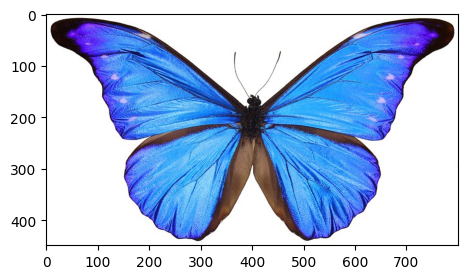

In [ ]:
import requests
def downloadImage(url):
    response = requests.get(url)
    img_array = np.frombuffer(response.content, np.uint8)
    img = cv2.imdecode(img_array, cv2.IMREAD_COLOR)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = img.astype(np.float64)/255
    return img
try:
    smiley_im = downloadImage("https://images.rawpixel.com/image_800/cHJpdmF0ZS9sci9pbWFnZXMvd2Vic2l0ZS8yMDIyLTA1L2ZsMTI5Mjk0MTAxNjUtaW1hZ2Uta3liZW9jNjEuanBn.jpg")
    plt.imshow(smiley_im)
except:
    print("Couldn't download the image from the given URL")

2. No es necesario seguir al pie de la letra el artículo de referencia y operar en el dominio de la frecuencia (Fourier). Basta con operar en el dominio del espacio, como hemos hecho en todos los demás apartados de esta práctica. No obstante, sí se debe emplear/buscar algún criterio objetivable/cuantificable a la hora de escoger qué imagen se empleará para las altas frecuencias y cuál para las bajas frecuencias. No basta con escogerla "a ojo" y, al contrario, se debe definir alguna métrica que permita realizar la selección.

3. En relación con el punto anterior, se debe explicar con claridad el proceso seguido para filtrar la imagen de altas frecuencias y la de bajas frecuencias, incluyendo la elección de los sigmas finalmente utilizados. La realización de una experimentación preliminar, por medio de prueba y error, es perfectamente válida, pero hay que explicarla y justificarla de algún modo. No basta con probar una serie de valores arbitrarios y justificarlo, sucintamente, indicando que *"se procedió por medio de prueba y error hasta obtener el sigma final"*.

**<h1>RESPUESTA</h1>**

Para la creación de imágenes híbridas, necesitamos hacer una selección de qué imagen es de altas frecuencias y cuál es de bajas frecuencias en un par de imágenes a hibridar.
Para ello utilizamos el análisis de Fourier en imágenes, que nos ayuda a ver las frecuencias de las imágenes. Para decidir qué imagen es de altas y de bajas, se define la función **GetMagnitud(img, cutoff_ratio)**. Esta función hace lo siguiente:


1.   Calcula la transformada de Fourier.
2.   Se lleva las frecuencias bajas de la transformada de Fourier.
3.   Se calcula la magnitud de esta imagen.
4.   Se quita el **cuttof_ratio** por ciento del dentro de la imagen que es donde residen las frecuencias bajas.
5.   Se calcula la magnitud de las frecuencias altas en relación con la magnitud total.

La imagen de altas frecuencias será la de mayor magnitud proporcional de altas frecuencias a total de las dos imágenes.

La función **HybridImage** calcula la imagen híbrida a partir de la imagen de altas y bajas frecuencias y de los sigmas relacionados para suavizar ambas. Para ello aplica el suavizado gaussiano a cada imagen con los sigmas pasados como parámetros y a la imagen de altas frecuencias, nos quedamos con la resta de esta imagen por su suavizado. Por último se devuelve la suma de esta última imagen y la suavizada de bajas frecuencias.




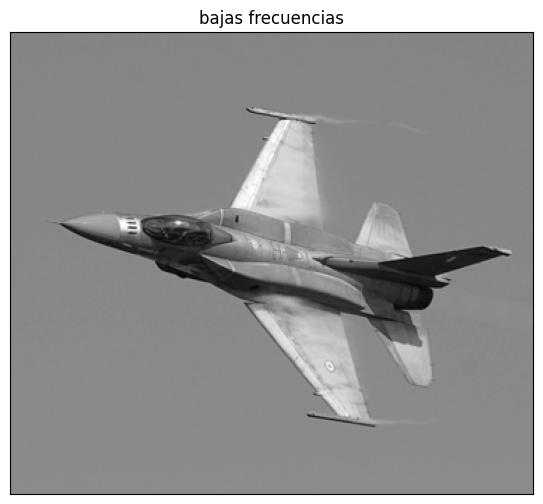

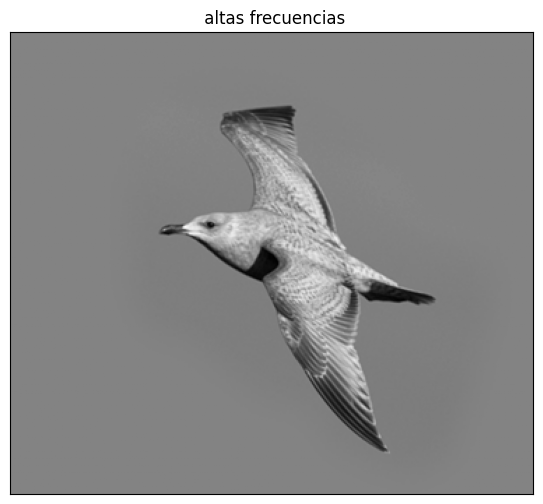

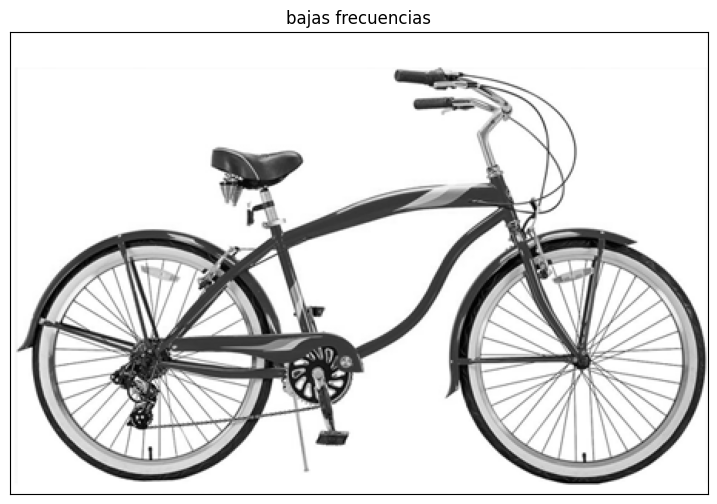

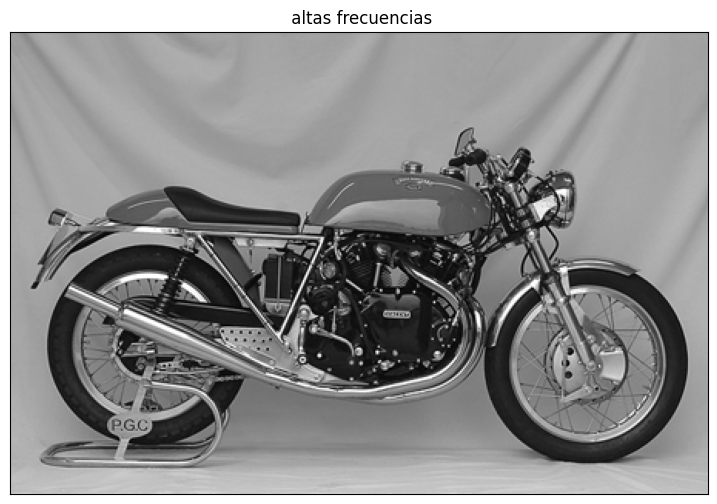

In [ ]:
#A CUBRIR POR EL ALUMNADO

def GetMagnitud(img, cutoff_ratio):

  # 1) Se calcula la transformada de Fourier
  FT = np.fft.fft2(img)

  # 2) Se llevan las frecuencias bajas al centro
  shifted = np.fft.fftshift(FT)

  # 3) Se calcula la FT magnitud
  magni = np.abs(shifted)

  # 4) Se quita el cuttof_ratio central
  fils, cols = img.shape[0], img.shape[1]
  radio = 0.25 * min(fils, cols)
  centro = (fils // 2, cols // 2)

  # Se utiliza esta función proporcionada por ChatGPT por cuestiones de
  # eficiencia, al pyhton manejar los bucles de manera muy lenta
  y, x = np.ogrid[:fils, :cols]
  distancia = np.sqrt((x - centro[1])**2 + (y - centro[0])**2)
  max_radio = distancia.max()

  # Creamos la máscara de los valores que están fuera de la bola de centro
  # centro de la imagen y radio cuttof_ratio * max_radio
  mask = ( distancia >= ( cutoff_ratio * max_radio) )

  # 5) Tomamos la relación entre la magnitud de las frecuencias altas y total
  magni_altas_freq = magni[mask].sum()
  magni_total = magni.sum()

  return (magni_altas_freq / magni_total)



def SelectLowHighFreq(img1, img2):

  # Calcula las magnitudes de cada imagen y devuelve el par de menor y mayor
  magnitud_1 = GetMagnitud(img1, 0.25)
  magnitud_2 = GetMagnitud(img2, 0.25)

  if magnitud_1 > magnitud_2:
    low, high = img2, img1
  else:
    low, high = img1, img2

  return low, high
def HybridImage(sigma_l, sigma_h, low_freq_im, high_freq_im):

  # Aplica los suavizados correspondientes

  high_smooth = my2DConv(high_freq_im, sigma_h, [0,0])
  low_smooth = my2DConv(low_freq_im, sigma_l, [0,0])
  # Se resta a la imagen de altas frecuencias su versión suavizada

  high_no_smooth = high_freq_im - high_smooth

  # Se devuelve la suma de esta última imagen y la suavizada de bajas frecuencias.
  return high_no_smooth + low_smooth

plane=cv2.imread(get_image('plane.bmp'),0)
plane = plane / 255
bird=cv2.imread(get_image('bird.bmp'),0)
bird = bird / 255


bicycle=cv2.imread(get_image('bicycle.bmp'),0)
bicycle = bicycle / 255
motorcycle=cv2.imread(get_image('motorcycle.bmp'),0)
motorcycle = motorcycle / 255

low, high = SelectLowHighFreq(plane, bird)

displayIm(low,'bajas frecuencias')
displayIm(high,' altas frecuencias')

low, high = SelectLowHighFreq(bicycle, motorcycle)

displayIm(low,'bajas frecuencias')
displayIm(high,' altas frecuencias')

Ahora vamos a seleccionar los sigmas para el suavizado de cada una de las imágenes. Para las imágenes de altas frecuencias, necesitaremos un suavizado de modo que no se aprecien apenas los detalles. Para las imágenes de bajas frecuencias, visualizaremos la pirámide de la imagen híbrida con distintos valores de sigma y seleccionaremos en base a qué tan bien se realiza la hibridación

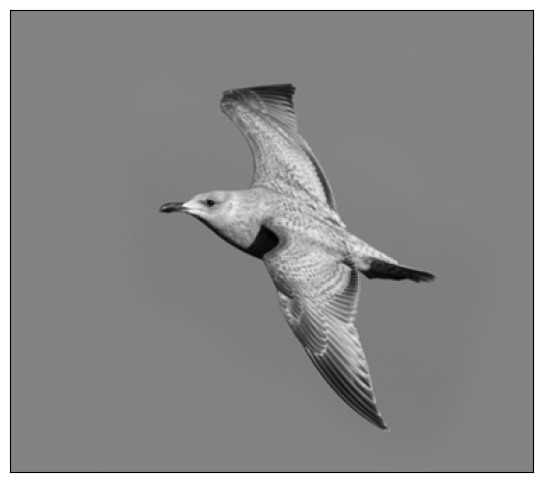

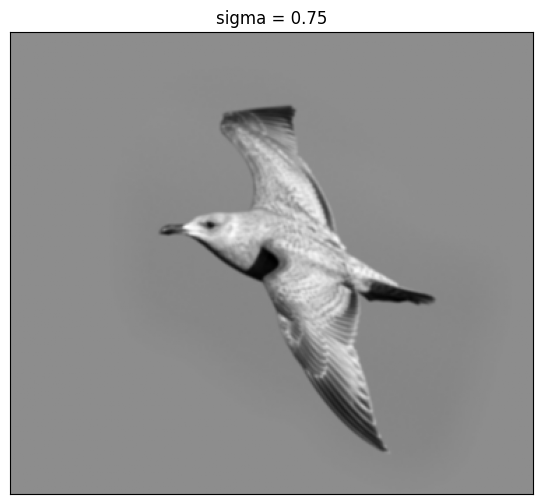

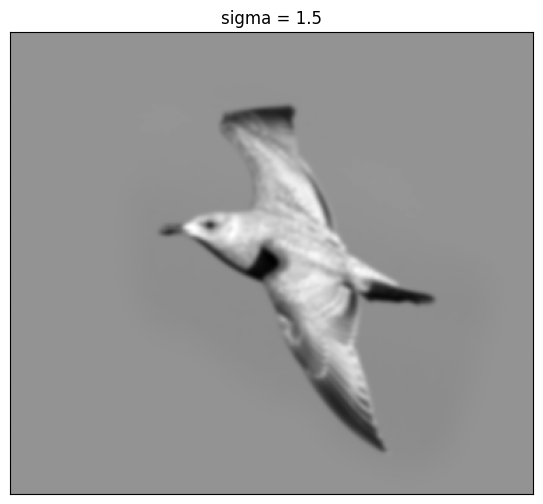

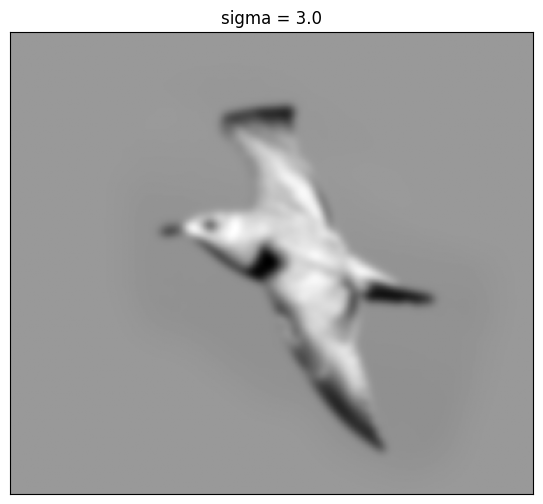

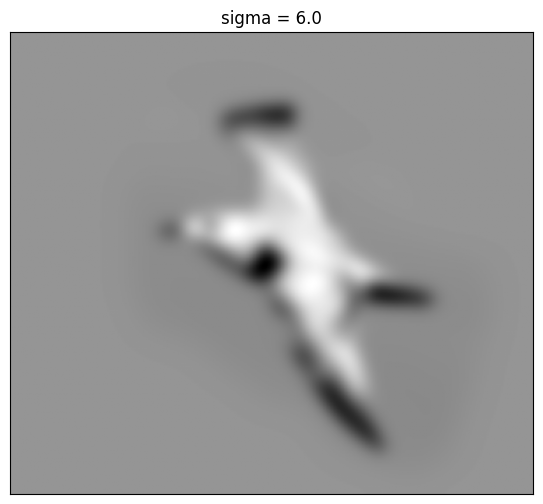

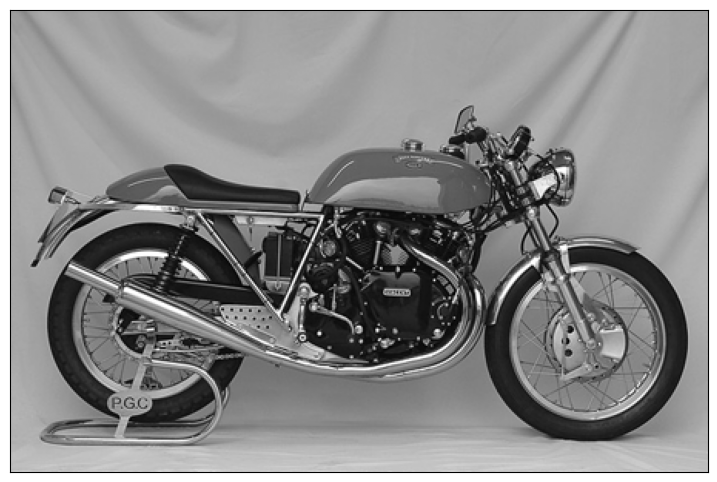

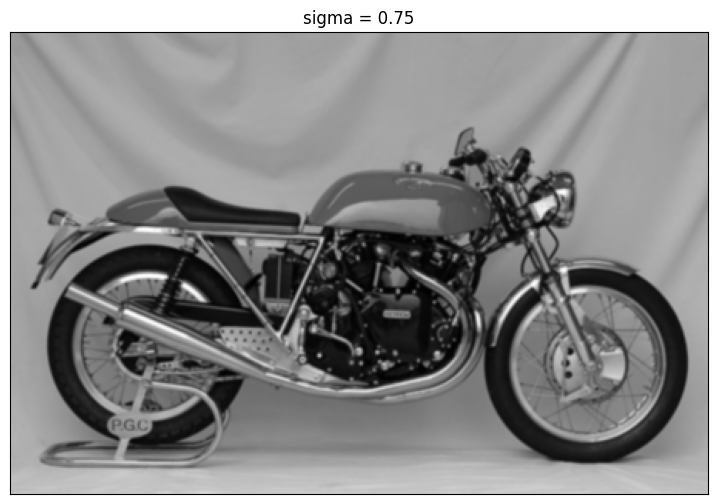

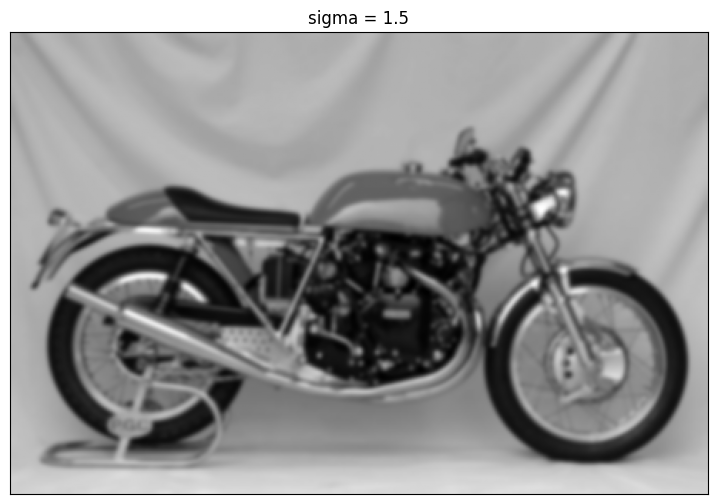

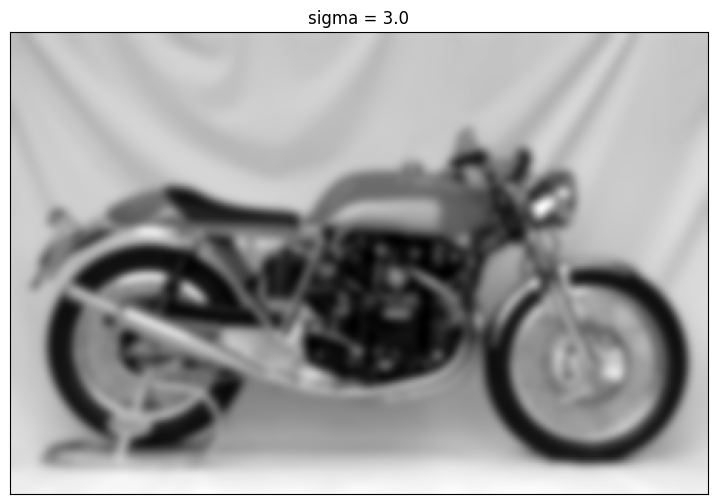

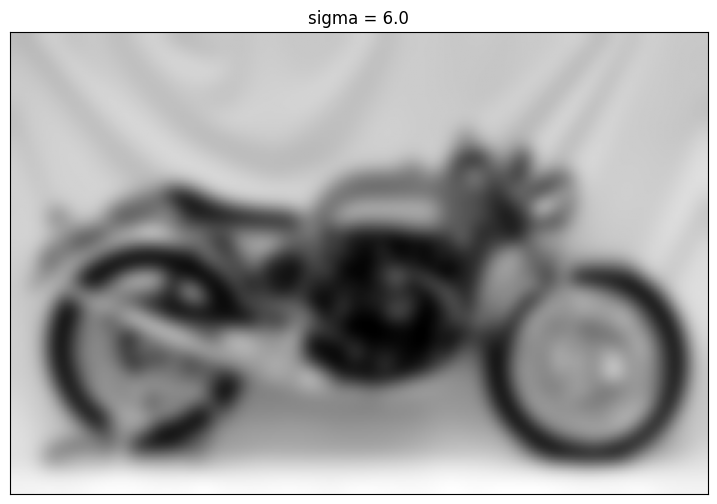

In [ ]:

sigmas = [0.75, 1.5, 3.0, 6.0]
displayIm(bird,'')
for sigma in sigmas:
  gauss = my2DConv(bird, sigma, [0,0])
  displayIm(gauss,'sigma = {}'.format(sigma))

displayIm(motorcycle,'')
for sigma in sigmas:
  gauss = my2DConv(motorcycle, sigma, [0,0])
  displayIm(gauss,'sigma = {}'.format(sigma))

Elección de sigmas:


*   Para el pájaro, empezamos a ver eliminaciones de detalles para los sigmas 3.0 y 6.0. En nuestro caso, seleccionamos **sigma_bird = 6.0** ya que si tomamos algo intermedio entre 3.0 y 6.0, empezaríamos a ver algo más de detalle ( para 6.0 podemos seguir viendo un poco de detalle y bajar el valor puede hacer que aparezcan más detalles) y si seleccionamos un sigma más alto se puede difuminar la estructura del pájaro.
*   Para la moto, vemos que para sigma = 3 se siguen viendo algunos detalles y para sigma = 6 la imagen es quizá demasiado difusa así que pasaremos a ver sigmas intermedios.



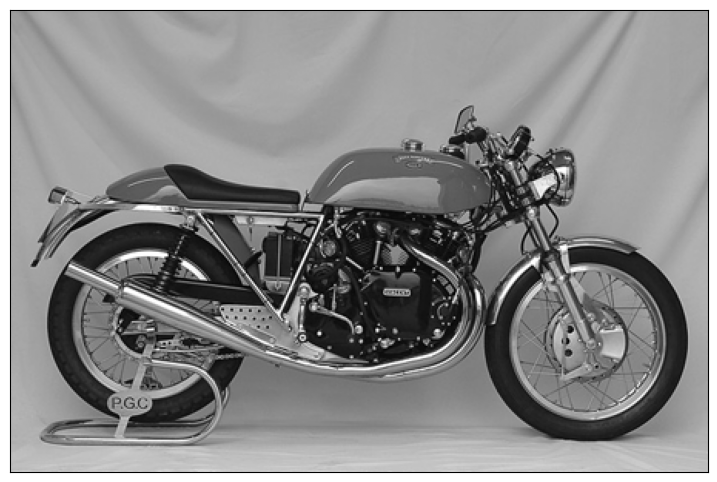

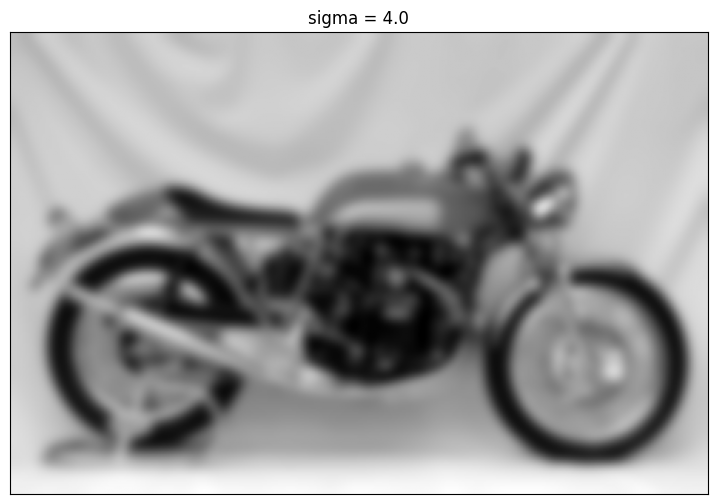

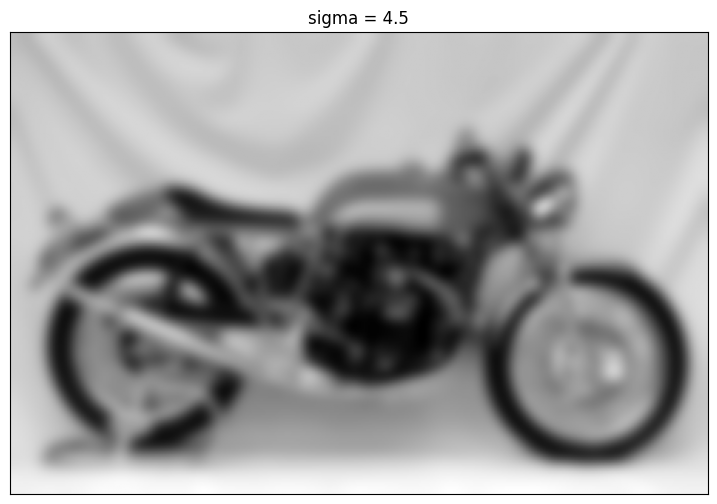

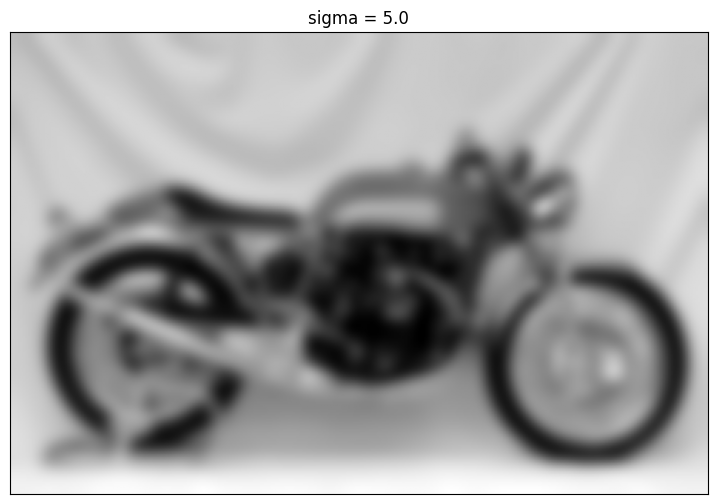

In [ ]:
sigmas = [4.0, 4.5, 5.0]
displayIm(motorcycle,'')
for sigma in sigmas:
  gauss = my2DConv(motorcycle, sigma, [0,0])
  displayIm(gauss,'sigma = {}'.format(sigma))

Los sigmas 4.0 y 4.5 dan resultados bastante parecidos, así que seleccionamos **sigma_moto = 4.5**.

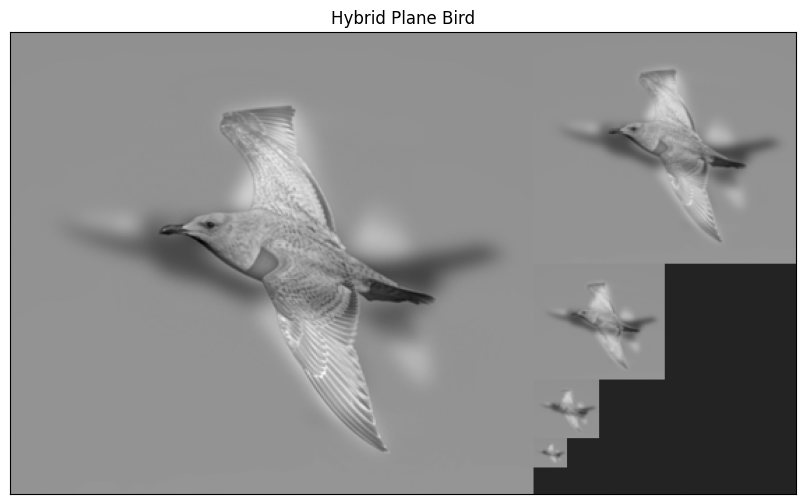

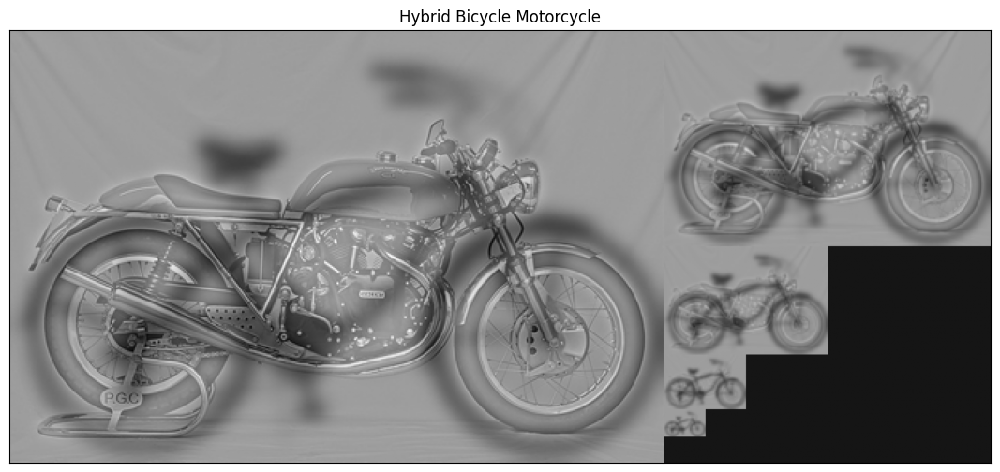

In [ ]:
sigma_bird = 6.0
sigma_moto = 4.5
sigma_plane = 6.0
sigma_bici = 6.0

hybrid_plane_bird = HybridImage(sigma_plane,sigma_bird,plane, bird)
pyrG = pyramidGauss(hybrid_plane_bird,sizeMask=7, nlevel=4)

displayPyramid(pyrG,'Hybrid Plane Bird')

hybrid_b_m= HybridImage(sigma_bici,sigma_moto ,bicycle, motorcycle)
pyrG = pyramidGauss(hybrid_b_m,sizeMask=7, nlevel=4)

displayPyramid(pyrG,'Hybrid Bicycle Motorcycle')

Una vez visualizadas las pirámides, seleccionamos el sigma relativo a las imágenes de bajas frecuencias. Como se observa, hay un buen resultado en cuanto a la imagen híbrida, obteniendo en los niveles más bajos la imagen de altas frecuencias, en los más altos la de bajas frecuencias y en el nivel intermedio, una mezcla de ambas.

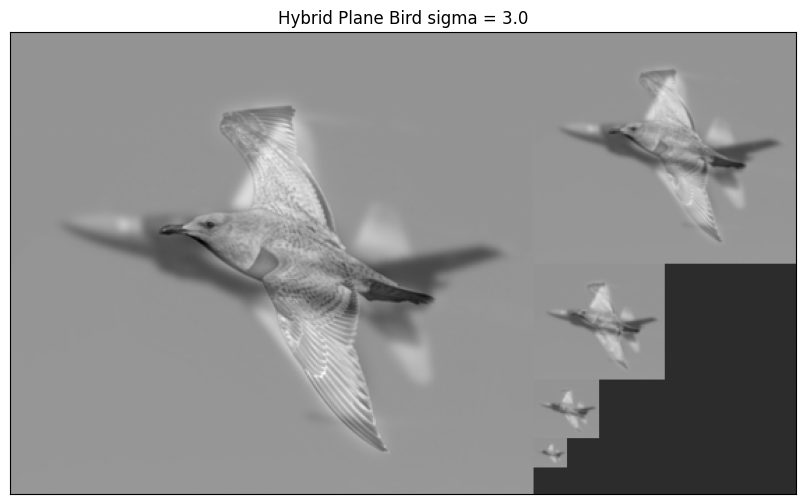

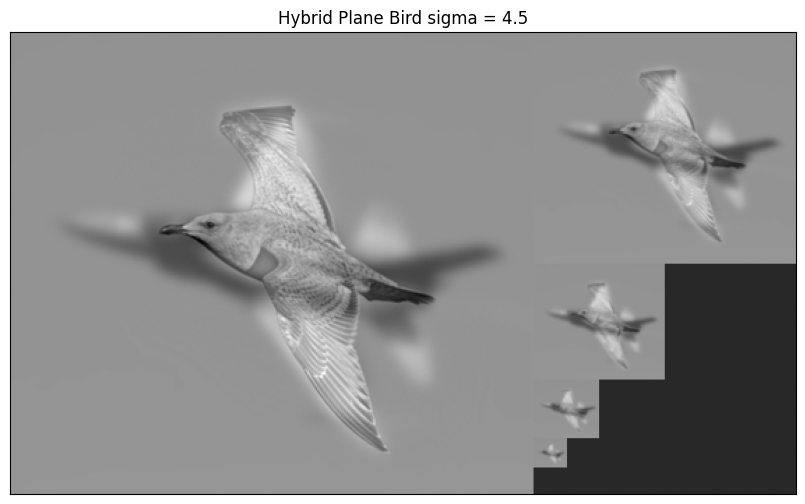

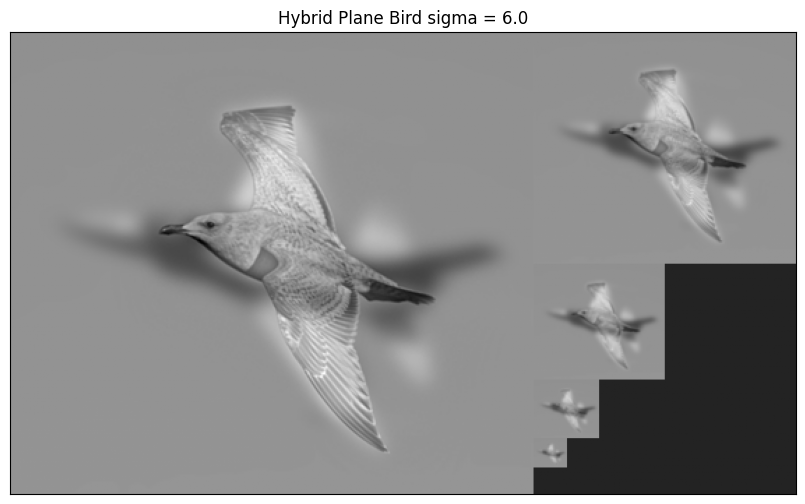

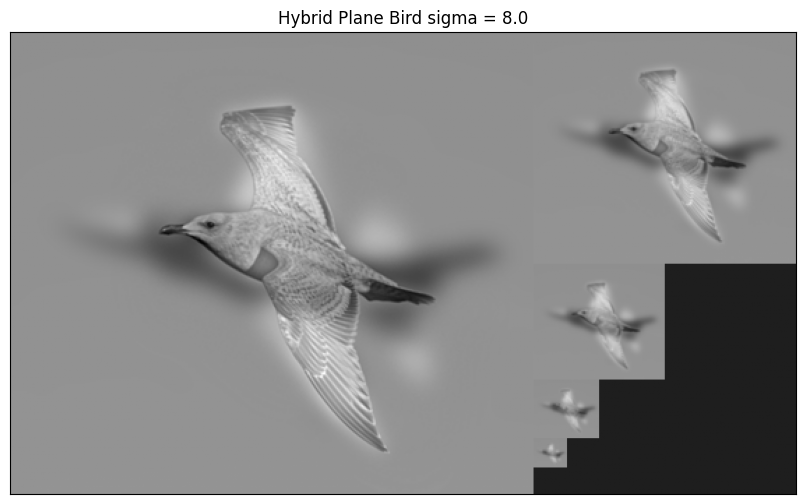

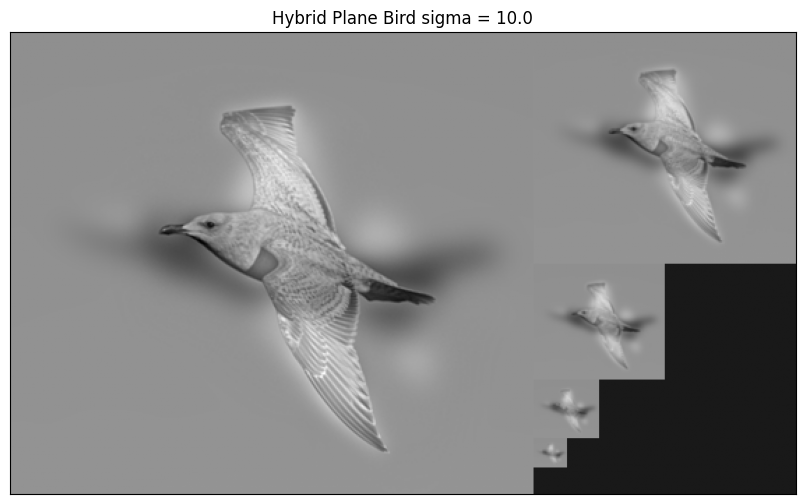

In [ ]:
sigma_bird = 6.0
sigma_moto = 4.5
sigmas_plane = [3.0, 4.5, 6.0, 8.0, 10.0]


for sigma_plane in sigmas_plane:
  hybrid_plane_bird = HybridImage(sigma_plane,sigma_bird,plane, bird)
  pyrG = pyramidGauss(hybrid_plane_bird,sizeMask=7, nlevel=4)

  displayPyramid(pyrG,'Hybrid Plane Bird sigma = {}'.format(sigma_plane))



Entre todos los valores posibles, las pirámides que mejor representan la hibridación son para **sigma_plane = 6.0 y sigma_plane = 8.0**. Se selecciona el valor 6.0 porque pese a que se ve un poco más en los niveles más bajos el avión, creo que merece la pena que en los niveles intermedios y altos se aprecie el avión con algo más de detalle.

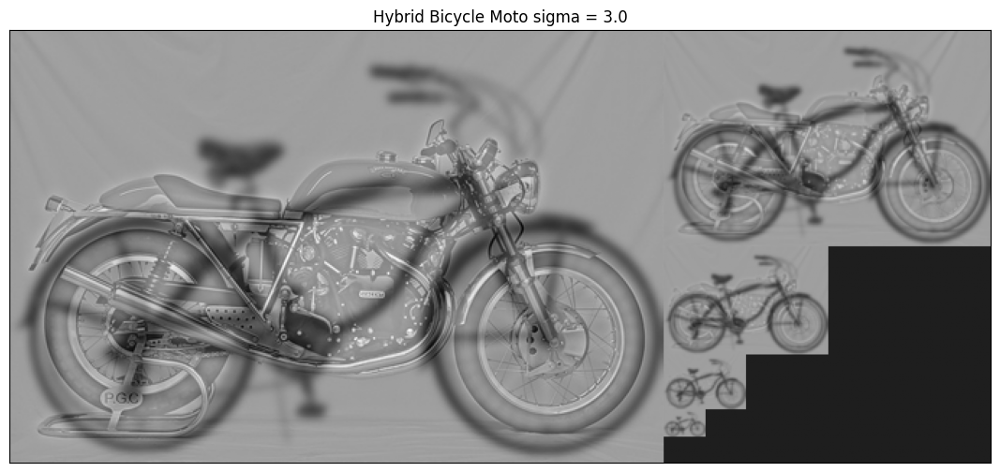

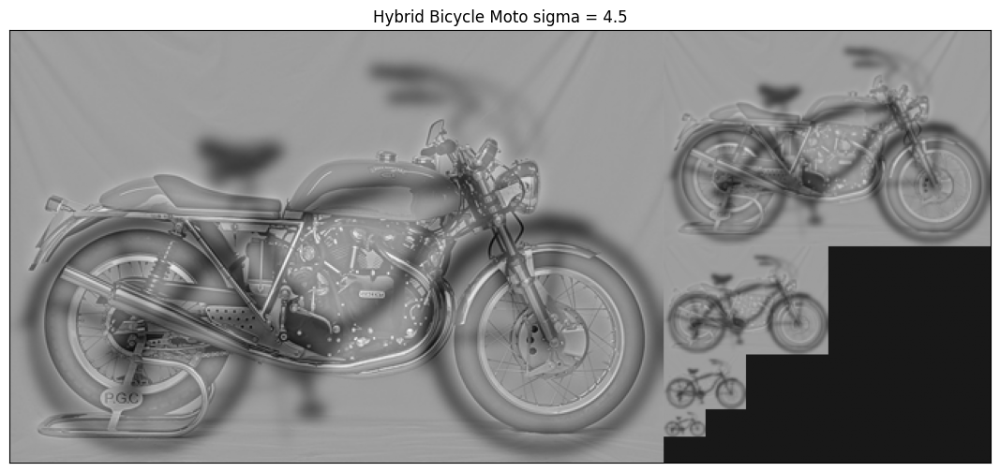

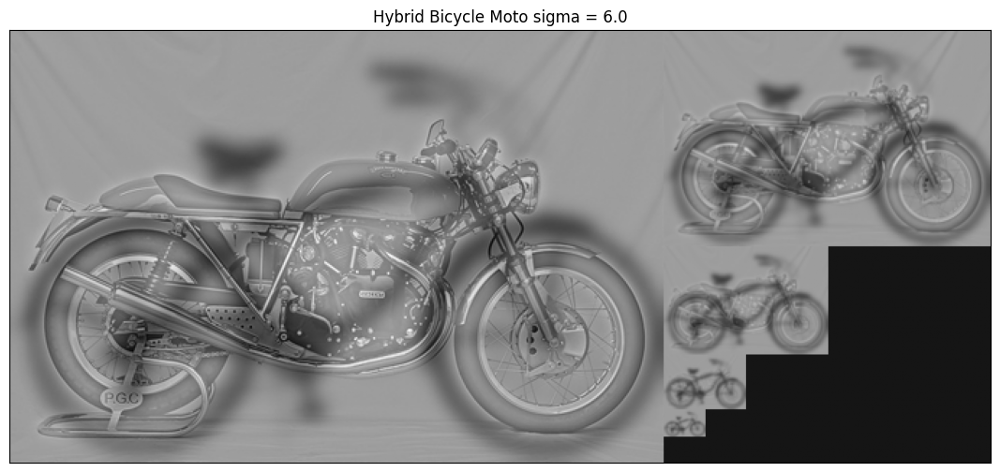

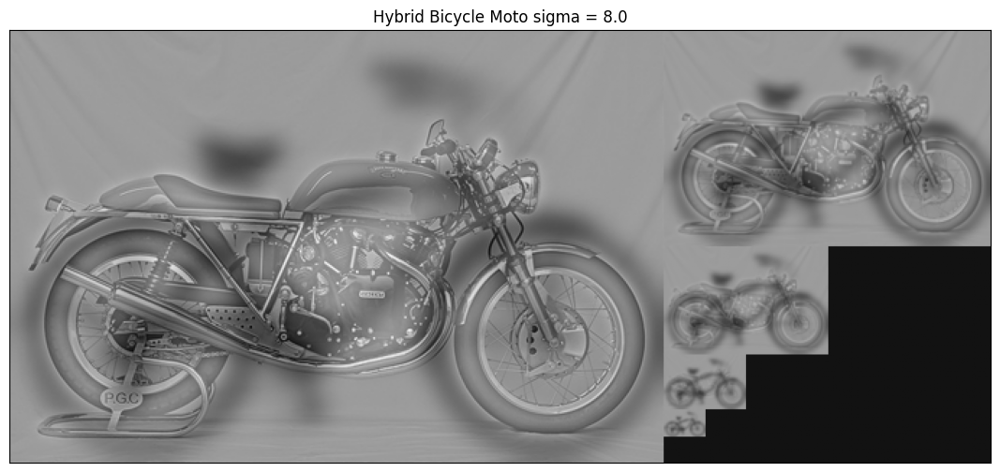

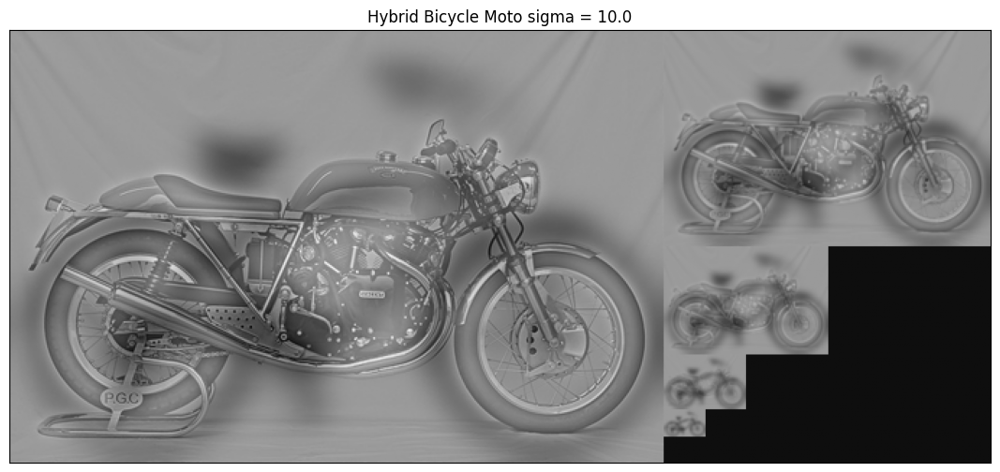

In [ ]:
sigmas_bici = [3.0, 4.5, 6.0, 8.0, 10.0]
for sigma_bici in sigmas_bici:
  hybrid_b_m= HybridImage(sigma_bici,sigma_moto ,bicycle, motorcycle)
  pyrG = pyramidGauss(hybrid_b_m,sizeMask=7, nlevel=4)
  displayPyramid(pyrG,'Hybrid Bicycle Moto sigma = {}'.format(sigma_bici))

En este caso, seleccionamos **sigma_bici = 8.0** pues estamos en una situación similar a la hibridación anterior, pero quizá se aprecia más la bici en los niveles bajos y por eso subimos un poco más el valor del sigma, para apreciar mejor la motocicleta.

Vamos ahora a pasar a trabajar con imágenes a color. Las imágenes seleccionadas son las siguientes.

**NOTA: Durante el desarrollo de la práctica he tenido un problema con la primera URL y es que por algún motivo al principio se descargaba la imagen correctamente pero a los días dejó de funcionar ( creo que por algo de URL dinámica) . Se ha cambiado la URL ( es la misma imagen ) y no garantizo que en futuras ejecuciones no haya error. He intentado buscar solución pero no he conseguido acceder a la URL estática.**

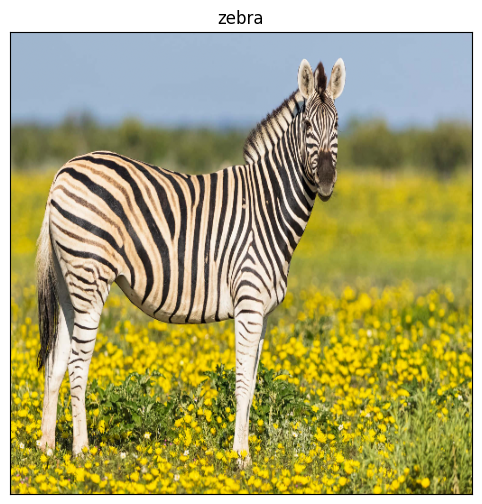

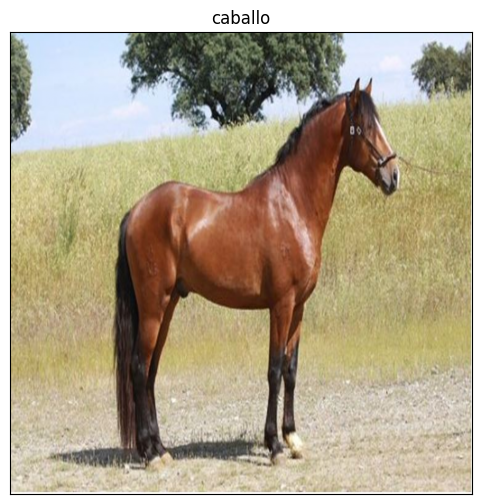

In [ ]:

try:
    zebra_color = downloadImage('https://wallpapers.com/images/featured/imagenes-de-cebra-y703q3fbii2nopj6.jpg')
    zebra_color = cv2.resize(zebra_color,(512,512),cv2.INTER_LINEAR)
    displayIm(zebra_color,'zebra')

except:
    print("Couldn't download the image from the given URL")

try:
    caballo_color = downloadImage('https://1.bp.blogspot.com/-xFAG1P3uYSs/XsTtOYD7rzI/AAAAAAAAIv8/yOVuT8CB5nUVNd97LpZCFNTCAo0n6zLvACLcBGAsYHQ/s1600/CABALLO2.jpg')
    caballo_color = cv2.resize(caballo_color,(512,512),cv2.INTER_LINEAR)
    displayIm(caballo_color,'caballo')
except:
    print("Couldn't download the image from the given URL")

Procedemos ahora a la selección de la imagen de altas y bajas frecuencias.

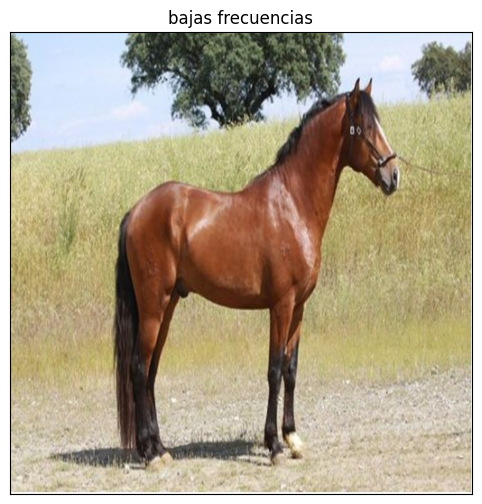

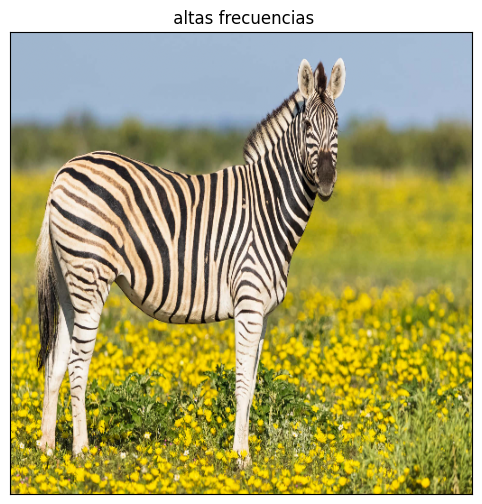

In [ ]:
low, high = SelectLowHighFreq(caballo_color, zebra_color)

displayIm(low,'bajas frecuencias')
displayIm(high,' altas frecuencias')

Como se puede apreciar, la imagen de altas y bajas frecuencias coincide con la intuición inicial. La zebra tiene mucho detalle en las rayas, así como en los elementos de fondo. Por contrario, la imagen del caballo es mucho más suave. Se necesita ahora seleccionar el sigma para el suavizado de ambas imágenes.

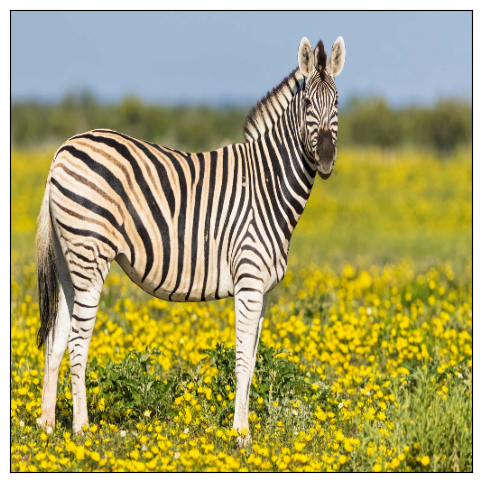

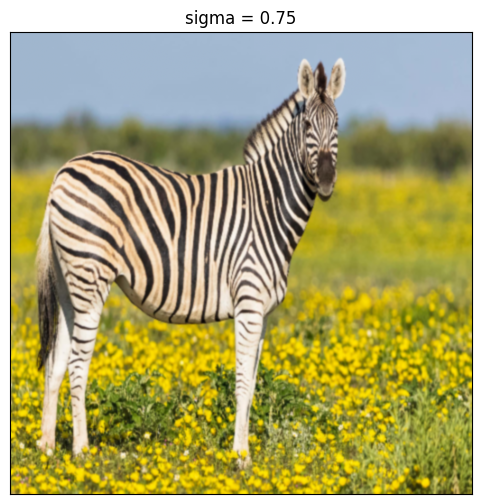

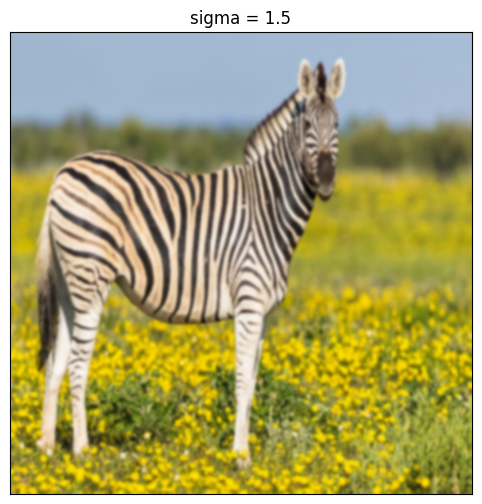

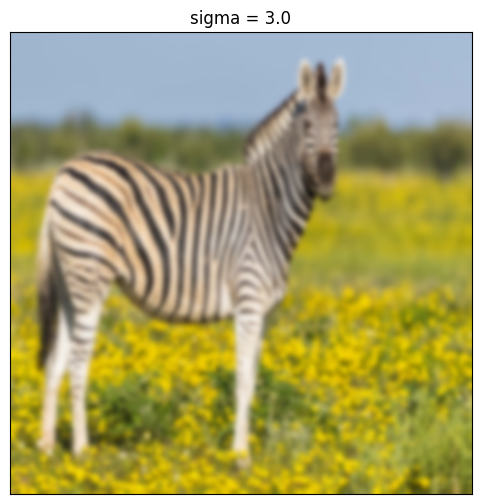

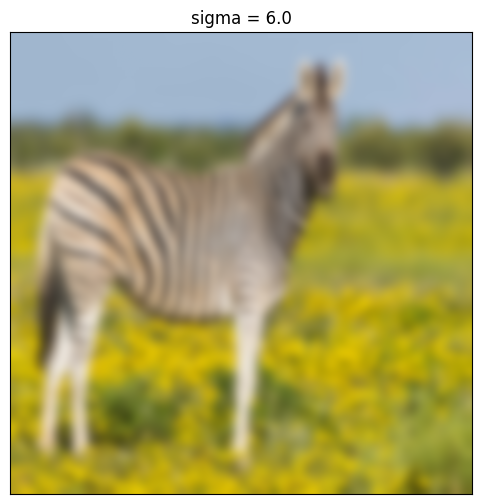

In [ ]:
displayIm(zebra_color,'')
sigmas = [0.75, 1.5, 3.0, 6.0]
for sigma in sigmas:
  gauss = my2DConv(zebra_color, sigma, [0,0])
  displayIm(gauss,'sigma = {}'.format(sigma))


Para la zebra, tras seleccionar el valor de sigma más alto se siguen apreciando algunos detalles por lo que necesitamos sigmas más altos.

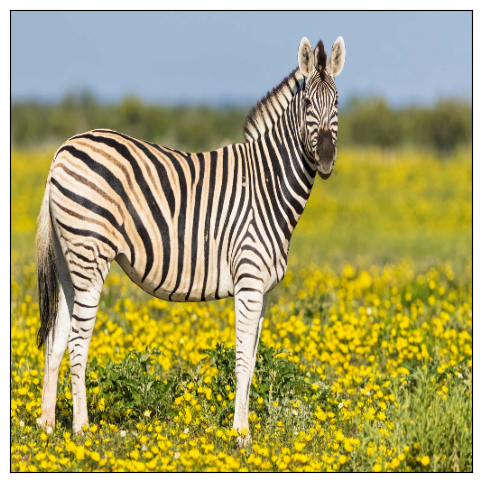

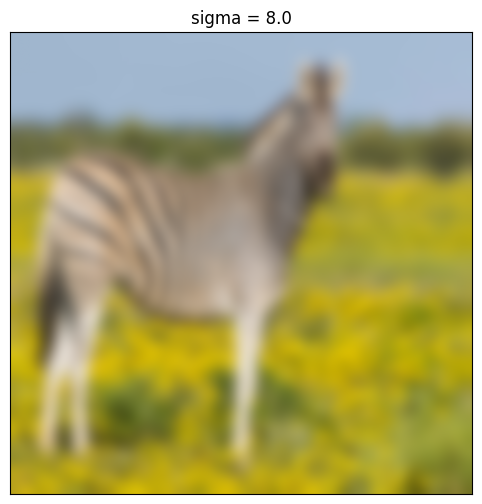

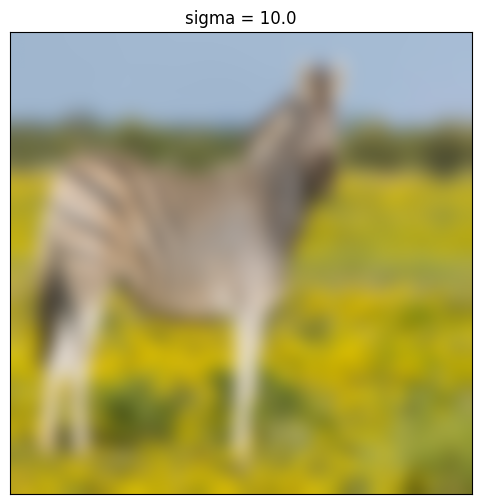

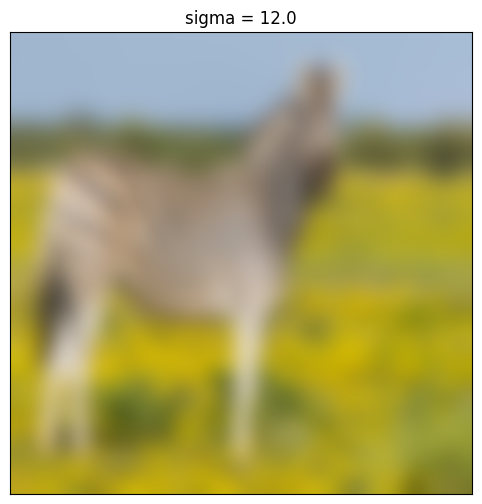

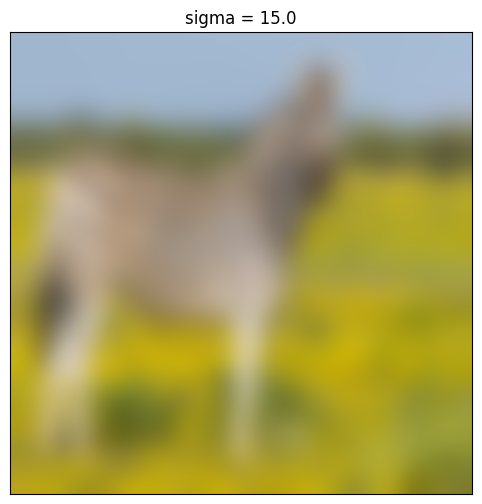

In [ ]:
displayIm(zebra_color,'')
sigmas = [8.0, 10.0, 12.0, 15.0]
for sigma in sigmas:
  gauss = my2DConv(zebra_color, sigma, [0,0])
  displayIm(gauss,'sigma = {}'.format(sigma))

Seleccionamos el valor sigma = 8.0 ya que vemos que se elimina bastante detalle. Ahora para el sigma del caballo, se visualiza la imagen utilizando sigmas diferentes hasta obtener la mejor calidad de imagen híbrida. En un inicio vamos a probar con sigma_caballo = 6.0 e iremos ajustando.

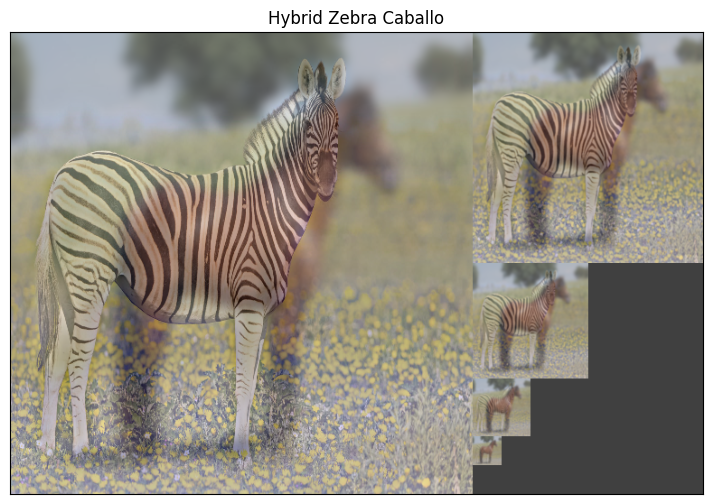

In [ ]:
sigma_zebra = 8.0
sigma_caballo = 6.0
hybrid_zebra_caballo = HybridImage(sigma_caballo, sigma_zebra, caballo_color, zebra_color)
pyrG = pyramidGauss(hybrid_zebra_caballo,sizeMask=7, nlevel=4)
displayPyramid(pyrG,'Hybrid Zebra Caballo')

Como se puede observar, quizá el caballo es algo predominante es las imágenes de nivel más bajo. Vamos a probar ahora con sigmas de mayores valores

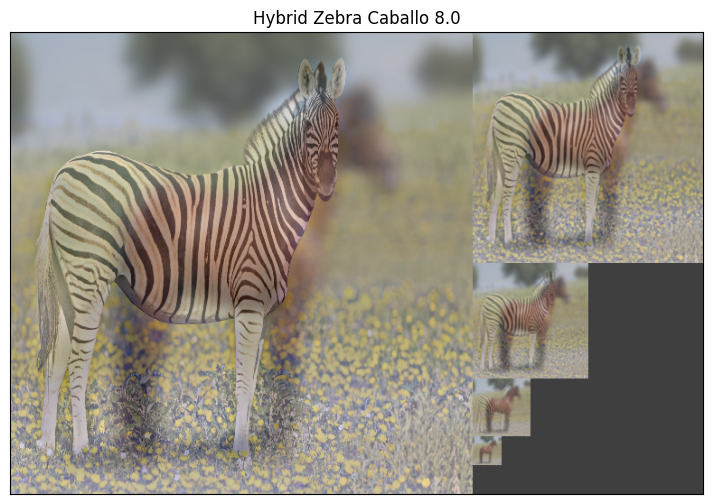

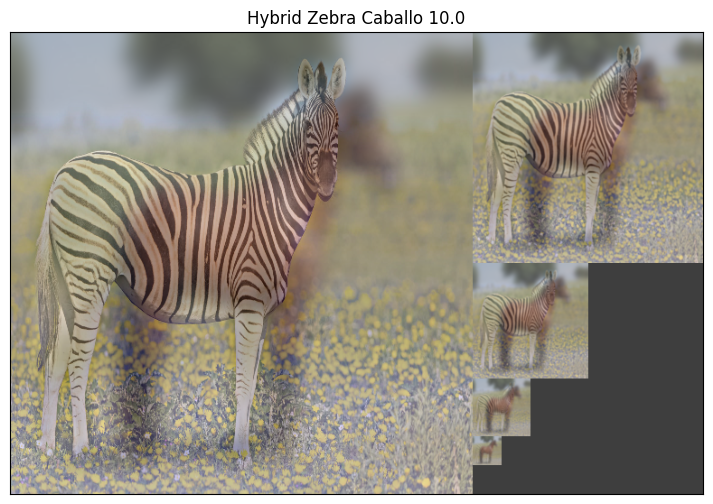

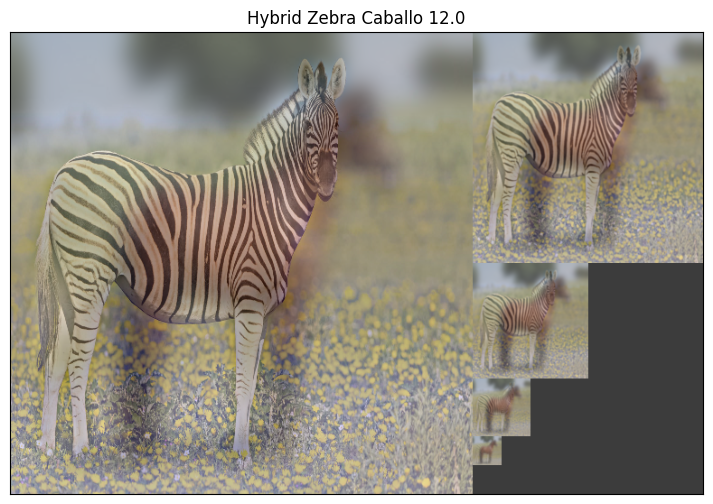

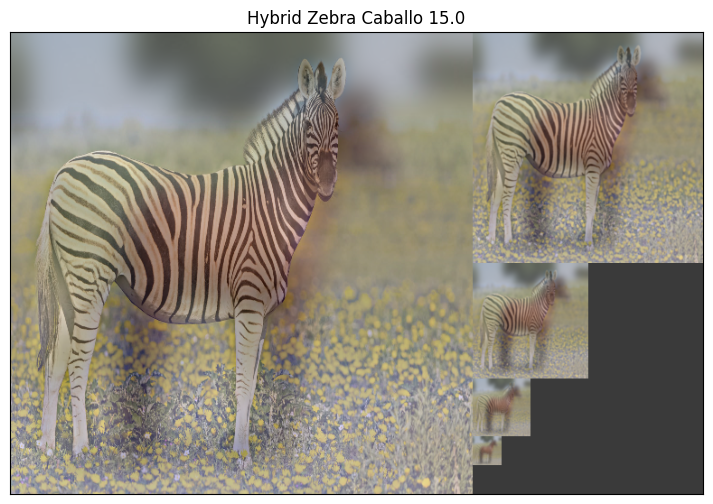

In [ ]:
sigmas = [8.0, 10.0, 12.0, 15.0]

for sigma_caballo in sigmas:
  hybrid_zebra_caballo = HybridImage(sigma_caballo, sigma_zebra, caballo_color, zebra_color)
  pyrG = pyramidGauss(hybrid_zebra_caballo,sizeMask=7, nlevel=4)
  displayPyramid(pyrG,'Hybrid Zebra Caballo {}'.format(sigma_caballo))

Nos decantamos por sigma_caballo = 15.0. El otro valor en duda era sigma_caballo = 12.0, pero quizá en el segundo nivel más bajo, seguía viéndose el caballo más de lo esperado. Con sigma_caballo = 15.0 podemos observar un equilibrio donde en los dos primeros niveles se observa la cebra más que el caballo, en el nivel intermedio ambos y en los dos niveles más altos predomina el caballo.

**<h1>Resultados Finales.</h1>**

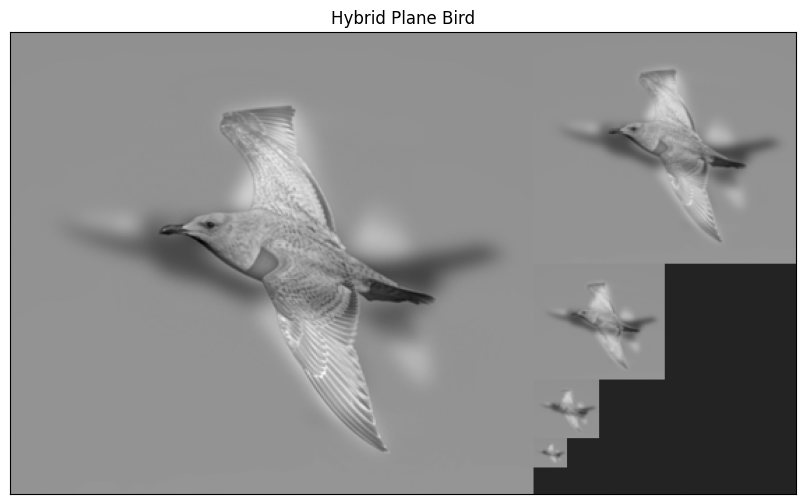

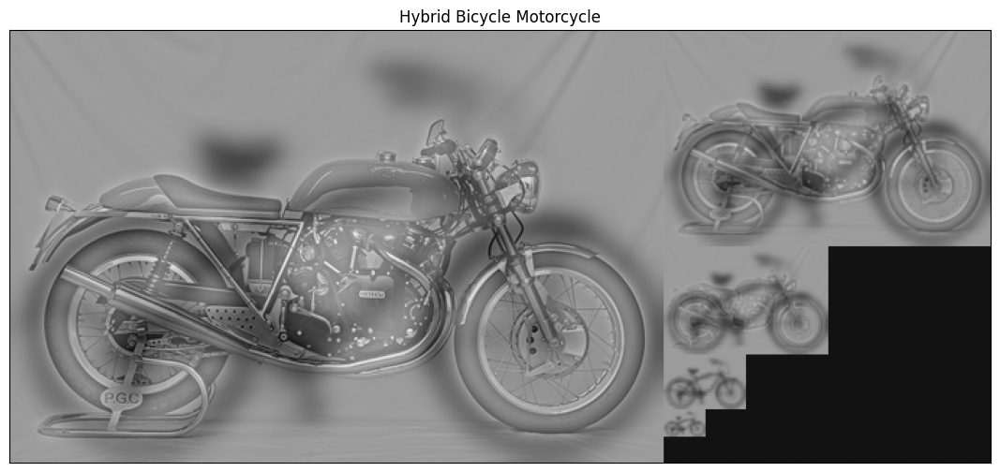

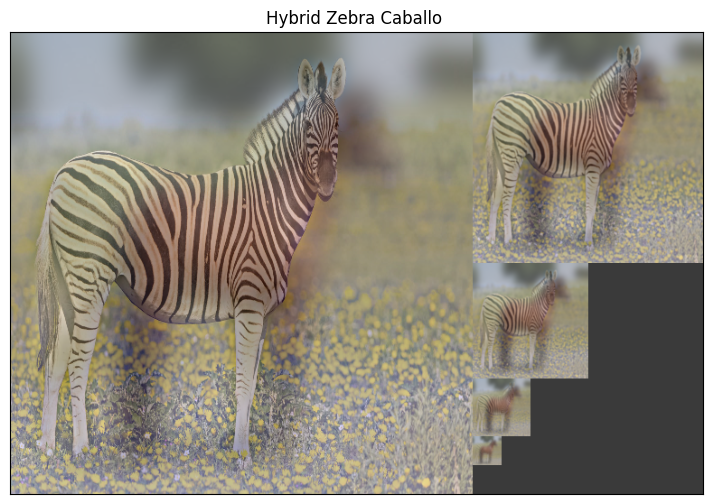

In [ ]:
sigma_bird = 6.0
sigma_moto = 4.5
sigma_plane = 6.0
sigma_bici = 8.0
sigma_zebra = 8.0
sigma_caballo = 15.0
hybrid_plane_bird = HybridImage(sigma_plane,sigma_bird,plane, bird)
pyrG = pyramidGauss(hybrid_plane_bird,sizeMask=7, nlevel=4)

displayPyramid(pyrG,'Hybrid Plane Bird')

hybrid_b_m= HybridImage(sigma_bici,sigma_moto ,bicycle, motorcycle)
pyrG = pyramidGauss(hybrid_b_m,sizeMask=7, nlevel=4)

displayPyramid(pyrG,'Hybrid Bicycle Motorcycle')

hybrid_zebra_caballo = HybridImage(sigma_caballo, sigma_zebra, caballo_color, zebra_color)
pyrG = pyramidGauss(hybrid_zebra_caballo,sizeMask=7, nlevel=4)
displayPyramid(pyrG,'Hybrid Zebra Caballo ')

# **Ejercicio 4: Canny Edge Detector** (1.5 puntos)

En este ejercicio se debe implementar el algoritmo de detección de bordes de Canny y evaluarlo con la imagen `cat.bmp`. Para ello, se deben emplear las funciones definidas hasta ahora en los ejercicios anteriores (de generación de kernels Gaussianos y convolución separable) para:

1. **Suavizar la imagen de entrada** para reducir el impacto del ruido. Se debe definir un $sigmaS$, que controlará el grado de suavizado de la imagen de entrada, cuyo valor debe ajustarse adecuadamente.

2. Ahora debemos filtrar la imagen con derivadas de la Gaussiana, y **calcular la magnitud y orientación del gradiente**. Los códigos del ejercicio 1.C nos servirán de gran utilidad a este respecto. Es importante destacar que la orientación que queremos calcular debe estar en $[0,180)$ grados en lugar de $[0,360]$, dado que el gradiente de un borde no tiene una dirección específica en el sentido de "ida y vuelta". Es decir, lo que nos importa es la orientación del borde, y no el sentido del flujo de píxeles a través de él. Se debe definir un $sigmaG$, cuyo valor debe ajustarse adecuadamente.

3. ***Non-maximum suppression***. Este es uno de los elementos clave del algoritmo. En aras de simplificar y acelerar la ejecución de nuestra implementación, lo primero que hacemos es emplear $4$ posibles clusters de ángulos ($0$, $45$, $90$, $135$) a través del siguiente *mapping*:
```
    [0,22.5) U [157.5,180) -> sector 0
    [22.5,67.5) -> sector 45
    [67.5,112.5) -> sector 90
    [112.5,157.5) -> sector 135
```
De esta manera estamos discretizando los valores de los posibles ángulos/direcciones de cada pixel. Recordemos que la dirección del gradiente es perpendicular al borde. De modo que un píxel perteneciente a un borde vertical tendría un gradiente con orientación $0º$. A continuación, debemos seleccionar los vecinos de cada píxel basándonos en su orientación:
- si dicho píxel pertenece al sector de $0º$, lo compararemos con su vecino izquierdo y derecho.
- si dicho píxel pertenece al sector de $45º$, lo compararemos con su vecino de arriba a la derecha y de abajo a la izquierda.
- si dicho píxel pertenece al sector de $90º$, lo compararemos con su vecino de arriba y de abajo.
- si dicho píxel pertenece al sector de $135º$, lo compararemos con su vecino de arriba a la izquierda y de abajo a la derecha.

Y, en todos los casos, si el píxel tiene mayor magnitud que sus vecinos, nos lo quedaremos (de lo contrario, lo ignoraremos y no pasará a la siguiente etapa).

Con el fin de obtener una implementación de eficiencia razonable, cuyo tiempo de ejecución no difiera notablemente del que ofrece OpenCV, se plantea la siguiente alternativa (que se plantea, en todo caso, como una mera sugerencia, dado que el alumnado tiene libertad para escoger su propia solución):  

- Construir todas las matrices de vecinos (`up`, `down`, `left`, `right`,  `up_left`, etc.) a partir de la imagen de magnitudes original. Y, para realizar las comparaciones, se deben utilizar estos arrays directamente. Es decir, se recomienda emplear operaciones vectorizadas y rehuir de bucles `for` en la medida de lo posible.

- Para cada sector, la decisión de "mantener/descartar" un píxel depende solo de la magnitud del gradiente original y de las dos entradas vecinas precomputadas. No se debe modificar ni la magnitud del gradiente ni los vecinos durante la iteración. De este modo, por ejemplo, procesar el sector $0$ antes o después de sector $45$ no cambia nada.

4. **Umbralización e histéresis**. Se definen dos umbrales ($low$ y $high$). Tras el *non-maxima suppression*, nos interesa quedarnos los píxeles con valores iguales o mayores que $high$. También nos interesa descartar los que sean menores que $low$. Ahora aplicamos la histéresis, que se basa en "promover a fuerte todo píxel débil que esté conectado por una cadena de píxeles débiles (o fuertes) a un píxel fuerte". Para implementar esta sección se recomienda emplear `cv2.connectedComponents()` con `connectivity=8`. Pensemos que, si una componente conexa contiene al menos un píxel $strong$, entonces toda la componente conexa estará conectada/encadenada a dicho píxel.

Una vez haya finalizado la implementación, verifique el comportamiento del algoritmo estudiando cómo varían las salidas si se modifican los umbrales $low$, $high$, $sigmaS$ y $sigmaG$.





**<h1>Respuesta</h1>**

Pasamos a calcular el gradiente, la magnitud y la orientación. La matriz orientación necesitamos ajustarla al intervalo **[0,180)**.

In [ ]:

import cv2
import numpy as np

def gradient_and_angle(img, sigmaG):
    #A CUBRIR POR EL ALUMNADO
    dx, dy = gradientIM(img, sigmaG)
    mag = magnitud(img, sigmaG)
    orient = orientacion(img, sigmaG)
    orient = (np.rad2deg(orient) + 180) % 180
    return dx, dy, mag, orient

Para el algoritmo Non-maximum suppression, seguimos los siguientes pasos:


1.   Como necesitamos acceder a los píxeles vecinos en cada píxel de la matriz magnitud, utilizamos operaciones vectorizadas para calcular las matrices  de vecinos en cada píxel y en cada dirección. Para ello utilizamos la función **np.roll(matriz, n_pos, axis)** que construye la matriz resultado de desplazar la fila o columna ( axis = 0 o axis = 1 ) hacia abajo o derecha un número de n_pos la matriz. De este modo, la matriz **up** es el resultado de desplazar magnitud una fila hacia abajo. En las posiciones donde alguno de sus vecinos se sale de la matriz, se ajusta el valor de su matriz vecina a 0. Por ejemplo, en la fila 0, **up[0]** sería la última fila por como opera roll, es por esto que se pone a 0.
2.   Creamos la matriz de sectores, utilizando la máscara dada por el enunciado para asignar a cada píxel **0, 45, 90 o 135**.
3.  Creamos la matriz mantener, que es una matriz booleana que pone a True los píxeles a mantener en base al criterio del enunciado. Por ejemplo los píxeles del sector 0, se comparan con sus vecinos izquierdo y derecho.
4.  Se devuelven los píxeles de magnitud cuya posición en la matriz mantener es True. Los demás píxeles se asignan 0.




In [ ]:

def non_maximum_suppression(mag, ang):
    #A CUBRIR POR EL ALUMNADO

    # 1) Construímos las matrices de vecinos en todas las direcciones.
    up = np.roll(mag, 1, axis=0)
    down = np.roll(mag, -1, axis=0)
    left = np.roll(mag, 1, axis=1)
    right = np.roll(mag, -1, axis=1)
    up_left = np.roll(up, 1, axis=1)
    up_right = np.roll(up, -1, axis=1)
    down_left = np.roll(down, 1, axis=1)
    down_right = np.roll(down, -1, axis=1)
    up[0,:] = 0
    down[-1,:] = 0
    left[:,0] = 0
    right[:,-1] = 0
    up_left[0,:] = 0
    up_left[:,0] = 0
    down_right[-1,:] = 0
    down_right[:,-1] = 0
    up_right[0,:] = 0
    up_right[:,-1] = 0
    down_left[-1,:] = 0
    down_left[:,0] = 0


    # 2) Calculamos el sector de cada píxel
    matriz_sec = np.zeros_like(mag)
    matriz_sec[ ( (ang >= 157.5) & (ang < 180) )
                | ( (ang >= 0) & (ang < 22.5) ) ] = 0

    matriz_sec[( (ang >= 22.5) & (ang < 67.5 ))] = 45

    matriz_sec[( (ang >= 67.5) & (ang < 112.5) )] = 90

    matriz_sec[( (ang >= 112.5) & (ang < 157.5) )] = 135

    # Calculamos las máscaras de sectores
    sec0 = ( matriz_sec == 0 )
    sec45 = ( matriz_sec == 45 )
    sec90 = ( matriz_sec == 90 )
    sec135 = ( matriz_sec == 135 )

    mantener = np.zeros_like(mag, dtype=bool)
    output = np.zeros_like(mag)

    # 3) Comparamos los píxeles de cada sector con los vecinos pertinentes.
    mantener[sec0] = ( (mag[sec0] >= left[sec0]) & (mag[sec0] >= right[sec0]) )
    mantener[sec45] = ( (mag[sec45] >= up_right[sec45]) & (mag[sec45] >= down_left[sec45]) )
    mantener[sec90] = ( (mag[sec90] >= up[sec90]) & (mag[sec90] >= down[sec90]) )
    mantener[sec135] = ( (mag[sec135] >= up_left[sec135]) & (mag[sec135] >= down_right[sec135]))

    # 4) Devolvemos los píxeles de magnitud que hemos seleccionado como
    # mantener, los no seleccionados se devuelven como 0.
    output[mantener] = mag[mantener]
    return output



Para la sección de umbralización e histéresis se procede de la forma siguiente:


1.   Asignamos los píxeles **débiles** a -1, los **fuertes** a 1 y los que están **a mitad de low y high** como 0.
2.    Creamos la máscara booleana de los píxeles que son posibles bordes, es decir, los píxeles **fuertes** y los que están **a mitad de low y high**.
3.    Utilizamos la función connectedComponents que dada una matriz binaria y el tamaño de vecindad nos devuelve el número de componentes conexas **retval** y la matriz **labels** que indica a qué componente conexa pertenece cada píxel.
4.    Creamos la máscara booleana de la matriz label para cada label ( menos para label = 0, que es el fondo). Con esta máscara, comprobamos si hay algún miembro de la componente conexa cuyo píxel esté marcado como **fuerte** y en ese caso se marcan todos a fuerte.



In [ ]:
def double_threshold_and_hysteresis_fast(nms, low, high):
    #A CUBRIR POR EL ALUMNADO

    # 1) Calculamos la matriz de tipo de píxel (-1 débil, 0 medio o 1 fuerte), en función
    # de Non maximum suppression
    thresh = np.zeros_like(nms)
    thresh[(nms >= high) ] = 1
    thresh[(nms < low)] = -1

    # 2) Creamos la máscara booleana de todos los posibles bordes.
    posible_borde = (thresh >= 0)

    # 3) Utilizamos la función connectedComponents para calcular las componentes
    # conexas de la imagen.

    retval, labels = cv2.connectedComponents(posible_borde.astype(np.uint8), connectivity=8)
    out = np.zeros_like(nms)

    # 4) Creamos la máscara booleana para cada label menos el fondo
    # mask_label = (labels == label) y comprobamos si en la componente conexa
    # hay algún píxel fuerte.
    for label in range(1, retval ):

      mask_label = (labels == label)
      if(np.any(thresh[mask_label] == 1)):
        out[mask_label] = 1


    return out


Una vez implementadas las funciones principales de nuestro detector canny, vamos a visualizar la imagen para seleccionar el sigma.

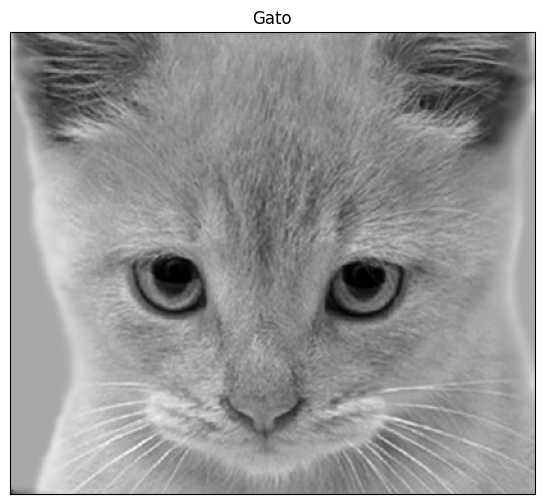

In [ ]:
img=cv2.imread(get_image('cat.bmp'),0).astype(np.float32)
displayIm(img,'Gato')

La misión principal de escoger **sigmaS** es eliminar ruido de la imagen. La foto es una foto bastante suave y el pelaje del gato hace que sea complicado detectar algunos bordes. Además no parece haber mucho ruido. Vamos a ver cómo se comporta la imagen tras un suavizado leve.

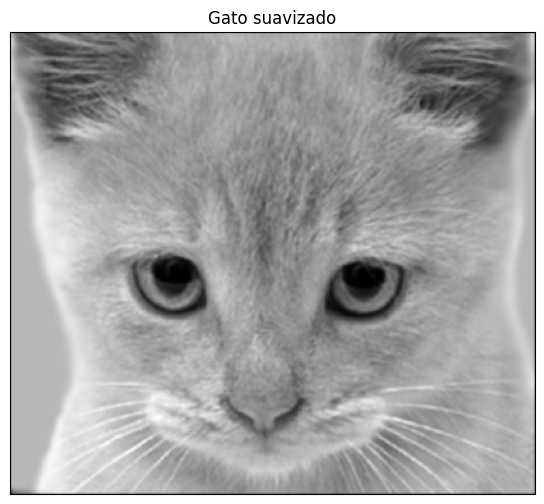

Error per pixel 4.890563


In [ ]:
sigma = 0.75
kernel = gaussianMask1D(sigma=sigma, sizeMask=0, order=0)
gato_smooth = convolve2D(img, kernel, kernel)
displayIm(gato_smooth,'Gato suavizado')
print('Error per pixel',np.sqrt(np.mean((img - np.round(gato_smooth)) ** 2)))

Como se puede observar, la imagen es bastante similar y el valor aportado por el RMSE no es muy alto, vamos a aumentar el sigma para ver si eliminamos ruido o por contrario perdemos detalle.

In [ ]:
sigmas = [0.75, 1.5, 3.0, 6.0]

for sigma in sigmas:
  kernel = gaussianMask1D(sigma=sigma, sizeMask=0, order=0)
  gato_smooth = convolve2D(img, kernel, kernel)
  print('Error per pixel para sigma {}'.format(sigma),np.sqrt(np.mean((img - np.round(gato_smooth)) ** 2)))

Error per pixel para sigma 0.75 4.890563
Error per pixel para sigma 1.5 9.199599
Error per pixel para sigma 3.0 13.602067
Error per pixel para sigma 6.0 18.829596


Lo que nos dice esto es que probablemente no estemos reduciendo ruido sino que estamos perdiendo detalles al suavizar de más. Esto coincide con el visualizado de la imagen y de la imagen con suavizado muy ligero. Vamos a tomar un sigma más pequeño para eliminar un poco de ruido.

In [ ]:
sigma = 0.5
kernel = gaussianMask1D(sigma=sigma, sizeMask=0, order=0)
gato_smooth = convolve2D(img, kernel, kernel)
print('Error per pixel para sigma {}'.format(sigma),np.sqrt(np.mean((img - np.round(gato_smooth)) ** 2)))

Error per pixel para sigma 0.5 2.2179518


Como se puede comprobar, con un sigma bajo realizamos una reducción de ruido de manera que la imagen no varía apenas. Vamos a visualizar ahora la imagen suavizada para la elección de **sigmaG**.

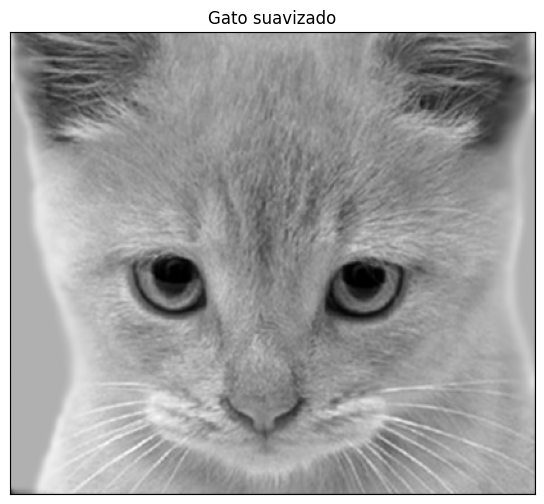

In [ ]:
displayIm(gato_smooth,'Gato suavizado')

Se puede observar como la imagen es ciertamente difusa en el sentido de que el pelaje del gato hace que no se termine de apreciar los bordes del cráneo, nariz, morro y otros elementos. Quizá solo los ojos están claramente delimitados. Entonces debemos buscar un **sigmaG** de modo que se realcen los bordes.

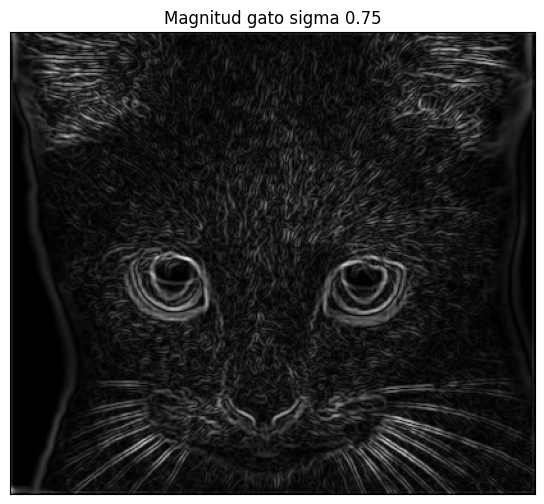

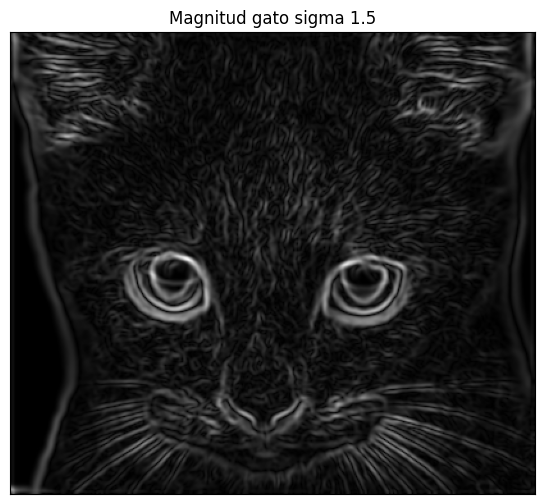

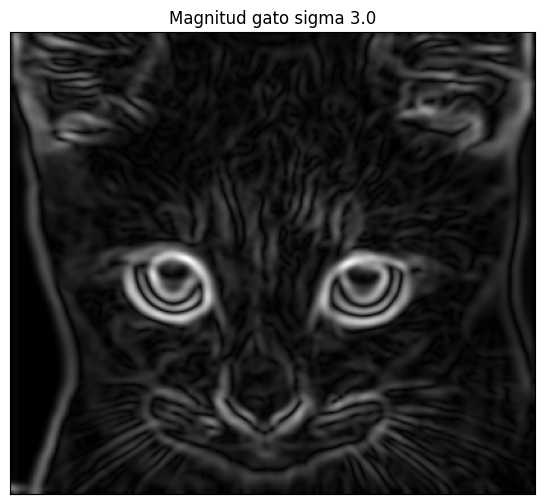

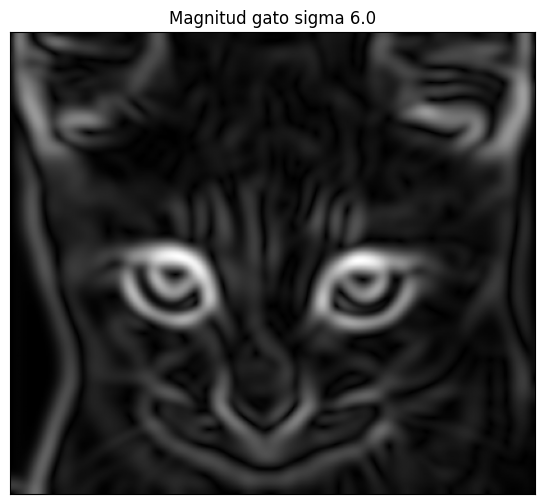

In [ ]:
sigmas = [0.75, 1.5, 3.0, 6.0]

for sigma in sigmas:
  mag_gato = magnitud(gato_smooth, sigma)
  displayIm(mag_gato,'Magnitud gato sigma {}'.format(sigma))

Si nos fijamos en la evolución de la imagen, vemos que cuanto más aumenta sigma más se realzan los bordes relativos a parte del cráneo del gato (bordes gruesos) y se realzan menos el pelo (bordes finos). Además, se da cierto difuminado de la imagen cuanto más aumenta sigma. Entonces, parece razonable quedarse con un valor entre 1.5 y 3.0 que son los valores donde se ven los bordes gruesos pero tampoco se difumina demasiado la imagen. Buscamos un punto intermedio porque para sigma = 1.5 quizá se realza demasiado el pelo del gato y poco el contorno de ciertos elementos y para sigma = 3.0 quizá es una imagen muy difuminada.

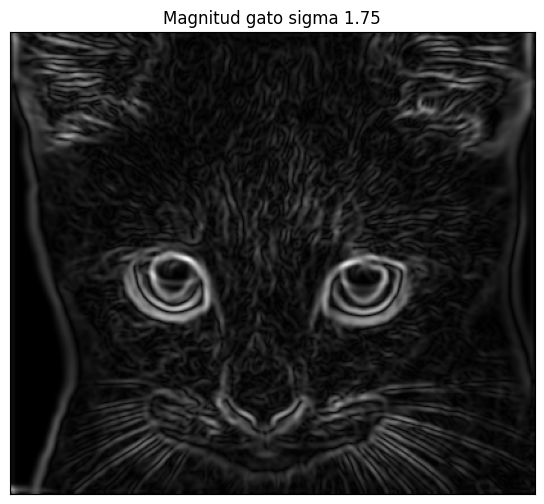

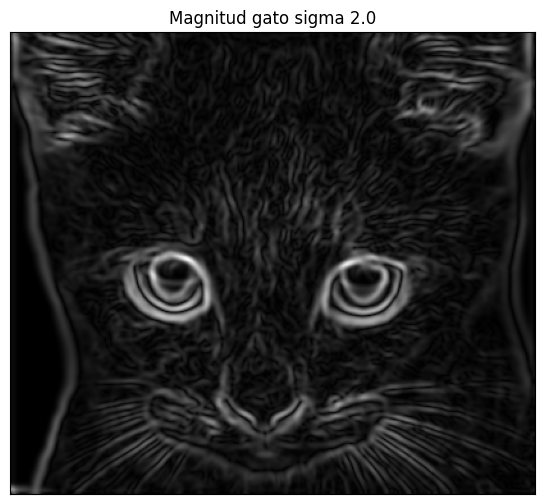

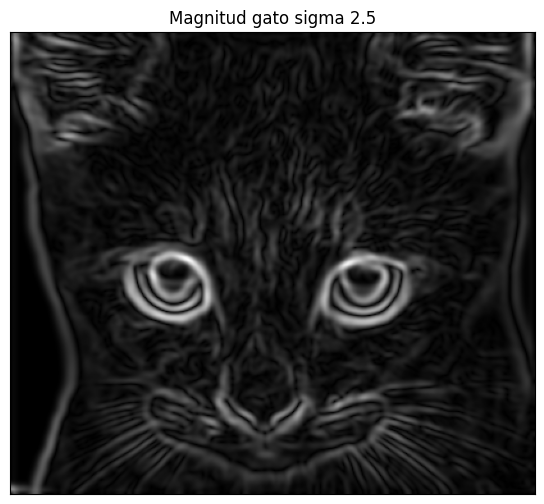

In [ ]:
sigmas = [ 1.75, 2.0, 2.5]

for sigma in sigmas:
  mag_gato = magnitud(gato_smooth, sigma)
  displayIm(mag_gato,'Magnitud gato sigma {}'.format(sigma))

Las tres imágenes son bastante similares y nos vamos a quedar con **sigmaG = 2.0** que realza bordes un poco más que 1.75 y se difumina menos que 2.5.

Una vez seleccionado ambos sigmas, vamos a pasar a aplicar nuestro detector canny. Todavía falta por determinar los umbrales **low** y **high**. Para ello vamos a empezar fijándolos a 10 y 20 y vamos a ver su evolución ante los cambios.

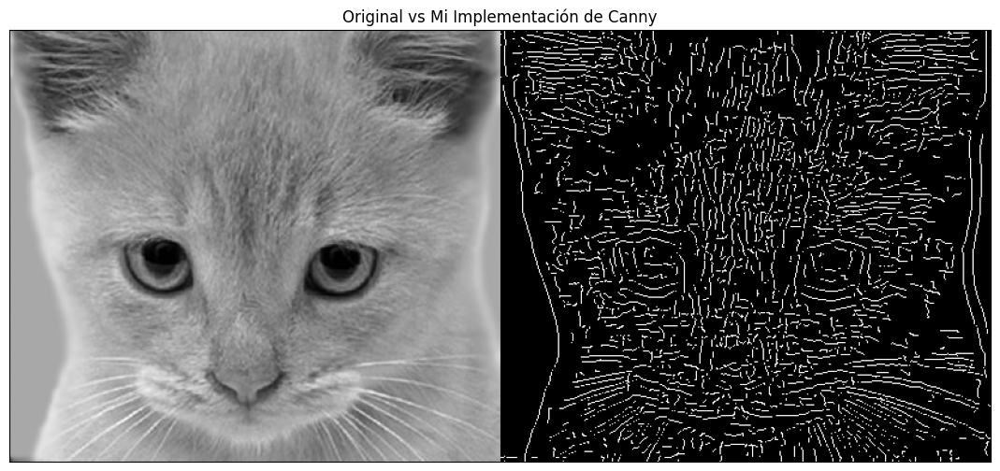

In [ ]:
def my_canny(img, low_thresh, high_thresh, sigmaGradient, sigmaSmoothing):
    #A CUBRIR POR EL ALUMNADO
    s_img = my2DConv(img, sigma= sigmaSmoothing, orders=[0,0])
    dx, dy, mag, ang = gradient_and_angle(s_img, sigmaGradient)
    nms = non_maximum_suppression(mag, ang)
    edges = double_threshold_and_hysteresis_fast(nms, low_thresh, high_thresh)
    return nms, edges




low = 10
high = 20
sigmaG = 2.0
sigmaS = 0.5
nms, edges = my_canny(img, low_thresh=low, high_thresh=high, sigmaGradient=sigmaG, sigmaSmoothing = sigmaS)

displayMI_ES([rangeDisplay01(img), rangeDisplay01(edges)], title='Original vs Mi Implementación de Canny')

Como vemos, para estos valores se marcan los bordes relativos a las partes del cráneo del gato, pero también la gran mayoría del pelaje se detecta como borde. Vamos a comparar nuestra imagen con el detector canny de openCV.

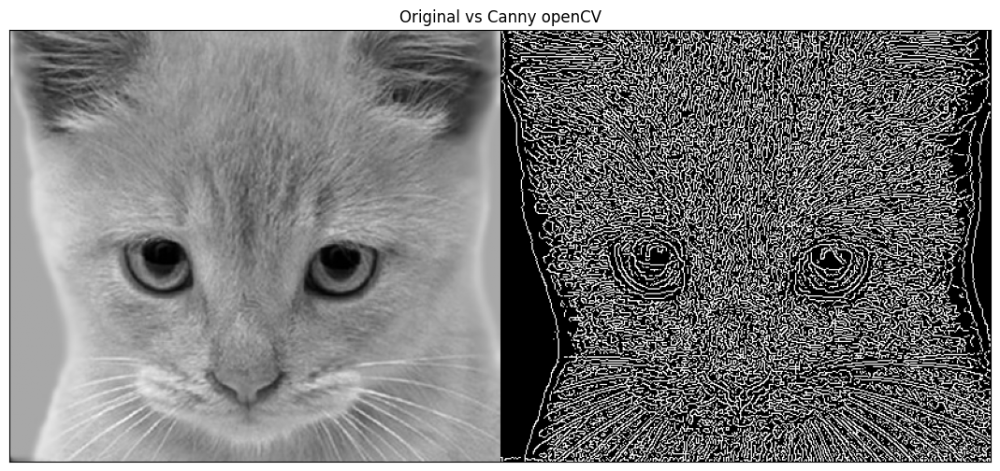

In [ ]:
img_uint8=cv2.imread(get_image('cat.bmp'),0)
edges = cv2.Canny(img_uint8,10,20)
displayMI_ES([rangeDisplay01(img), rangeDisplay01(edges)], title='Original vs Canny openCV')

Como se puede comprobar, para **low = 10 y high = 20** canny de openCV resalta bastantes más bordes. Aun así  vemos que la forma de los bordes es bastante similar. Ahora vamos a probar a variar los umbrales low y high y ver qué resultados obtenemos.

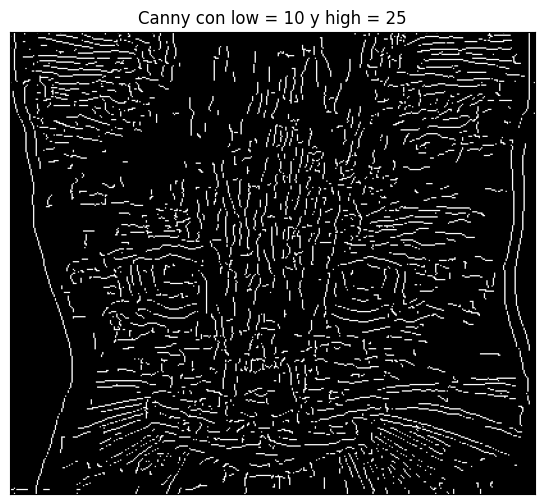

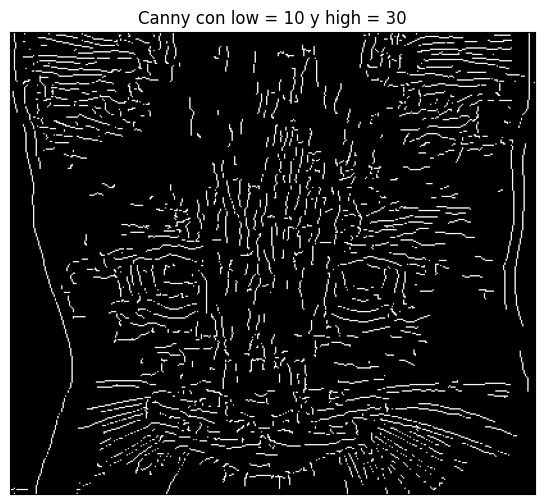

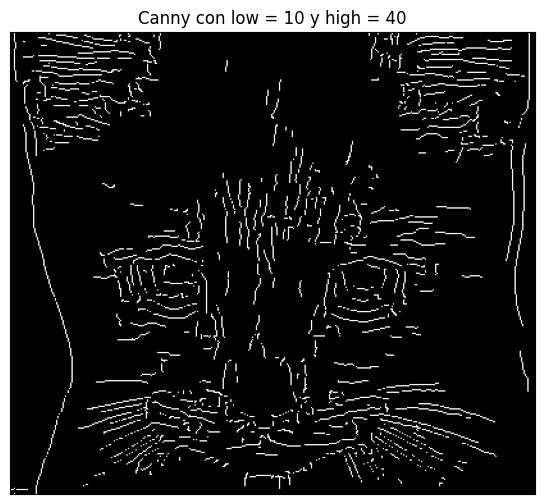

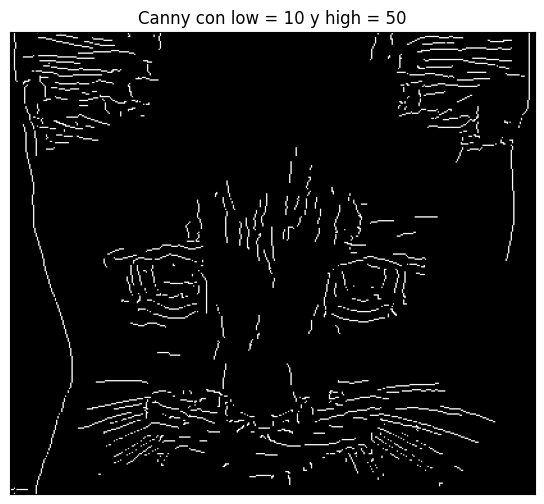

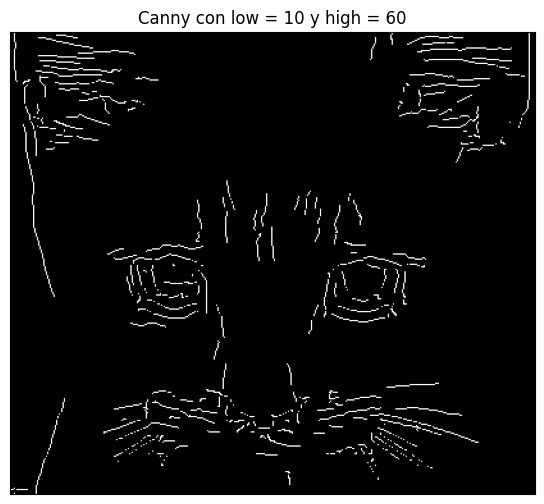

...

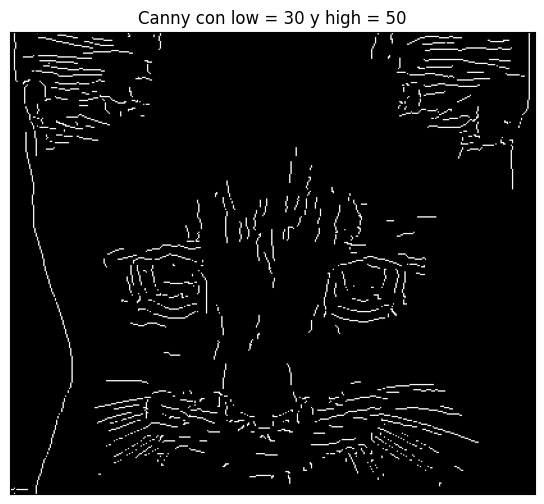

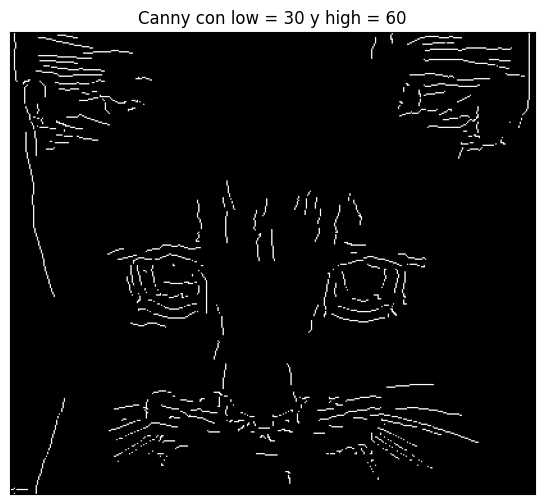

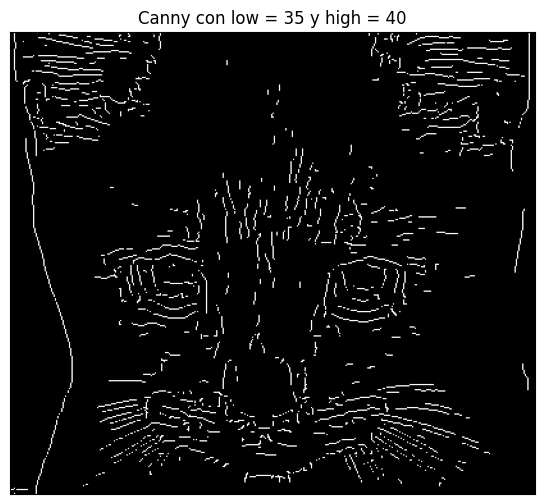

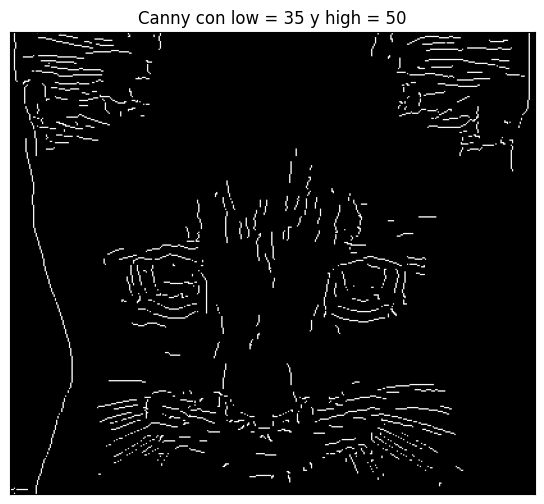

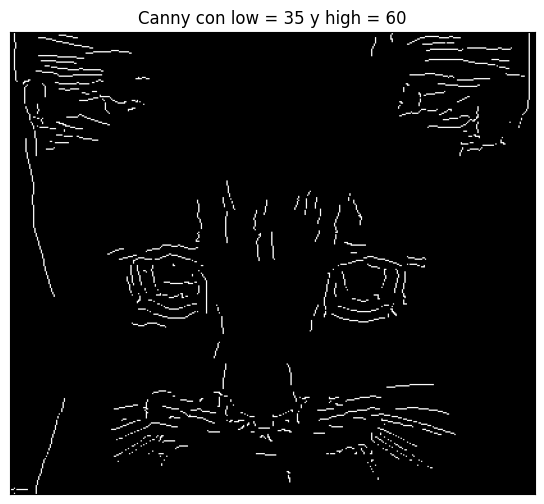

In [ ]:
lows = [10, 20, 30, 35]
highs = [25, 30, 40, 50, 60]

for low in lows:
  for high in highs:
    if( low < high):
      nms, edges = my_canny(img, low_thresh=low, high_thresh=high, sigmaGradient=sigmaG, sigmaSmoothing = sigmaS)
      displayIm(edges,'Canny con low = {} y high = {}'.format(low, high))

Como vemos, cuanto más bajo el threshold **low**, mayor cantidad de pelaje ( bordes finos ) vemos del gato y cuanto mayor es el threshold **high** más bordes gruesos se eliminan. Quizá la imagen que más respeta el contorno del gato y los elementos de la cara es para **low = 20 y high = 40**, aunque se siguen manteniendo parte del pelaje y el contorno de la cabeza no es del todo continuo, pero es normal, la imagen original es muy difusa.

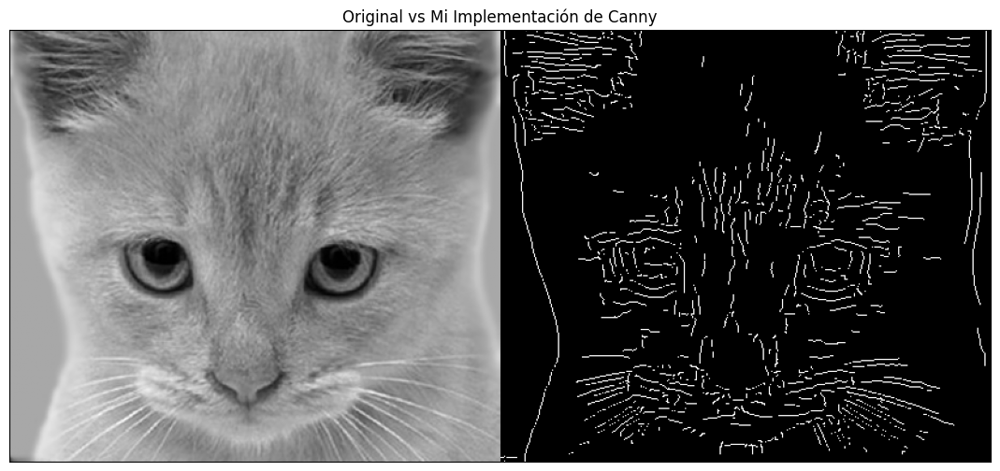

In [ ]:
low = 20
high = 40
sigmaG = 2.0
sigmaS = 0.5
nms, edges = my_canny(img, low_thresh=low, high_thresh=high, sigmaGradient=sigmaG, sigmaSmoothing = sigmaS)

displayMI_ES([rangeDisplay01(img), rangeDisplay01(edges)], title='Original vs Mi Implementación de Canny')

Se procede ahora a comprobar como varía nuestra imagen pero esta vez tocando los parámetros **sigmaSmooth y sigmaGradient**.

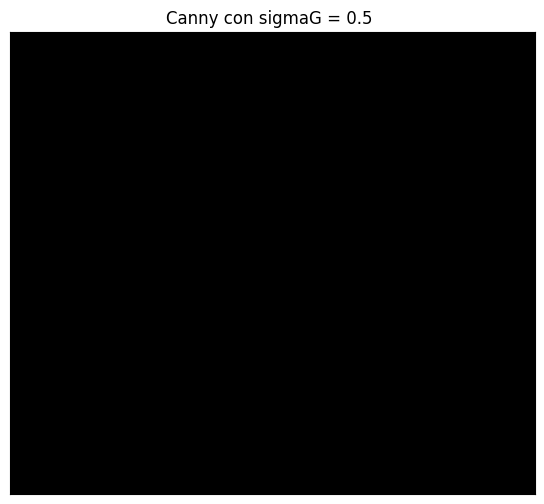

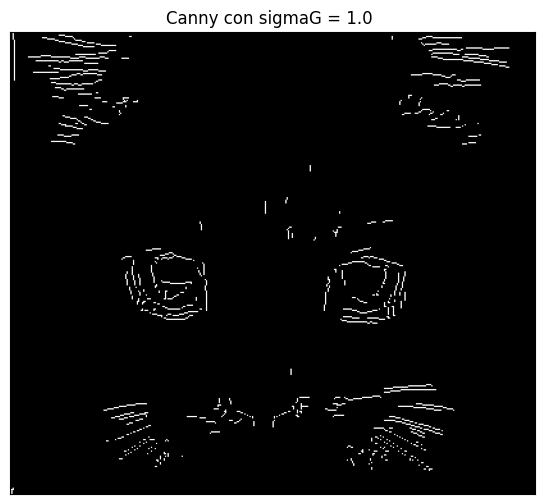

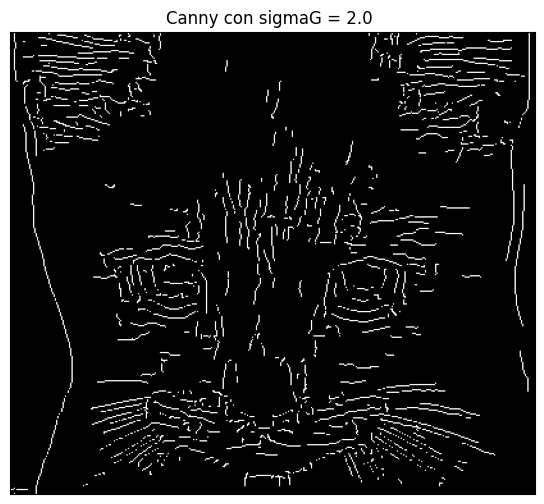

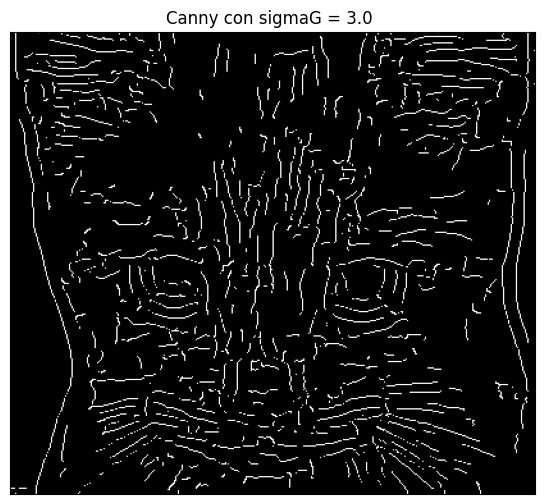

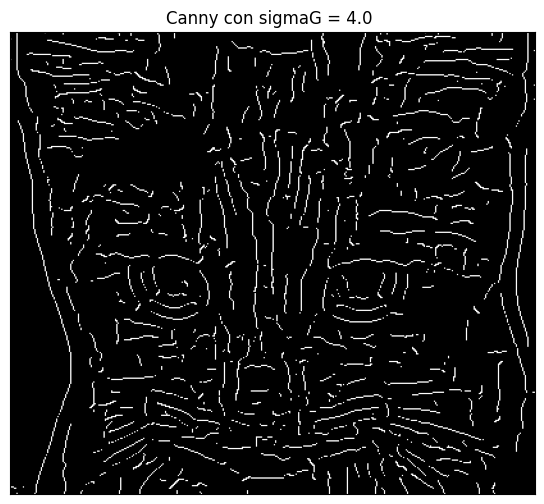

In [ ]:
low = 20
high = 40
sigmaGs = [0.5, 1.0, 2.0, 3.0, 4.0]
sigmaS = 0.5
for sigmaG in sigmaGs:
  nms, edges = my_canny(img, low_thresh=low, high_thresh=high, sigmaGradient=sigmaG, sigmaSmoothing = sigmaS)
  displayIm(edges,'Canny con sigmaG = {} '.format(sigmaG))

Se observa que a medida de que se aumenta sigmaG, desaparecen bordes muy finos pero aparecen otros bordes que no aparecían para sigmas más bajos, esto puede ser por el mayor suavizado que aplica al gradiente un valor de sigmaG mayor. Además, la selección de **sigmaG = 2.0** parece razonable por destacar bordes relativos a partes de la cabeza del gato en lugar de pelaje.

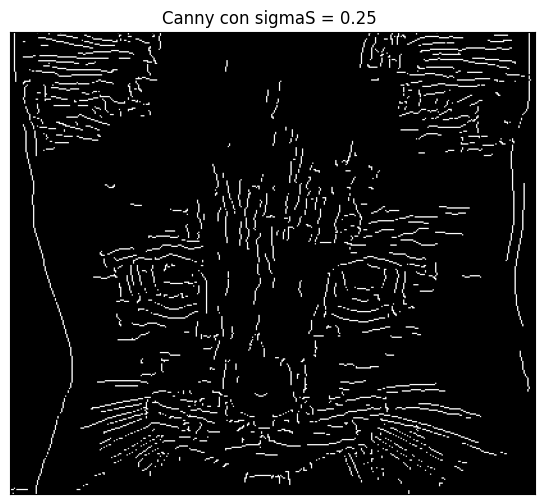

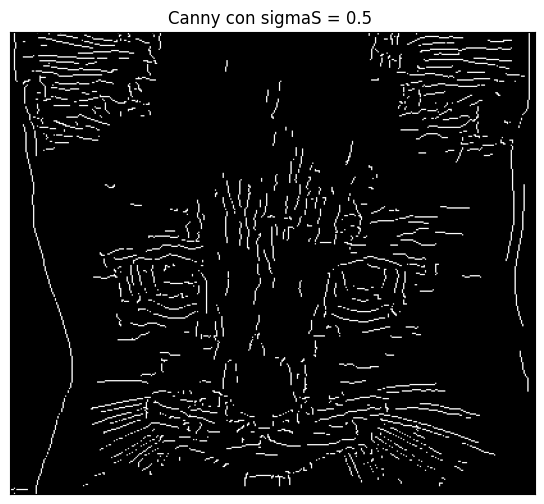

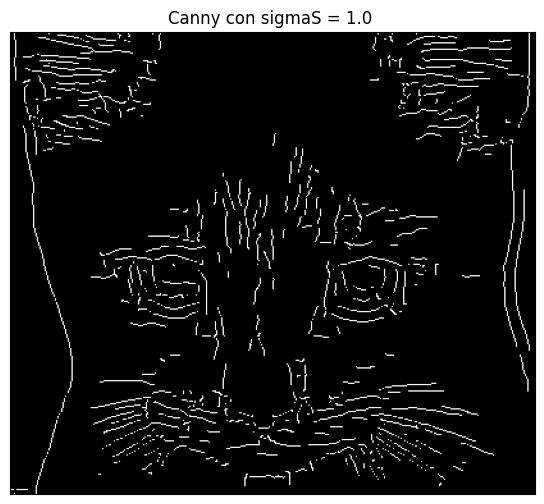

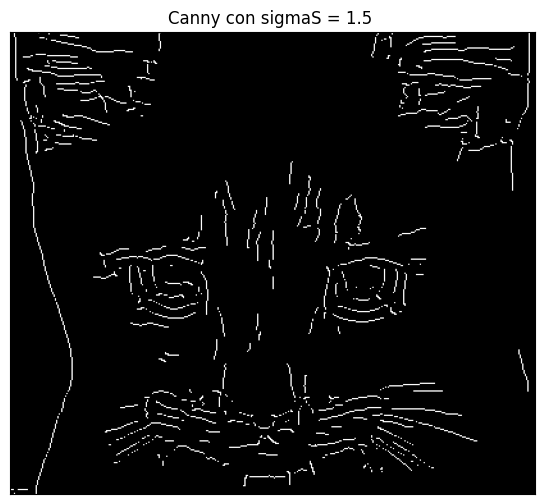

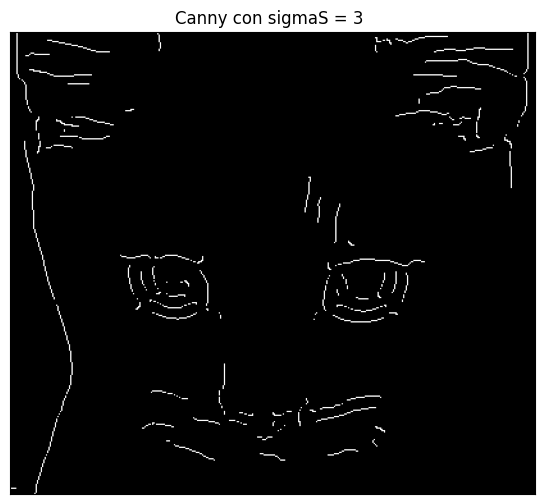

In [ ]:
low = 20
high = 40
sigmaG = 2.0
sigmasS = [0.25, 0.5, 1.0, 1.5, 3]
for sigmaS in sigmasS:
  nms, edges = my_canny(img, low_thresh=low, high_thresh=high, sigmaGradient=sigmaG, sigmaSmoothing = sigmaS)
  displayIm(edges,'Canny con sigmaS = {} '.format(sigmaS))

Como vemos, a mayor valor de sigmaS más bordes desaparecen. Esto es porque suavizamos más la imagen y  se difuminan más los bordes ( en una imagen de por sí bastante difusa ). Parece correcto la elección de **sigmaS = 0.5**. Por último, vamos a ver si conseguimos acercarnos a nuestra imagen con nuestro canny utilizando la función canny de openCV variando sus parámetros.

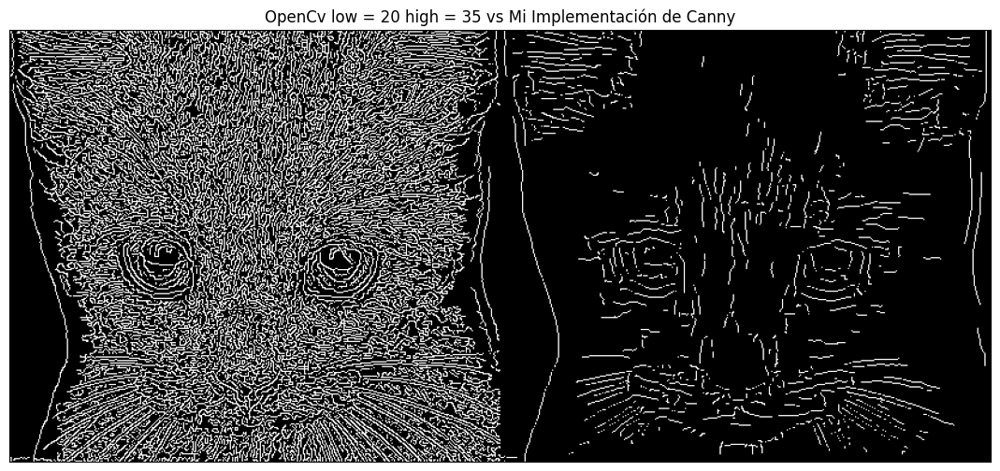

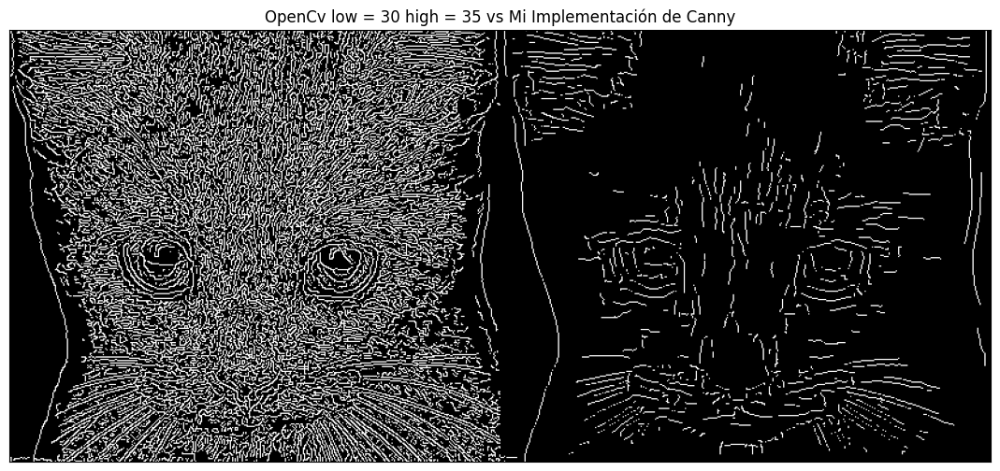

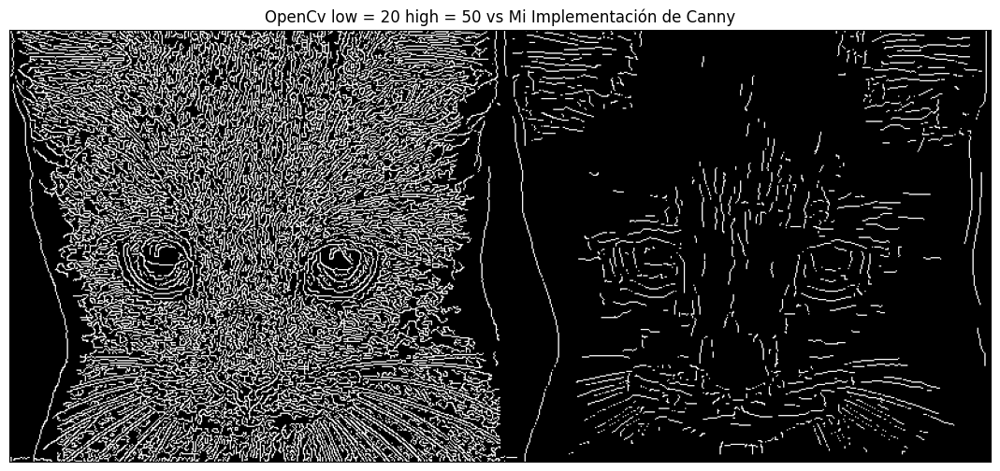

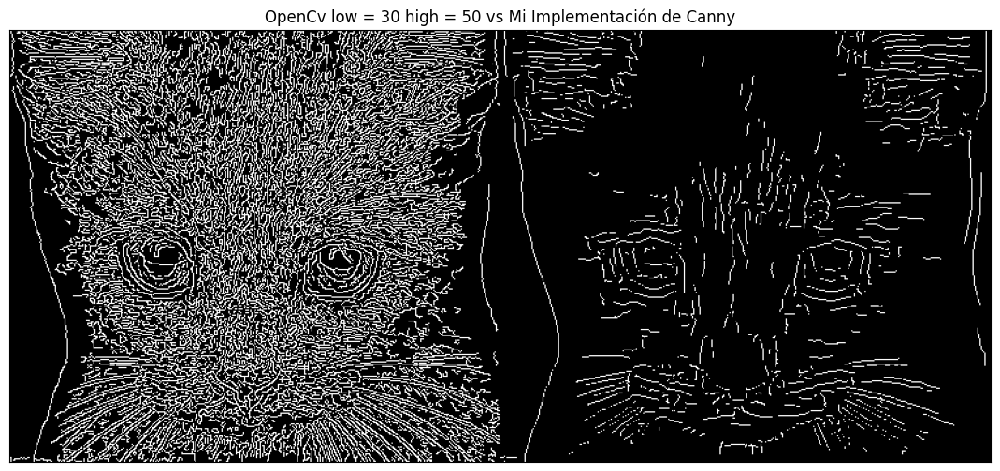

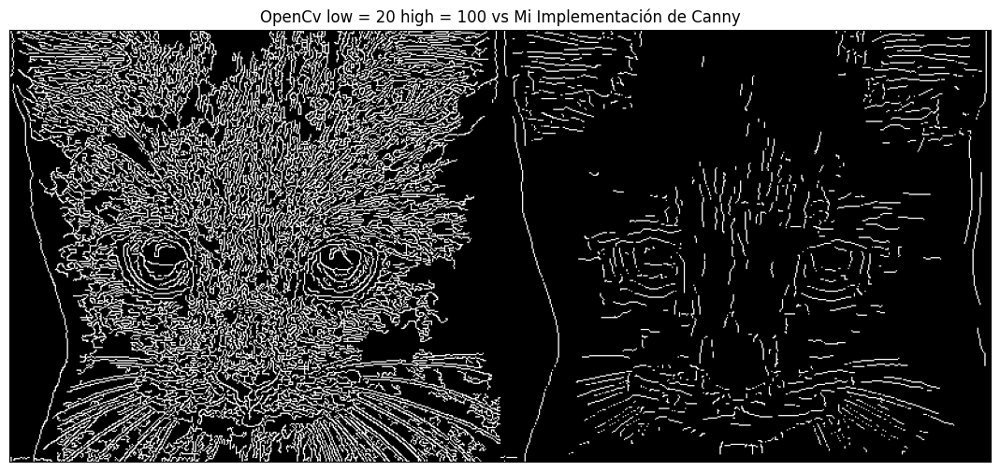

...

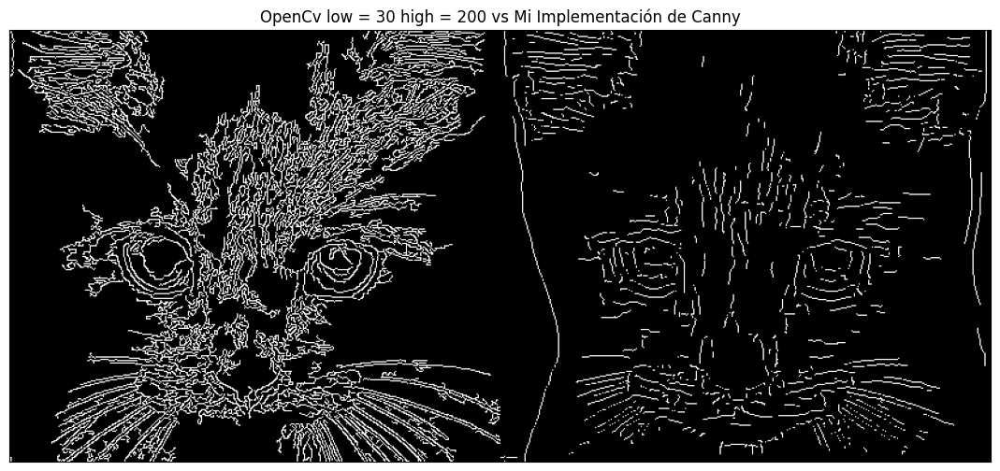

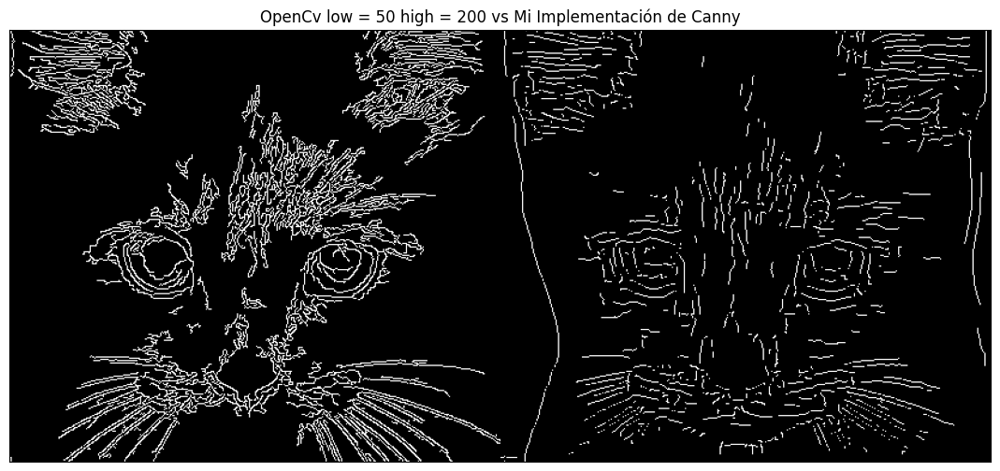

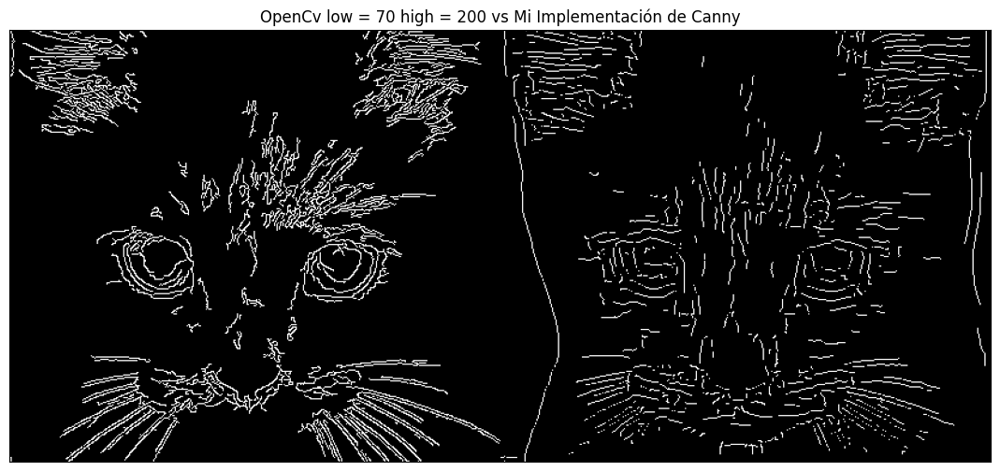

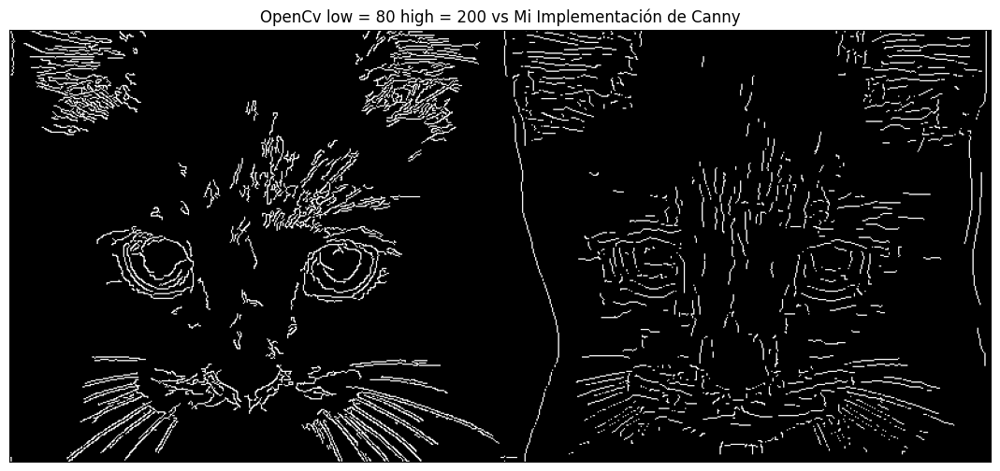

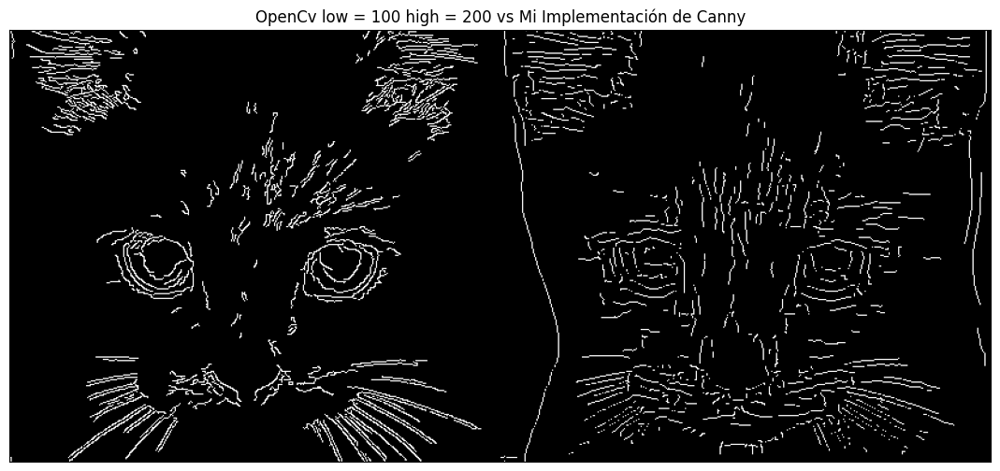

In [ ]:
low = 20
high = 40
sigmaG = 2.0
sigmaS = 0.5
nms, edges = my_canny(img, low_thresh=low, high_thresh=high, sigmaGradient=sigmaG, sigmaSmoothing = sigmaS)

lows = [20, 30, 50, 70, 80 ,100]
highs = [35, 50, 100, 150, 200]

for high_cv in highs:
  for low_cv in lows:
    if( low_cv < high_cv):
      edges_opencv = cv2.Canny(img_uint8, low_cv, high_cv)
      displayMI_ES([rangeDisplay01(edges_opencv), rangeDisplay01(edges)],
                   title='OpenCv low = {} high = {} vs Mi Implementación de Canny'.format(low_cv, high_cv))

Probando estos valores, comprobamos que los resultados que aporta canny de openCV son bastante diferentes a los obtenidos con nuestra función. Quizá lo más parecido es para **threshold1 = 30 y threshold2 = 35** por el contorno del gato, pero la cantidad de pelaje es sustancialmente superior. Si intentamos aumentar el segundo threshold eliminamos este pelaje pero también el contorno del cráneo.

Tras revisar la implementación de canny de openCV vemos por ejemplo que la implementación es diferente como en el cálculo de gradientes se hace con Sobel en lugar de nuestros filtros a partir de derivadas de gaussiana y quizá por esto las diferencias.




